# Project Management

## 📖 librairies

In [1]:
# python generic
import pandas as pd
import numpy as np
from pathlib import Path
import os

## plots
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

# brightway
import bw2data as bd
import bw2calc as bc
import bw2io as bi

# bw-functional (multifunctional SQLite backend)
import bw_functional
from bw2data.signals import project_changed

# ------------------------------------------------------------
# bw_functional compat patch (TypeError on bd.projects.set_current)
# ------------------------------------------------------------
# bw_functional connects project_changed to _check_and_update(dataset),
# but blinker calls receivers as receiver(sender, **kwargs): the sender
# is bound positionally to 'dataset' and the 'dataset' keyword then
# collides -> TypeError: _check_and_update() got multiple values for
# argument 'dataset'. Disconnect the buggy handler and reconnect a
# signature-compatible one.
try:
    project_changed.disconnect(bw_functional._check_and_update)
except (TypeError, KeyError):
    pass

if not hasattr(bw_functional, "_check_and_update_patched"):

    def _check_and_update_patched(sender, dataset=None, **kwargs):
        if dataset is None:
            return
        if dataset.data is None:
            dataset.data = {}
            dataset.save()
        current = dataset.data.get("bw_functional_version")
        if current != bw_functional.latest:
            from loguru import logger
            logger.info(
                f"Updating {dataset} to latest bw_functional "
                f"datastructure version {bw_functional.latest}"
            )
            dataset.data["bw_functional_version"] = bw_functional.update(current)
            dataset.save()

    bw_functional._check_and_update_patched = _check_and_update_patched

project_changed.connect(bw_functional._check_and_update_patched)


c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\__init__.py:59: UserWarning: No fast sparse solver found
  warnings.warn("No fast sparse solver found")


14:31:08+0100 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


<function __main__._check_and_update_patched(sender, dataset=None, **kwargs)>

## restore back-ups

In [2]:
backup_dir = r"C:\Users\lfreboeuf\Documents\1B_work_projects\11_liege_perocillo\2026\lca"

In [3]:
# import bw2data as bd
# import bw2io as bi
# from pathlib import Path

# # Path to your backup file
# backup_path = Path(r"C:\Users\lfreboeuf\Documents\CyVi_cloud\Review_RA\Application\lca\brightway2-project-RA_ei-3.12-backup20-May-2026-10-22AM.tar.gz")

# # Create a new project name (clean, uncorrupted)
# new_project_name = "RA_ei-3.12_restored"

# print(f"Restoring backup to new project: {new_project_name}")
# print(f"Backup file: {backup_path}")
# print(f"Backup exists: {backup_path.exists()}")

# # Restore the backup as a new project
# try:
#     restored_name = bi.backup.restore_project_directory(
#         fp=str(backup_path),
#         project_name=new_project_name,
#         overwrite_existing=False,  # Don't overwrite if exists
#         switch=True  # Switch to this project after restore
#     )
#     print(f"\n✓ Project successfully restored as: {restored_name}")
#     print(f"Current project: {bd.projects.current}")
    
# except Exception as e:
#     print(f"Error during restore: {e}")
#     print("\nTrying alternative method...")
    
#     # Alternative method: manual extraction
#     import tarfile
#     import shutil
    
#     brightway_dir = Path(bd.config.data_dir) # type: ignore
#     projects_dir = brightway_dir / "projects"
#     new_project_dir = projects_dir / new_project_name
    
#     # Create new project directory
#     new_project_dir.mkdir(parents=True, exist_ok=True)
    
#     # Extract backup
#     with tarfile.open(backup_path, "r:gz") as tar:
#         tar.extractall(path=new_project_dir)
    
#     # Register the project
#     bd.projects._load() # type: ignore
#     bd.projects.set_current(new_project_name)
#     print(f"✓ Project manually restored as: {new_project_name}")

## ▶️ starts

In [4]:
bd.projects.set_current("RA_ei-3.12_onlybw")

# 📝 LCI creations

The three transcriptions (system, process, product) share the same
helper functions and inputs (cell "functions"): each transcription cell only
points the `current_*` variables at its own foreground/biosphere databases,
so every LCIA method created below can address each of the created foreground
inventories.

## 📖 specific libraries

In [5]:
import os
import difflib
import pandas as pd
import bw2data as bd
import bw2io as bi
import wurst as w

## ecoinvent management

In [6]:
username = os.getenv("EI_USERNAME")
password = os.getenv("EI_PASSWORD")
syst_mod = "cutoff"
db_version = "3.12"
db_provider = "ecoinvent"
background_db_name = f"{db_provider}-{db_version}-{syst_mod}"

# Import ecoinvent if needed
if background_db_name not in bd.databases:
    print(f"Importing ecoinvent {db_version} ({syst_mod})...")
    bi.import_ecoinvent_release(
        username=username,
        password=password,
        system_model=syst_mod,
        version=db_version,
    )
else:
    print(f"Database '{background_db_name}' already exists.")
    
# Load databases
background_db = bd.Database(background_db_name)
background_biosphere_db_name = f"{db_provider}-{db_version}-biosphere"
background_biosphere_db = bd.Database(background_biosphere_db_name)
foreground_db_name = "hydromet_sqlite"


Database 'ecoinvent-3.12-cutoff' already exists.


## functions

In [23]:
# ============================================================
# Shared functions for ALL transcription types (system / process / product)
# ============================================================
# The ONLY state that differs between transcription cells is the
# "current_*" pointers, set by init_transcription(). Everything else
# (foreground data, custom biosphere, writing, allocation) is driven
# by the common dictionaries cell and these shared functions.

try:
    import bw_functional
except ImportError:
    bw_functional = None  # required only for the product-type transcription

background_biosphere_db_name = f"{db_provider}-{db_version}-biosphere"
background_biosphere_db = bd.Database(background_biosphere_db_name)

# Flows that must be linked to the ecoinvent biosphere instead of the custom one
ECOINVENT_LINKED_FLOWS = {
    "Carbon dioxide, fossil",
    "Heat, waste",
    "Hydrogen fluoride",
    "Sulfur dioxide",
    "Water",                             # u2_leaching (cubic meter)
    "Water, unspecified natural origin",  # u3/u5/u6/u9 (natural resource, in ground)
}


def get_or_create_biosphere_flow(flow_name, unit, biosphere_db, biosphere_db_name,
                                 custom_biosphere_flows, custom_biosphere_name, categories=None):
    """Return (database_name, code) for a biosphere flow.
    Priority: 1. ecoinvent biosphere (ECOINVENT_LINKED_FLOWS),
    2. already-created custom flow, 3. new custom flow (batch writing)."""
    if flow_name in ECOINVENT_LINKED_FLOWS:
        eco_flows = [act for act in list(biosphere_db) if act['name'] == flow_name]
        if categories is not None:
            matched = [act for act in eco_flows if tuple(act['categories']) == tuple(categories)]
        else:
            matched = eco_flows
        if matched:
            flow = matched[0]
            print(f"🔗 Linked '{flow_name}' to ecoinvent biosphere ({biosphere_db_name})")
            return biosphere_db_name, flow.key[1]
        if eco_flows:
            flow = eco_flows[0]
            print(f"⚠️  '{flow_name}': categories {categories} not found in ecoinvent, "
                  f"using default {tuple(flow['categories'])}")
            return biosphere_db_name, flow.key[1]
        raise ValueError(
            f"Flow '{flow_name}' was expected in ecoinvent biosphere "
            f"'{biosphere_db_name}' but was not found."
        )

    if flow_name in custom_biosphere_flows:
        if categories is not None and custom_biosphere_flows[flow_name]['categories'] != categories:
            custom_biosphere_flows[flow_name]['categories'] = categories
        return custom_biosphere_name, custom_biosphere_flows[flow_name]['code']

    new_code = f"custom_{flow_name.replace(' ', '_')}"
    new_flow = {
        'name': flow_name, 'unit': unit, 'categories': categories or (),
        'code': new_code, 'database': custom_biosphere_name, 'type': 'biosphere'
    }
    custom_biosphere_flows[flow_name] = new_flow
    return custom_biosphere_name, new_code


def add_biosphere_exchange(process, flow_name, amount, unit, categories=None, exergy=None):
    db_name_flow, code = get_or_create_biosphere_flow(
        flow_name, unit, background_biosphere_db, background_biosphere_db_name,
        current_custom_biosphere_flows, current_biosphere_db_name, categories
    )
    exc = {
        "name": flow_name, "unit": unit, "amount": amount,
        "type": "biosphere", "input": (db_name_flow, code), "properties": {}
    }
    if exergy is not None:
        exc["properties"]["exergy"] = exergy
    process['exchanges'].append(exc)


def search_ecoinvent(database, material, country_code="BE", track_unfound=True):
    """Search a material in ecoinvent. Returns ([activity], found_bool).
    Priority: exact name match, then location BE > RER > RoW > GLO."""
    candidates = [act for act in list(database) if material.lower() in act['name'].lower()]
    if not candidates:
        return [], False
    exact_matches = [act for act in candidates if act['name'] == material]
    candidates_to_use = exact_matches if exact_matches else candidates

    def get_priority(act):
        loc = act['location'].upper()
        if country_code.upper() in loc:
            return 0
        elif 'RER' in loc:
            return 1
        elif 'ROW' in loc:
            return 2
        elif 'GLO' in loc:
            return 3
        else:
            return 4

    return [min(candidates_to_use, key=get_priority)], True


def add_technosphere_exchange(process, material, amount, unit, location_priority="BE"):
    results, found = search_ecoinvent(background_db, material, location_priority)
    if found:
        act = results[0]
        process['exchanges'].append({
            "name": act['name'], "unit": unit, "location": act['location'],
            "amount": amount, "type": "technosphere",
            "input": (background_db_name, act['code']), "properties": {}
        })
        return True
    print(f"  ❌ Technosphere flow not found: {material}")
    return False


def add_production_exchange(process, product_name, amount, input_code,
                            location="BE", unit="unit", product_field=True, exergy=None):
    """Production exchange for ALL transcriptions:
    - system/process: input_code = the process code itself (unit "unit")
    - product: input_code = the bw-functional product node code (kilogram)"""
    exc = {
        "name": product_name, "unit": unit, "location": location,
        "amount": amount, "type": "production",
        "input": (current_foreground_db_name, input_code), "properties": {}
    }
    if product_field:
        exc["product"] = product_name
    if exergy is not None:
        exc["properties"]["exergy"] = exergy
    process['exchanges'].append(exc)


def add_foreground_product_exchange(process, flow_name, amount,
                                    location="BE", unit="kilogram"):
    """Technosphere exchange consuming a real foreground product (in
    KILOGRAM) produced by another unit process of THIS database."""
    process['exchanges'].append({
        "name": flow_name, "unit": unit, "location": location,
        "amount": amount, "type": "technosphere",
        "input": (current_foreground_db_name, flow_name)
    })


def create_product_node(flow_name, processor_code, exergy, mass,
                        location="BE", unit="kilogram"):
    """bw-functional product node: one real product flow (f_x-y) of
    sea.xlsx, produced by its processor, carrying exergy (allocation)
    and mass as properties (per-FU totals, hence normalize=False)."""
    return {
        "database": current_foreground_db_name,
        "type": "product",
        "code": flow_name,
        "name": flow_name,
        "unit": unit,
        "location": location,
        "processor": (current_foreground_db_name, processor_code),
        "properties": {
            "exergy": {"unit": "megajoule", "amount": exergy, "normalize": False},
            "mass": {"unit": "kilogram", "amount": mass, "normalize": False}
        }
    }


def create_process(process_code, reference_product, exchanges_data,
                   products=None, foreground_inputs=None, location="BE",
                   allocation=None, product_nodes=False, product_unit="unit"):
    """Unified process builder for ALL transcriptions.
    Returns (process, product_nodes_created).
      products           : list of (name, amount, exergy) production exchanges
                           - system/process (product_nodes=False): the
                             production exchange points to the process itself
                           - product (product_nodes=True): each production
                             exchange points to a bw-functional product node
                             carrying mass + exergy properties
      foreground_inputs  : list of (flow_name, amount_kg) consumed from the
                           other unit processes (product transcription only)
      exchanges_data     : background inputs + natural-environment outputs
                           (from the common dictionaries)"""
    process = {
        "database": current_foreground_db_name,
        "type": "process",
        "code": process_code,
        "name": process_code,
        "reference product": reference_product,
        "unit": product_unit,
        "location": location,
        "exchanges": []
    }
    if allocation is not None:
        process["allocation"] = allocation

    new_product_nodes = []
    for product_name, amount, exergy in (products or []):
        if product_nodes:
            add_production_exchange(process, product_name, amount, product_name,
                                    location, product_unit, product_field=False)
            new_product_nodes.append(
                create_product_node(product_name, process_code, exergy, amount,
                                    location, product_unit)
            )
        else:
            add_production_exchange(process, product_name, amount, process_code,
                                    location, product_unit, product_field=True,
                                    exergy=exergy)

    for exc in exchanges_data:
        if exc['type'] == 'technosphere':
            add_technosphere_exchange(process, exc['name'], exc['amount'], exc['unit'])
        elif exc['type'] == 'biosphere':
            add_biosphere_exchange(process, exc['name'], exc['amount'], exc['unit'],
                                   exc.get('categories'), exc.get('exergy'))

    for flow_name, amount in (foreground_inputs or []):
        add_foreground_product_exchange(process, flow_name, amount, location)

    return process, new_product_nodes


def init_transcription(transcription_type):
    """Common prelude: db names, current_* pointers, clean custom biosphere."""
    global current_foreground_db_name, current_biosphere_db_name, current_custom_biosphere_flows
    foreground_db_name_t = f"{foreground_db_name}_{transcription_type}"
    biosphere_db_name_t = f"{foreground_db_name_t}_biosphere"
    current_foreground_db_name = foreground_db_name_t
    current_biosphere_db_name = biosphere_db_name_t
    if biosphere_db_name_t in bd.databases:
        print(f"Deleting existing custom biosphere: {biosphere_db_name_t}")
        del bd.databases[biosphere_db_name_t]
    custom_biosphere = bd.Database(biosphere_db_name_t)
    custom_biosphere.write({})
    custom_biosphere_flows = {}
    current_custom_biosphere_flows = custom_biosphere_flows
    return foreground_db_name_t, biosphere_db_name_t, custom_biosphere, custom_biosphere_flows


def finalize_transcription(foreground_db_name_t, biosphere_db_name_t,
                           custom_biosphere, custom_biosphere_flows,
                           data_foreground, functional=False):
    """Common epilogue: write the custom biosphere, write the foreground
    database (wurst, or bw-functional + explicit allocation), report."""
    if custom_biosphere_flows:
        print("Writing custom biosphere flows...")
        custom_biosphere.write(list(custom_biosphere_flows.values()))
        print(f"   ✅ Custom biosphere database '{biosphere_db_name_t}' "
              f"written with {len(custom_biosphere_flows)} new flows.")
    else:
        print("ℹ️  No custom biosphere flows needed – all flows found in ecoinvent.")

    if foreground_db_name_t in bd.databases:
        print(f"Deleting existing foreground database: {foreground_db_name_t}")
        del bd.databases[foreground_db_name_t]

    if functional:
        if bw_functional is None:
            raise ImportError(
                "bw-functional is required for the product-type transcription: "
                "pip install bw-functional"
            )
        functional_db = bw_functional.FunctionalSQLiteDatabase(foreground_db_name_t)
        functional_db.register(default_allocation="equal")
        functional_db.write(data_foreground)
        # bw-functional 0.1.0 does NOT allocate raw-written data
        # (allocation_factor unset -> treated as 1 -> double counting).
        # Allocate every process explicitly, then rebuild the matrices.
        for node in functional_db:
            if isinstance(node, bw_functional.Process):
                node.allocate()
        functional_db.process()
        print(f"\n✅ Multifunctional database '{foreground_db_name_t}' successfully created!")
    else:
        w.write_brightway2_database(data_foreground, name=foreground_db_name_t,
                                    products_and_processes=True)
        print(f"\n✅ Database '{foreground_db_name_t}' successfully created!")
        print(f"   Total processes: {len(bd.databases[foreground_db_name_t])}")

    if biosphere_db_name_t in bd.databases:
        print(f"   Custom biosphere database: '{biosphere_db_name_t}' contains "
              f"{len(bd.databases[biosphere_db_name_t])} flows.")
    print(f"\n✅ LCI build complete! Ecoinvent flows link to '{background_biosphere_db_name}'; "
          f"custom flows are in '{biosphere_db_name_t}'.")

## dictionaries

In [24]:
# ============================================================
# Common dictionaries: the single source of data for ALL transcriptions
# ============================================================

unit_processes = [
    "u10_precipitation", "u11_filtration-Li", "u12_wastewater-storage",
    "u1_BM-pulping", "u2_leaching", "u3_Ca(OH)2_pulp",
    "u4_purification", "u5_filtrate-impurities", "u6_NaOH_pulping",
    "u7_precipitation_trans-Me", "u8_filtration_trans-Me", "u9_NaCO3-pulping"
]

# Background inputs + natural-environment outputs of each unit process
# (identical in the system, process and product transcriptions)
unit_process_exchanges = {
    "u1_BM-pulping": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, external', 'amount': 0.155, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 0.5530338, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'Heat, waste', 'amount': 0.441936, 'unit': 'megajoule', 'categories': ('air',)},
        {'type': 'biosphere', 'name': 'Hydrogen fluoride', 'amount': 0.033, 'unit': 'kilogram', 'categories': ('air',)},
        {'type': 'biosphere', 'name': 'Waste EoL LiBs', 'amount': 1, 'unit': 'kilogram', 'categories': ('economy',), 'exergy': 12.2770764},
        {'type': 'technosphere', 'name': 'market for heat, from steam, in chemical industry', 'amount': 0.336384, 'unit': 'megajoule'},
        {'type': 'technosphere', 'name': 'market for steam, in chemical industry', 'amount': 0.1529, 'unit': 'kilogram'}
    ],
    "u2_leaching": [
        {'type': 'biosphere', 'name': 'Carbon dioxide, fossil', 'amount': 0.727, 'unit': 'kilogram', 'categories': ('air',)},
        {'type': 'biosphere', 'name': 'Exergy dissipation, external', 'amount': 16.599, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 4.493214, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'Heat, waste', 'amount': 36.779, 'unit': 'megajoule', 'categories': ('air',)},
        {'type': 'biosphere', 'name': 'Sulfur dioxide', 'amount': 2.394, 'unit': 'kilogram', 'categories': ('air',)},
        {'type': 'biosphere', 'name': 'Water', 'amount': 0.001714, 'unit': 'cubic meter', 'categories': ('air',)},
        {'type': 'technosphere', 'name': 'market for cooling energy', 'amount': 1.17115, 'unit': 'megajoule'},
        {'type': 'technosphere', 'name': 'market for sulfuric acid', 'amount': 6.627, 'unit': 'kilogram'}
    ],
    "u3_Ca(OH)2_pulp": [
        {'type': 'biosphere', 'name': 'Water, unspecified natural origin', 'amount': 0.0008, 'unit': 'cubic meter', 'categories': ('natural resource', 'in ground')},
        {'type': 'technosphere', 'name': 'market for hydrated lime, packed', 'amount': 0.98, 'unit': 'kilogram'}
    ],
    "u4_purification": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 1.1758245, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'technosphere', 'name': 'market for heat, from steam, in chemical industry', 'amount': 1.054, 'unit': 'megajoule'}
    ],
    "u5_filtrate-impurities": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 0.00657, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'Water, unspecified natural origin', 'amount': 0.001557, 'unit': 'cubic meter', 'categories': ('natural resource', 'in ground')},
        {'type': 'technosphere', 'name': 'market for bottom ash, MSWI, residue from shredder fraction from manual dismantling', 'amount': -2.225, 'unit': 'kilogram'}
    ],
    "u6_NaOH_pulping": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 0.4692238, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'Water, unspecified natural origin', 'amount': 0.000517, 'unit': 'cubic meter', 'categories': ('natural resource', 'in ground')},
        {'type': 'technosphere', 'name': 'market for heat, from steam, in chemical industry', 'amount': 13.102, 'unit': 'megajoule'},
        {'type': 'technosphere', 'name': 'market for sodium hydroxide, without water, in 50% solution state', 'amount': 0.423, 'unit': 'kilogram'}
    ],
    "u7_precipitation_trans-Me": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 0.42945, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'technosphere', 'name': 'market for cooling energy', 'amount': 0.00497, 'unit': 'megajoule'}
    ],
    "u8_filtration_trans-Me": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 1.08e-05, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'NMC hydroxide mixture', 'amount': 1.187, 'unit': 'kilogram', 'categories': ('economy',), 'exergy': 0.4326}
    ],
    "u9_NaCO3-pulping": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 0.001746, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'Water, unspecified natural origin', 'amount': 0.000356, 'unit': 'cubic meter', 'categories': ('natural resource', 'in ground')},
        {'type': 'technosphere', 'name': 'market for soda ash, light', 'amount': 0.291, 'unit': 'kilogram'}
    ],
    "u10_precipitation": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 0.0276723, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'technosphere', 'name': 'market for heat, from steam, in chemical industry', 'amount': 0.004968, 'unit': 'megajoule'}
    ],
    "u11_filtration-Li": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 0.2377, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'biosphere', 'name': 'Li2CO3 mixture', 'amount': 0.514, 'unit': 'kilogram', 'categories': ('economy',), 'exergy': 0.2006}
    ],
    "u12_wastewater-storage": [
        {'type': 'biosphere', 'name': 'Exergy dissipation, internal', 'amount': 0.000148, 'unit': 'megajoule', 'categories': ('economy',)},
        {'type': 'technosphere', 'name': 'market for wastewater from particle board production', 'amount': 0.003364, 'unit': 'cubic meter'}
    ]
}

# Real product flows from sea/sea.xlsx (mass-FU_kg-eq, exergy-FU_MJ-eq):
# unit -> list of (flow_name, mass_kg, exergy_MJ). Several entries = multifunctional.
unit_process_products = {
    "u1_BM-pulping":            [("f_1-2_black-mass", 1.549, 11.686338)],
    "u2_leaching":              [("f_2-4_pls", 2.945, 1.6312896)],
    "u3_Ca(OH)2_pulp":          [("f_3-4_hydrated-lime", 1.782, 0.8184132)],
    "u4_purification":          [("f_4-5_pls-purified", 4.727, 1.3846176)],
    "u5_filtrate-impurities":   [("f_5-7_filtrate", 2.502, 0.7640532),
                                 ("f_5-12_wash-water", 1.557, 0.2441016)],
    "u6_NaOH_pulping":          [("f_6-7_NaOH-pulp", 0.94, 0.4297608)],
    "u7_precipitation_trans-Me":[("f_7-8_pls-wo-impurities", 3.442, 0.7643628)],
    "u8_filtration_trans-Me":   [("f_8-10_filtrate", 2.255, 0.331776),
                                 ("f_8-0_trans-me-hydroxide", 1.18722, 0.432576)],
    "u9_NaCO3-pulping":         [("f_9-10_Na2CO3-pulp", 0.647, 0.1337904)],
    "u10_precipitation":       [("f_10-11_filtrate_Li", 2.902, 0.4382784)],
    "u11_filtration-Li":        [("f_11-12_filtrate", 2.388, 0.237654),
                                 ("f_11-0_Li2CO3", 0.514, 0.200628)],
    "u12_wastewater-storage":   [("f_12-1_int-recycled", 0.581, 0.0694512)]
}

# Foreground links from sea/sea.xlsx: unit -> list of (flow_name, amount_kg)
# consumed from the other unit processes (product transcription only)
unit_process_inputs = {
    "u1_BM-pulping":            [("f_12-1_int-recycled", 0.581)],
    "u2_leaching":              [("f_1-2_black-mass", 1.549)],
    "u3_Ca(OH)2_pulp":          [],
    "u4_purification":          [("f_2-4_pls", 2.945), ("f_3-4_hydrated-lime", 1.782)],
    "u5_filtrate-impurities":   [("f_4-5_pls-purified", 4.727)],
    "u6_NaOH_pulping":          [],
    "u7_precipitation_trans-Me":[("f_5-7_filtrate", 2.502), ("f_6-7_NaOH-pulp", 0.94)],
    "u8_filtration_trans-Me":   [("f_7-8_pls-wo-impurities", 3.442)],
    "u9_NaCO3-pulping":         [],
    "u10_precipitation":        [("f_8-10_filtrate", 2.255), ("f_9-10_Na2CO3-pulp", 0.647)],
    "u11_filtration-Li":        [("f_10-11_filtrate_Li", 2.902)],
    "u12_wastewater-storage":   [("f_5-12_wash-water", 1.557), ("f_11-12_filtrate", 2.388)]
}

## building the LCI - system-type transcription

In [25]:
# ============================================================
# Building the LCI - system-type transcription
# ============================================================
# Specificity: ALL exchanges of the process-type transcription
# attributed to ONE single process (perform_fu): just flatten the
# common dictionaries.

foreground_db_name_system, foreground_biosphere_db_name_system, \
custom_biosphere, custom_biosphere_flows = init_transcription("system")

data_foreground = []

system_exchanges = [exc for unit in unit_processes for exc in unit_process_exchanges[unit]]
perform_fu, _ = create_process("perform_fu", "perform_fu", system_exchanges,
                                 products=[("perform_fu", 1, None)])
data_foreground.append(perform_fu)
print(f"✅ Created system-transcription process: {perform_fu['name']} "
      f"with {len(perform_fu['exchanges']) - 1} exchanges (reference flow excluded).")

finalize_transcription(foreground_db_name_system, foreground_biosphere_db_name_system,
                       custom_biosphere, custom_biosphere_flows,
                       data_foreground, functional=False)

Deleting existing custom biosphere: hydromet_sqlite_system_biosphere
🔗 Linked 'Heat, waste' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Hydrogen fluoride' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Carbon dioxide, fossil' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Heat, waste' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Sulfur dioxide' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
✅ Created system-transcription process: perform_fu with 39 exchanges (reference flow excluded).
Wri

100%|██████████| 5/5 [00:00<?, ?it/s]


   ✅ Custom biosphere database 'hydromet_sqlite_system_biosphere' written with 5 new flows.
Deleting existing foreground database: hydromet_sqlite_system
2026-11-05T14:21:51.268426Z [info     ] link_internal_products_processes added 0 edges; 0 edges still unlinked [wurst]
Graph statistics for `hydromet_sqlite_system` importer:
1 graph nodes:
	process: 1
40 graph edges:
	biosphere: 26
	technosphere: 13
	production: 1
40 edges to the following databases:
	hydromet_sqlite_system_biosphere: 16
	ecoinvent-3.12-cutoff: 13
	ecoinvent-3.12-biosphere: 10
	hydromet_sqlite_system: 1
0 unique unlinked edges (0 total):




100%|██████████| 1/1 [00:00<?, ?it/s]


Created database: hydromet_sqlite_system

✅ Database 'hydromet_sqlite_system' successfully created!
   Total processes: 9
   Custom biosphere database: 'hydromet_sqlite_system_biosphere' contains 8 flows.

✅ LCI build complete! Ecoinvent flows link to 'ecoinvent-3.12-biosphere'; custom flows are in 'hydromet_sqlite_system_biosphere'.


## building the LCI - process-type transcription

In [26]:
# ============================================================
# Building the LCI - process-type transcription
# ============================================================
# Specificity: perform_fu consumes every unit process once; each
# unit process produces itself (1 unit) with the common exchanges.

foreground_db_name_process, foreground_biosphere_db_name_process, \
custom_biosphere, custom_biosphere_flows = init_transcription("process")

data_foreground = []

# 1. Main process
perform_fu, _ = create_process("perform_fu", "perform_fu", [],
                                 products=[("perform_fu", 1, None)])
for unit in unit_processes:
    perform_fu['exchanges'].append({
        "name": unit, "unit": "unit", "location": "BE", "amount": 1,
        "type": "technosphere",
        "input": (foreground_db_name_process, unit),
        "product": unit
    })
data_foreground.append(perform_fu)
print(f"✅ Created UPr-transcription global process: {perform_fu['name']}")

# 2. Unit processes: one line per unit, data from the common dictionaries
for unit in unit_processes:
    process, _ = create_process(unit, unit, unit_process_exchanges[unit],
                                 products=[(unit, 1, None)])
    data_foreground.append(process)

print(f"\n✅ Created {len(data_foreground)} processes in total.")

finalize_transcription(foreground_db_name_process, foreground_biosphere_db_name_process,
                       custom_biosphere, custom_biosphere_flows,
                       data_foreground, functional=False)

Deleting existing custom biosphere: hydromet_sqlite_process_biosphere
✅ Created UPr-transcription global process: perform_fu
🔗 Linked 'Heat, waste' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Hydrogen fluoride' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Carbon dioxide, fossil' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Heat, waste' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Sulfur dioxide' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)

✅ Created 13 processes in total.
Writing c

100%|██████████| 5/5 [00:00<?, ?it/s]


   ✅ Custom biosphere database 'hydromet_sqlite_process_biosphere' written with 5 new flows.
Deleting existing foreground database: hydromet_sqlite_process
2026-11-05T14:22:19.190711Z [info     ] link_internal_products_processes added 0 edges; 0 edges still unlinked [wurst]
Graph statistics for `hydromet_sqlite_process` importer:
13 graph nodes:
	process: 13
64 graph edges:
	biosphere: 26
	technosphere: 25
	production: 13
64 edges to the following databases:
	hydromet_sqlite_process: 25
	hydromet_sqlite_process_biosphere: 16
	ecoinvent-3.12-cutoff: 13
	ecoinvent-3.12-biosphere: 10
0 unique unlinked edges (0 total):




100%|██████████| 13/13 [00:00<?, ?it/s]


Created database: hydromet_sqlite_process

✅ Database 'hydromet_sqlite_process' successfully created!
   Total processes: 9
   Custom biosphere database: 'hydromet_sqlite_process_biosphere' contains 8 flows.

✅ LCI build complete! Ecoinvent flows link to 'ecoinvent-3.12-biosphere'; custom flows are in 'hydromet_sqlite_process_biosphere'.


## building the LCI - product-type transcription

In [27]:
# ============================================================
# Building the LCI - product-type transcription
# ============================================================
# Specificities:
#   - no perform_fu: the transcription IS the set of unit processes,
#     producing their REAL sea.xlsx product flows (kilogram),
#   - multifunctional processes (u5, u8, u11) have several production
#     exchanges -> bw-functional product nodes + exergy allocation,
#   - foreground products consumed from the other units are normal
#     technosphere flows inside this database.

if bw_functional is None:
    raise ImportError(
        "bw-functional is required for the product-type transcription: "
        "pip install bw-functional"
    )

foreground_db_name_product, foreground_biosphere_db_name_product, \
custom_biosphere, custom_biosphere_flows = init_transcription("product")

data_foreground = []   # product nodes + process nodes

for unit in unit_processes:
    products = unit_process_products[unit]
    process, product_nodes = create_process(
        unit,
        products[0][0],                              # reference product = first real flow
        unit_process_exchanges[unit],
        products=products,                           # production exchanges (kg) + product nodes
        foreground_inputs=unit_process_inputs.get(unit, []),
        allocation="exergy",
        product_nodes=True,
        product_unit="kilogram"
    )
    data_foreground.append(process)
    data_foreground.extend(product_nodes)

# --- Sanity checks before writing (derived from the dictionaries) ---
produced = {flow for prods in unit_process_products.values() for flow, _, _ in prods}
consumed = {flow for inputs in unit_process_inputs.values() for flow, _ in inputs}
missing = consumed - produced
assert not missing, f"Consumed foreground products without product node: {missing}"

n_processes = sum(1 for node in data_foreground if node.get("type") == "process")
n_products = sum(1 for node in data_foreground if node.get("type") == "product")
print(f"\n✅ Created {n_processes} unit processes and {n_products} product nodes.")
print(f"   Custom biosphere flows to create: {len(current_custom_biosphere_flows)}")

# --- RECORDING 1: product properties as built (from the dictionaries) ---
print("\n--- Product properties (mass-FU_kg-eq / exergy-FU_MJ-eq) ---")
for unit in unit_processes:
    for flow_name, mass, exergy in unit_process_products[unit]:
        print(f"   {flow_name:<28} processor={unit:<28} mass={mass:<9} exergy={exergy}")

finalize_transcription(foreground_db_name_product, foreground_biosphere_db_name_product,
                       custom_biosphere, custom_biosphere_flows,
                       data_foreground, functional=True)

# --- RECORDING 2: properties + allocation factors as stored -------
functional_db = bd.Database(foreground_db_name_product)
print("\n--- Product nodes: stored properties & allocation factors ---")
for node in sorted(functional_db, key=lambda n: n["code"]):
    if isinstance(node, bw_functional.Product):
        props = node.get("properties", {})
        exergy = props.get("exergy", {}).get("amount")
        mass = props.get("mass", {}).get("amount")
        factor = node.get("allocation_factor")
        print(f"   {node['code']:<28} processor={node['processor'][1]:<28} "
              f"mass={mass!s:<9} exergy={exergy!s:<11} allocation_factor={factor}")

print("\n--- Allocation factors per process (must sum to 1) ---")
for proc_code in unit_processes:
    proc = bd.get_node(database=foreground_db_name_product, code=proc_code)
    factors = {p["name"]: p.get("allocation_factor") for p in proc.products()}
    total = sum(f for f in factors.values() if f is not None)
    status = "✅" if abs(total - 1) < 1e-9 else "❌"
    print(f"   {status} {proc_code}: {factors} (sum={total})")
    assert abs(total - 1) < 1e-9, f"{proc_code}: allocation factors sum to {total}, expected 1"

Deleting existing custom biosphere: hydromet_sqlite_product_biosphere
🔗 Linked 'Heat, waste' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Hydrogen fluoride' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Carbon dioxide, fossil' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Heat, waste' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Sulfur dioxide' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)
🔗 Linked 'Water, unspecified natural origin' to ecoinvent biosphere (ecoinvent-3.12-biosphere)

✅ Created 12 unit processes and 15 product nodes.
   Custom biosphere flows to create: 5

--- Pro

100%|██████████| 5/5 [00:00<?, ?it/s]


   ✅ Custom biosphere database 'hydromet_sqlite_product_biosphere' written with 5 new flows.
Deleting existing foreground database: hydromet_sqlite_product


2026-11-05 15:22:48.676 | DEBUG    | bw_functional.database:get_tables:239 - Processing: built tables from SQL in 0.41 seconds
100%|██████████| 27/27 [00:00<00:00, 7927.08it/s]
2026-11-05 15:22:49.281 | DEBUG    | bw_functional.database:get_tables:239 - Processing: built tables from SQL in 0.43 seconds
2026-11-05 15:22:49.326 | DEBUG    | bw_functional.node_classes:allocate:377 - Allocating 'u6_NaOH_pulping' (kilogram, BE, None) (id: 376738126477381637) with strategy exergy
2026-11-05 15:22:49.328 | DEBUG    | bw_functional.node_classes:save:42 - Saving Product: 'f_6-7_NaOH-pulp' (kilogram, BE, None)
2026-11-05 15:22:49.348 | DEBUG    | bw_functional.node_classes:allocate:377 - Allocating 'u7_precipitation_trans-Me' (kilogram, BE, None) (id: 376738126477381639) with strategy exergy
2026-11-05 15:22:49.353 | DEBUG    | bw_functional.node_classes:save:42 - Saving Product: 'f_7-8_pls-wo-impurities' (kilogram, BE, None)
2026-11-05 15:22:49.375 | DEBUG    | bw_functional.node_classes:alloca


✅ Multifunctional database 'hydromet_sqlite_product' successfully created!
   Custom biosphere database: 'hydromet_sqlite_product_biosphere' contains 8 flows.

✅ LCI build complete! Ecoinvent flows link to 'ecoinvent-3.12-biosphere'; custom flows are in 'hydromet_sqlite_product_biosphere'.

--- Product nodes: stored properties & allocation factors ---
   f_1-2_black-mass             processor=u1_BM-pulping                mass=1.549     exergy=11.686338   allocation_factor=1.0
   f_10-11_filtrate_Li          processor=u10_precipitation            mass=2.902     exergy=0.4382784   allocation_factor=1.0
   f_11-0_Li2CO3                processor=u11_filtration-Li            mass=0.514     exergy=0.200628    allocation_factor=0.45776007228222926
   f_11-12_filtrate             processor=u11_filtration-Li            mass=2.388     exergy=0.237654    allocation_factor=0.5422399277177707
   f_12-1_int-recycled          processor=u12_wastewater-storage       mass=0.581     exergy=0.0694512   a

# 🧮 LCIA creation

All custom methods screen the flows of ALL biosphere databases of the
project (each transcription's custom biosphere + the ecoinvent biosphere),
so each method addresses each of the created foreground inventories.

## ➖ Cumulative Exergy Destruction

In [28]:
def create_exergy_method(
    search_terms: list,
    method_name_tuple: tuple,
    description: str,
    source: str,
    cf_value: float = 1.0
):
    """Create or overwrite an exergy method in Brightway2.

    Screening flows from ALL biosphere databases in the project
    (every transcription's custom biosphere + the ecoinvent biosphere),
    so the method returns the same score whichever transcription is assessed.
    """
    matching_flows = []
    per_db_counts = {}

    for db_name in bd.databases:
        # Only screen biosphere databases
        if "biosphere" not in db_name:
            continue

        biosphere = bd.Database(db_name)
        db_matches = [
            flow for flow in biosphere  # type: ignore
            if flow['name'].lower() in [term.lower() for term in search_terms]
        ]
        if db_matches:
            per_db_counts[db_name] = len(db_matches)
            matching_flows.extend(db_matches)

    # De-duplicate by (database, code) in case a flow appears twice
    seen = set()
    unique_flows = []
    for flow in matching_flows:
        if flow.key not in seen:
            seen.add(flow.key)
            unique_flows.append(flow)
    matching_flows = unique_flows

    if not matching_flows:
        print(f"No matching flow found for terms: {search_terms}")
        return

    print(f"🔍 Matched {len(matching_flows)} flows for terms {search_terms}:")
    for db_name, count in per_db_counts.items():
        print(f"   - {db_name}: {count} flow(s)")

    # Prepare characterization factors
    cf_list = [(flow.key, float(cf_value)) for flow in matching_flows]

    # Define metadata
    method_metadata = {
        'unit': 'MJ-Eq',
        'description': description,
        'source': source,
        'version': '1.0',
        'num_cfs': len(cf_list),
        'application': 'All product systems unit processes'
    }

    # Register and write method
    method_object = bd.Method(method_name_tuple)
    try:
        method_object.register(**method_metadata)
        method_object.write(cf_list)
        print(
            f"\n✅ Successfully {'overwrote' if method_name_tuple in bd.methods else 'created'} "
            f"method: {method_name_tuple}\n"
            f"   - Unit: {method_metadata['unit']}\n"
            f"   - Number of CFs: {len(cf_list)}"
        )
    except Exception as e:
        print(f"\n❌ Failed to write method: {str(e)}")
        raise

    # Verification
    if method_name_tuple in bd.methods:
        retrieved_method = bd.Method(method_name_tuple)
        loaded_cfs = retrieved_method.load()
        print(
            f"\n🔍 Method verification:\n"
            f"   Name: {retrieved_method.name}\n"
            f"   Metadata version: {retrieved_method.metadata.get('version', 'N/A')}\n"
            f"   Number of CFs loaded: {len(loaded_cfs)}"
        )
        if len(loaded_cfs) != len(cf_list):
            print(f"⚠️  Warning: CF count mismatch. Expected {len(cf_list)}, got {len(loaded_cfs)}")
        else:
            print("✅ CF count matches expected value")

        print("\nSample characterization factors (first 3):")
        for cf in loaded_cfs[:3]:
            flow = bd.get_activity(cf[0])
            print(f"   - {flow['name']} [{flow['database']}]: {cf[1]} MJ-Eq")
    else:
        print(f"❌ Error: Method {method_name_tuple} not found after writing attempt")


def create_total_exergy_method(method_name_tuple_total, method_name_tuple_internal, method_name_tuple_external):
    """
    Create the total exergy dissipated method as the sum of internal and external.
    """
    internal_method = bd.Method(method_name_tuple_internal)
    external_method = bd.Method(method_name_tuple_external)

    internal_cfs = internal_method.load()
    external_cfs = external_method.load()

    # Sum CFs by flow key
    total_cf_dict = {}

    for flow_key, cf_value in internal_cfs:
        total_cf_dict[flow_key] = total_cf_dict.get(flow_key, 0) + cf_value

    for flow_key, cf_value in external_cfs:
        total_cf_dict[flow_key] = total_cf_dict.get(flow_key, 0) + cf_value

    total_cf_list = list(total_cf_dict.items())
    total_cf_list.sort(key=lambda x: x[0])

    total_metadata = {
        'unit': 'MJ-Eq',
        'description': (
            'Total Cumulative Exergy Destruction = Internal + External exergy dissipation. '
            'Internal exergy losses appear inside the analyzed process (friction, irreversible '
            'heat transfer, irreversible diffusion). External exergy losses occur after the '
            'rejection of waste products to the environment (emissions to air, water, soil).'
        ),
        'source': (
            'Internal: SZARGUT, Jan. EXERGY ANALYSIS OF THERMAL PROCESSES. Journal of Power Technologies, v. 84, 2011. '
            'Torres C, Valero A. The Exergy Cost Theory Revisited. Energies. 2021;14(6):1594. '
            'External: SZARGUT, Jan. EXERGY ANALYSIS OF THERMAL PROCESSES. Journal of Power Technologies, v. 84, 2011.'
        ),
        'version': '1.0',
        'num_cfs': len(total_cf_list),
        'application': 'All product systems unit processes'
    }

    total_method = bd.Method(method_name_tuple_total)
    try:
        total_method.register(**total_metadata)
        total_method.write(total_cf_list)
        print(f"\n✅ Successfully created total exergy method: {method_name_tuple_total}")
        print(f"   - Unit: {total_metadata['unit']}")
        print(f"   - Number of CFs: {len(total_cf_list)}")
        print(f"   - Internal CFs: {len(internal_cfs)}")
        print(f"   - External CFs: {len(external_cfs)}")
        print(f"   - Total unique flows: {len(total_cf_list)}")

    except Exception as e:
        print(f"\n❌ Failed to write total method: {str(e)}")
        raise

    if method_name_tuple_total in bd.methods:
        retrieved_method = bd.Method(method_name_tuple_total)
        loaded_cfs = retrieved_method.load()
        print(f"\n🔍 Method verification:")
        print(f"   Name: {retrieved_method.name}")
        print(f"   Number of CFs loaded: {len(loaded_cfs)}")

        print("\nSample characterization factors (first 5):")
        for cf in loaded_cfs[:5]:
            flow = bd.get_activity(cf[0])
            print(f"   - {flow['name']} [{flow['database']}]: {cf[1]} MJ-Eq")
    else:
        print(f"❌ Error: Method {method_name_tuple_total} not found after writing attempt")

    return total_cf_list


# ============================================================================
# CREATE ALL THREE METHODS (Internal, External, Total)
# ============================================================================

create_exergy_method(
    search_terms=["Exergy dissipation, internal"],
    method_name_tuple=("Cumulative Exergy Destruction (CExD)", "internal", "exergy content"),
    description=(
        'The internal exergy dissipated is proper to each unitary operation...'
    ),
    source='SZARGUT, Jan. EXERGY ANALYSIS OF THERMAL PROCESSES...',
    cf_value=1.0
)

create_exergy_method(
    search_terms=["Exergy dissipation, external"],
    method_name_tuple=("Cumulative Exergy Destruction (CExD)", "external", "exergy content"),
    description=(
        'The external exergy dissipated is proper to each unitary operation...'
    ),
    source='SZARGUT, Jan. EXERGY ANALYSIS OF THERMAL PROCESSES...',
    cf_value=1.0
)

create_total_exergy_method(
    method_name_tuple_total=("Cumulative Exergy Destruction (CExD)", "total", "exergy content"),
    method_name_tuple_internal=("Cumulative Exergy Destruction (CExD)", "internal", "exergy content"),
    method_name_tuple_external=("Cumulative Exergy Destruction (CExD)", "external", "exergy content")
)

print("\n✅ All three exergy methods created successfully!")
print("   - Cumulative Exergy Destruction (CExD) | internal")
print("   - Cumulative Exergy Destruction (CExD) | external")
print("   - Cumulative Exergy Destruction (CExD) | total")

🔍 Matched 4 flows for terms ['Exergy dissipation, internal']:
   - hydromet_sqlite_biosphere: 1 flow(s)
   - hydromet_sqlite_system_biosphere: 1 flow(s)
   - hydromet_sqlite_process_biosphere: 1 flow(s)
   - hydromet_sqlite_product_biosphere: 1 flow(s)

✅ Successfully overwrote method: ('Cumulative Exergy Destruction (CExD)', 'internal', 'exergy content')
   - Unit: MJ-Eq
   - Number of CFs: 4

🔍 Method verification:
   Name: ('Cumulative Exergy Destruction (CExD)', 'internal', 'exergy content')
   Metadata version: 1.0
   Number of CFs loaded: 4
✅ CF count matches expected value

Sample characterization factors (first 3):
   - Exergy dissipation, internal [hydromet_sqlite_biosphere]: 1.0 MJ-Eq
   - Exergy dissipation, internal [hydromet_sqlite_system_biosphere]: 1.0 MJ-Eq
   - Exergy dissipation, internal [hydromet_sqlite_process_biosphere]: 1.0 MJ-Eq
🔍 Matched 4 flows for terms ['Exergy dissipation, external']:
   - hydromet_sqlite_biosphere: 1 flow(s)
   - hydromet_sqlite_system_bio

## ➕ Cumulative Exergy Demand, non-renewable, total

### non-renewable

In [29]:
def create_combined_cexd_method():
    """Create CExD non-renewable: total method by combining energy and material non-renewable methods."""

    # Define source and target method tuples
    energy_method = ("ecoinvent-3.12", "Cumulative Exergy Demand (CExD)", "energy resources: non-renewable", "exergy content")
    material_method = ("ecoinvent-3.12", "Cumulative Exergy Demand (CExD)", "material resources", "exergy content")
    target_method = ("Custom Cumulative Exergy Demand (CCExD)", "non-renewable: total", "exergy content")

    # Check if source methods exist
    missing_methods = []
    if energy_method not in bd.methods:
        missing_methods.append(str(energy_method))
    if material_method not in bd.methods:
        missing_methods.append(str(material_method))

    if missing_methods:
        print(f"❌ Error: The following source methods are not registered: {', '.join(missing_methods)}")
        print("   Please create them first using create_lcia_method()")
        return

    # Load source methods
    energy_cfs = bd.Method(energy_method).load()
    material_cfs = bd.Method(material_method).load()

    # Combine CFs, summing values for duplicate flows
    combined_cfs = {}
    for flow_key, cf in energy_cfs + material_cfs:
        combined_cfs[flow_key] = combined_cfs.get(flow_key, 0.0) + cf

    cf_list = list(combined_cfs.items())

    # Define metadata
    method_metadata = {
        'unit': 'MJ-Eq',
        'description': 'Combined cumulative exergy demand for all non-renewable resources (energy + material)',
        'source': 'Derived from CExD energy and material non-renewable methods',
        'version': '1.0',
        'num_cfs': len(cf_list),
        'application': 'All product systems unit processes'
    }

    # Register and write method
    method_object = bd.Method(target_method)
    try:
        method_object.register(**method_metadata)
        method_object.write(cf_list)
        print(
            f"\n✅ Successfully {'overwrote' if target_method in bd.methods else 'created'} "
            f"method: {target_method}\n"
            f"   - Unit: {method_metadata['unit']}\n"
            f"   - Number of CFs: {len(cf_list)}"
        )
    except Exception as e:
        print(f"\n❌ Failed to write method: {str(e)}")
        raise

    # Verification
    if target_method in bd.methods:
        retrieved_method = bd.Method(target_method)
        loaded_cfs = retrieved_method.load()
        print(
            f"\n🔍 Method verification:\n"
            f"   Name: {retrieved_method.name}\n"
            f"   Metadata version: {retrieved_method.metadata.get('version', 'N/A')}\n"
            f"   Number of CFs loaded: {len(loaded_cfs)}"
        )
        if len(loaded_cfs) != len(cf_list):
            print(f"⚠️  Warning: CF count mismatch. Expected {len(cf_list)}, got {len(loaded_cfs)}")
        else:
            print("✅ CF count matches expected value")

        print("\nSample characterization factors (first 3):")
        for cf in loaded_cfs[:3]:
            flow = bd.get_activity(cf[0])
            print(f"   - {flow['name']}: {cf[1]} MJ-Eq")
    else:
        print(f"❌ Error: Method {target_method} not found after writing attempt")

# Call the function
create_combined_cexd_method()


✅ Successfully overwrote method: ('Custom Cumulative Exergy Demand (CCExD)', 'non-renewable: total', 'exergy content')
   - Unit: MJ-Eq
   - Number of CFs: 81

🔍 Method verification:
   Name: ('Custom Cumulative Exergy Demand (CCExD)', 'non-renewable: total', 'exergy content')
   Metadata version: 1.0
   Number of CFs loaded: 81
✅ CF count matches expected value

Sample characterization factors (first 3):
   - Coal, brown: 10.3 MJ-Eq
   - Coal, hard: 19.7 MJ-Eq
   - Energy, gross calorific value, in biomass, primary forest: 1.05 MJ-Eq


### non-renewable resources and cut-off

In [30]:
def create_combined_cexd_method(
    custom_flows=None,
    energy_method=("ecoinvent-3.12", "Cumulative Exergy Demand (CExD)", "energy resources: non-renewable", "exergy content"),
    material_method=("ecoinvent-3.12", "Cumulative Exergy Demand (CExD)", "material resources", "exergy content"),
    target_method=("Custom Cumulative Exergy Demand (CCExD)", "non-renewable: total and cut-off product flows", "exergy content")
):
    """Combine the energy and material CExD methods and characterize cut-off
    product flows.

    Custom flows are searched in ALL biosphere databases of the project
    (every transcription's custom biosphere + the ecoinvent biosphere), so the
    method applies whichever transcription is assessed.
    """

    if custom_flows is None:
        custom_flows = [
            ("Waste EoL LiBs", 12.2770764),
            ("NMC hydroxide mixture", -0.433),
            ("Li2CO3 mixture", -0.2005280)
        ]

    # Check that both source methods are registered.
    missing_methods = [
        str(method_key)
        for method_key in (energy_method, material_method)
        if method_key not in bd.methods
    ]
    if missing_methods:
        print(f"❌ Error: Source method(s) not registered: {', '.join(missing_methods)}")
        return

    # Combine source characterization factors, summing duplicate flow keys.
    energy_cfs = bd.Method(energy_method).load()
    material_cfs = bd.Method(material_method).load()
    combined_cfs = {}
    for flow_key, cf_value in energy_cfs + material_cfs:
        combined_cfs[flow_key] = combined_cfs.get(flow_key, 0.0) + cf_value

    # Override/add characterization factors for the specified foreground flows,
    # screening ALL biosphere databases in the project.
    if custom_flows:
        biosphere_dbs = [
            db_name for db_name in bd.databases if "biosphere" in db_name
        ]
        found_flow_keys = set()
        missing_flows = []

        for flow_name, cf_value in custom_flows:
            matched_keys = []
            for db_name in biosphere_dbs:
                biosphere = bd.Database(db_name)
                for flow in biosphere:
                    if flow.get("name") == flow_name:
                        matched_keys.append(flow.key)

            if not matched_keys:
                missing_flows.append(flow_name)
                continue

            for flow_key in matched_keys:
                found_flow_keys.add(flow_key)
                if flow_key in combined_cfs:
                    print(
                        f"Overwriting '{flow_name}' [{flow_key[0]}]: "
                        f"{combined_cfs[flow_key]} -> {cf_value} MJ-eq"
                    )
                else:
                    print(f"Adding '{flow_name}' [{flow_key[0]}] with CF = {cf_value} MJ-eq")
                combined_cfs[flow_key] = float(cf_value)

        if missing_flows:
            print(f"⚠️ Flow(s) not found in any biosphere database: {', '.join(missing_flows)}")
        if not found_flow_keys:
            print("❌ None of the custom flows were found; method was not written.")
            return

    cf_list = list(combined_cfs.items())
    method_metadata = {
        "unit": "MJ-Eq",
        "description": (
            "Combined non-renewable cumulative exergy demand (energy + material), "
            "with custom characterization factors for cut-off product flows"
        ),
        "source": "Derived from ecoinvent CExD energy and material non-renewable methods",
        "version": "1.0",
        "num_cfs": len(cf_list),
        "application": "All product systems unit processes"
    }

    # Register and write the combined, customized method.
    method_object = bd.Method(target_method)
    try:
        method_object.register(**method_metadata)
        method_object.write(cf_list)
    except Exception as e:
        print(f"❌ Failed to write method: {e}")
        raise

    # Verify the method and its characterization-factor count.
    if target_method not in bd.methods:
        print(f"❌ Method {target_method} not found after writing.")
        return

    retrieved_method = bd.Method(target_method)
    loaded_cfs = retrieved_method.load()
    print(
        f"\n✅ Successfully created/updated method: {target_method}\n"
        f"   - Unit: {method_metadata['unit']}\n"
        f"   - Number of CFs: {len(loaded_cfs)}"
    )
    if len(loaded_cfs) != len(cf_list):
        print(f"⚠️ CF count mismatch: expected {len(cf_list)}, got {len(loaded_cfs)}")
    else:
        print("✅ CF count matches expected value")

    print("\nCustom flow characterization factors (per biosphere database):")
    for flow_name, cf_value in custom_flows or []:
        print(f"   - {flow_name}: {cf_value} MJ-eq")

    return loaded_cfs


# Create the combined method and apply the custom cut-off product-flow factors.
create_combined_cexd_method()

Adding 'Waste EoL LiBs' [hydromet_sqlite_biosphere] with CF = 12.2770764 MJ-eq
Adding 'Waste EoL LiBs' [hydromet_sqlite_system_biosphere] with CF = 12.2770764 MJ-eq
Adding 'Waste EoL LiBs' [hydromet_sqlite_process_biosphere] with CF = 12.2770764 MJ-eq
Adding 'Waste EoL LiBs' [hydromet_sqlite_product_biosphere] with CF = 12.2770764 MJ-eq
Adding 'NMC hydroxide mixture' [hydromet_sqlite_biosphere] with CF = -0.433 MJ-eq
Adding 'NMC hydroxide mixture' [hydromet_sqlite_system_biosphere] with CF = -0.433 MJ-eq
Adding 'NMC hydroxide mixture' [hydromet_sqlite_process_biosphere] with CF = -0.433 MJ-eq
Adding 'NMC hydroxide mixture' [hydromet_sqlite_product_biosphere] with CF = -0.433 MJ-eq
Adding 'Li2CO3 mixture' [hydromet_sqlite_biosphere] with CF = -0.200528 MJ-eq
Adding 'Li2CO3 mixture' [hydromet_sqlite_system_biosphere] with CF = -0.200528 MJ-eq
Adding 'Li2CO3 mixture' [hydromet_sqlite_process_biosphere] with CF = -0.200528 MJ-eq
Adding 'Li2CO3 mixture' [hydromet_sqlite_product_biosphere] w

[(328138894555713536, 10.3),
 (328138895260356620, 19.7),
 (328138895734312980, 1.05),
 (328138895243579429, 37.6),
 (328138894710902804, 37.6),
 (328138895352631342, 46.7),
 (328138894840926275, 10.3),
 (328138895197442085, 560000.0),
 (328138895386185768, 5.73),
 (328138895566540815, 0.06),
 (328138894522159195, 4.2),
 (328138895692369940, 0.28),
 (328138894991921220, 8.58),
 (328138895566540820, 0.01),
 (328138895751090251, 26.25),
 (328138895197442112, 5.43),
 (328138894660571164, 0.14),
 (328138895080001592, 2.9),
 (328138894790594655, 0.059),
 (328138895117750330, 0.57),
 (328138895507820656, 192.5),
 (328138894991921211, 21.73),
 (328138895201636383, 0.15),
 (328138894601850889, 0.082),
 (328138894878674944, 10500.0),
 (328138894958366826, 0.14),
 (328138895369408580, 21.0),
 (328138895369408593, 0.15),
 (328138894555713578, 4200.0),
 (328138895314882587, 4500.0),
 (328138895423934539, 638.61),
 (328138895553957938, 58070.0),
 (328138895423934513, 0.068),
 (328138894790594616, 1

## EF v3.1 climate change (GWP100)

In [31]:
# The EF v3.1 climate change method comes with the ecoinvent release
# (imported by bw2io.import_ecoinvent_release). No creation needed: only
# check that it is registered so it can address every foreground inventory.
ef_gwp_method = ("ecoinvent-3.12", "EF v3.1", "climate change",
                 "global warming potential (GWP100)")

if ef_gwp_method in bd.methods:
    method_obj = bd.Method(ef_gwp_method)
    print(f"✅ EF v3.1 climate change method found: {ef_gwp_method}")
    print(f"   - Unit: {method_obj.metadata.get('unit', 'kg CO2-Eq')}")
    print(f"   - Number of CFs: {len(method_obj.load())}")
else:
    print(f"❌ Method {ef_gwp_method} not found in bd.methods.")
    print("   Re-import the ecoinvent release (cell 'ecoinvent management') "
          "or check the method name/version.")

# Quick check that it addresses each foreground inventory: the method
# characterizes ecoinvent biosphere flows, which every transcription links to.
for db_name in (foreground_db_name_system, foreground_db_name_process, foreground_db_name_product):
    print(f"   - '{db_name}' links its ecoinvent flows to "
          f"'{background_biosphere_db_name}' → addressed by EF v3.1.")

✅ EF v3.1 climate change method found: ('ecoinvent-3.12', 'EF v3.1', 'climate change', 'global warming potential (GWP100)')
   - Unit: kg CO2-Eq
   - Number of CFs: 189
   - 'hydromet_sqlite_system' links its ecoinvent flows to 'ecoinvent-3.12-biosphere' → addressed by EF v3.1.
   - 'hydromet_sqlite_process' links its ecoinvent flows to 'ecoinvent-3.12-biosphere' → addressed by EF v3.1.
   - 'hydromet_sqlite_product' links its ecoinvent flows to 'ecoinvent-3.12-biosphere' → addressed by EF v3.1.


# 💾 Backup the project

Back up the current Brightway project (databases, methods, metadata) with
`bw2io.backup.backup_project_directory`. Restoring a backup is shown at the
top of the notebook ("restore back-ups"): `bi.backup.restore_project_directory`
recreates the project under a new name and switches to it.

In [ ]:
# import bw2io as bi
bi.backup.backup_project_directory(
    project=bd.projects.current,
    dir_backup=backup_dir # r"C:\Users\lfreboeuf\Documents\1B_work_projects\11_liege_perocillo\2026\lca"
)

# To restore a backup later (see "restore back-ups" at the top):
#   bi.backup.restore_project_directory(
#       fp=r"<path to the .tar.gz backup>",
#       project_name="RA_ei-3.12_restored",
#       overwrite_existing=False,
#       switch=True,
#   )

# 📊 Process path contribution plot

## function

The contribution tree is updated so it can traverse the functional units of
ALL transcription types:
- `fu_amount` parameter to demand e.g. 1.18722 kg of a product flow,
- bw-functional product nodes are followed through the ALLOCATED (virtual)
  upstream edges of their processor, so the product-type FUs show their full
  process path.

In [32]:
def contribution_tree_bw25(fu_activity, methods, max_depth=3, min_pct=2.5, legend_fontsize=12, fu_amount=1.0):
    """
    Recursive contribution tree for multiple impact methods using Brightway 25.
    
    Parameters:
    - fu_activity: Brightway activity object (the functional unit)
    - methods: List of method tuples (as they appear in bd.methods)
    - max_depth: Maximum recursion depth
    - min_pct: Minimum percentage to show (cutoff)
    - legend_fontsize: Font size for legend text (default 8)
    - fu_amount: Amount of the functional unit demanded (bw25 demand_dict)
    """
    
    # Store results for each method
    all_results = {}
    all_total_scores = {}
    
    for method_key in methods:
        method_name_str = " | ".join(method_key[-2:])  # Get readable name # Cumulative Exergy Demand and dissipated will not appear for -2
        
        print(f"\n{'#'*120}")
        print(f"# Analyzing method: {method_name_str}")
        print(f"# Method key: {method_key}")
        print(f"{'#'*120}\n")
        
        # Create LCA with the specific method
        lca = bc.LCA({fu_activity: fu_amount}, method_key)
        lca.lci()
        lca.lcia()
        total_score = lca.score
        
        results = []
        
        def traverse(node, depth, parent_name, exchange_amount_from_parent, scaling_factor=1.0):
            """
            Recursively traverse the supply chain.
            node: Brightway activity
            depth: current depth in tree
            parent_name: name of parent activity
            exchange_amount_from_parent: amount of this activity required by parent
            scaling_factor: cumulative scaling factor from functional unit
            """
            if depth > max_depth:
                return
            
            try:
                # Calculate impact per unit of this activity
                sub_lca = bc.LCA({node: 1}, method_key)
                sub_lca.lci()
                sub_lca.lcia()
                score_per_unit = sub_lca.score
            except Exception as e:
                # Silently skip to avoid clutter
                return
            
            # Calculate impact contribution
            cumulative_amount = exchange_amount_from_parent * scaling_factor # exchanges are reference flows of ISO 14040
            impact = score_per_unit * abs(cumulative_amount)
            pct = (impact / total_score * 100) if total_score and total_score != 0 else 0
            
            # Get activity details
            activity_name = node.get('name', '?')[:65]
            ref_product = node.get('reference product', '?')[:45]
            location = node.get('location', '?')[:6]
            
            results.append({
                'depth': depth,
                'parent': parent_name,
                'activity_name': activity_name,
                'reference_product': ref_product,
                'location': location,
                'exchange_amount': exchange_amount_from_parent,
                'cumulative_amount': cumulative_amount,
                'score_per_unit': score_per_unit,
                'impact_abs': impact,
                'impact_pct': pct,
                'key': node.key
            })
            
            # Only traverse deeper if contribution exceeds threshold
            if pct >= min_pct and depth < max_depth:
                # Get technosphere exchanges (inputs) from this activity
                upstream = []
                for exc in node.technosphere():
                    if exc.get('type') == 'technosphere':
                        upstream.append((exc.input, exc.get('amount', 0)))

                # bw-functional product nodes have no input edges: follow the
                # ALLOCATED (virtual) upstream edges of their processor instead
                if not upstream and node.get('processor') is not None:
                    try:
                        for vexc in node.virtual_edges:
                            if vexc.get('type') == 'technosphere':
                                supplier = bd.get_activity(vexc['input'])
                                upstream.append((supplier, vexc.get('amount', 0)))
                    except Exception:
                        pass

                for supplier, amount in upstream:
                        
                        # Skip self-loops and zero amounts
                        if amount != 0 and supplier.key != node.key:
                            traverse(
                                supplier, 
                                depth + 1,
                                parent_name=ref_product or activity_name,
                                exchange_amount_from_parent=amount,
                                scaling_factor=cumulative_amount
                            )
        
        # Start traversal from functional unit
        fu_name = fu_activity.get('name', 'FU')
        fu_ref = fu_activity.get('reference product', fu_name)
        traverse(fu_activity, depth=1, parent_name="FU", exchange_amount_from_parent=fu_amount, scaling_factor=1.0)
        
        # Create DataFrame
        df = pd.DataFrame(results)
        if not df.empty:
            df = df.sort_values(['depth', 'impact_abs'], ascending=[True, False])
        else:
            df = pd.DataFrame(columns=['depth', 'parent', 'activity_name', 'reference_product', 
                                       'location', 'exchange_amount', 'cumulative_amount', 
                                       'score_per_unit', 'impact_abs', 'impact_pct', 'key'])
        
        print(f"Functional Unit: {fu_name} ({fu_activity.get('location', '?')})")
        print(f"Total {method_name_str} score: {total_score:.6e} MJ-eq\n")
        
        # Store detailed data for plotting
        plot_data = {'absolute': {}, 'relative': {}}
        
        if df.empty:
            print("No results found for this method.")
        else:
            for depth in sorted(df['depth'].unique()):
                depth_df = df[df['depth'] == depth].copy()
                
                # Filter by percentage threshold (absolute value for negative impacts)
                depth_df_filtered = depth_df[depth_df['impact_pct'].abs() >= min_pct].copy()
                
                if depth_df_filtered.empty and len(depth_df) > 0:
                    # If nothing meets threshold but there are results, take top 5
                    depth_df_filtered = depth_df.nlargest(5, 'impact_abs')
                
                if depth_df_filtered.empty:
                    continue
                
                # Calculate rest (contributions below cutoff)
                filtered_sum_abs = depth_df_filtered['impact_abs'].sum()
                filtered_sum_pct = depth_df_filtered['impact_pct'].sum()
                rest_abs = total_score - filtered_sum_abs
                rest_pct = 100.0 - filtered_sum_pct
                
                # Only add Rest if it's meaningful
                if abs(rest_pct) > 0.01 and len(depth_df) > len(depth_df_filtered):
                    rest_row = pd.DataFrame([{
                        'depth': depth,
                        'parent': '-',
                        'activity_name': f'Rest ({len(depth_df) - len(depth_df_filtered)} other processes)',
                        'reference_product': '-',
                        'location': '-',
                        'exchange_amount': 0,
                        'cumulative_amount': 0,
                        'score_per_unit': 0,
                        'impact_abs': rest_abs,
                        'impact_pct': rest_pct,
                        'key': None
                    }])
                    depth_df_filtered = pd.concat([depth_df_filtered, rest_row], ignore_index=True)
                
                # Print table
                print(f"{'='*120}")
                print(f"Depth {depth} — {len(depth_df_filtered)-1 if rest_pct else len(depth_df_filtered)} suppliers + Rest (showing >={min_pct}% of total)")
                print(f"{'='*120}")
                print(f"{'Activity':<65} {'Product':<30} {'Loc':<6} {'Impact (MJ-eq)':>15} {'%':>8}")
                print("-"*130)
                
                for _, row in depth_df_filtered.iterrows():
                    name = row['activity_name'][:63] if row['activity_name'] else '?'
                    prod = row['reference_product'][:28] if row['reference_product'] else '?'
                    loc = row['location'][:4] if row['location'] else '?'
                    print(f"{name:<65} {prod:<30} {loc:<6} {row['impact_abs']:>15.4e} {row['impact_pct']:>7.1f}%")
                
                print(f"{'':>118} {'──────':>12}")
                print(f"{'Total:':>110} {depth_df_filtered['impact_pct'].sum():>7.1f}%")
                print()
                
                # Store for plotting
                plot_data['absolute'][depth] = depth_df_filtered[['activity_name', 'impact_abs']].copy()
                plot_data['relative'][depth] = depth_df_filtered[['activity_name', 'impact_pct']].copy()
        
        all_results[method_key] = {
            'df': df,
            'total_score': total_score,
            'plot_data': plot_data,
            'method_name': method_name_str
        }
        all_total_scores[method_key] = total_score
    
    # --- Create comparison plots ---
    if not all_results:
        print("\nNo results to plot!")
        return all_results, all_total_scores
    
    # Get max depth across all methods
    max_depths = []
    for data in all_results.values():
        if data['plot_data']['relative']:
            max_depths.append(max(data['plot_data']['relative'].keys()))
    common_max_depth = max(max_depths) if max_depths else 1
    common_max_depth = min(common_max_depth, max_depth)
    
    # Define Rest color (uniform grey for all "Rest" entries)
    REST_COLOR = '#808080'  # Medium grey
    
    # Create a unified color mapping for all activities across all methods and depths
    # This ensures the same activity gets the same color in all plots
    all_activity_names = []
    for method_key, data in all_results.items():
        for depth in data['plot_data']['relative'].keys():
            df_depth = data['plot_data']['relative'][depth]
            for name in df_depth['activity_name']:
                if name not in all_activity_names and not str(name).startswith('Rest'):
                    all_activity_names.append(name)
    
    # Create color mapping
    main_colors = plt.cm.tab20(np.linspace(0, 1, 20)) # type: ignore
    color_map = {}
    color_idx = 0
    for name in all_activity_names:
        color_map[name] = main_colors[color_idx % len(main_colors)]
        color_idx += 1
    
    # 1. RELATIVE COMPARISON PLOTS (% contribution at each depth across methods)
    for depth in range(1, common_max_depth + 1):
        fig, ax = plt.subplots(figsize=(14, 8))
        
        method_names = []
        depth_data = []
        
        for method_key, data in all_results.items():
            if depth in data['plot_data']['relative']:
                df_depth = data['plot_data']['relative'][depth].copy()
                # Take top 8 contributors + rest
                df_depth_sorted = df_depth.sort_values('impact_pct', ascending=False)
                if len(df_depth_sorted) > 9:
                    rest_rows = df_depth_sorted[df_depth_sorted['activity_name'].str.startswith('Rest', na=False)]
                    top_rows = df_depth_sorted[~df_depth_sorted['activity_name'].str.startswith('Rest', na=False)].head(8)
                    df_depth_sorted = pd.concat([top_rows, rest_rows], ignore_index=True)
                
                # Shorten method name for display
                method_label = data['method_name'][:40]
                method_names.append(method_label)
                depth_data.append(df_depth_sorted)
        
        if not depth_data:
            continue
        
        # Create stacked bar chart with consistent colors
        bar_width = 0.7
        
        legend_handles = []
        legend_labels = []
        
        for i, (method_label, df_depth) in enumerate(zip(method_names, depth_data)):
            bottom = 0
            for j, (_, row) in enumerate(df_depth.iterrows()):
                label = row['activity_name'][:40] if row['activity_name'] else 'Unknown'
                value = max(0, row['impact_pct'])
                if value > 0.01:  # Only show if positive
                    # Check if this is a "Rest" entry
                    if 'Rest' in label or row['activity_name'].startswith('Rest'):
                        color = REST_COLOR
                    else:
                        # Use consistent color from the unified map
                        color = color_map.get(row['activity_name'], main_colors[j % len(main_colors)])
                    
                    bar = ax.bar(i, value, bar_width, bottom=bottom, 
                               color=color, edgecolor='black', linewidth=0.5)
                    bottom += value
                    
                    # Store for legend (only once per label)
                    if label not in legend_labels:
                        if 'Rest' in label and any('Rest' in lbl for lbl in legend_labels):
                            pass  # Skip duplicate Rest
                        else:
                            legend_handles.append(bar)
                            legend_labels.append(label)
                    
                    # Add value labels for significant contributions
                    if value > 8:
                        ax.text(i, bottom - value/2, f'{value:.1f}%', 
                               ha='center', va='center', fontsize=7, fontweight='bold')
        
        ax.set_xticks(range(len(method_names)))
        ax.set_xticklabels(method_names, rotation=45, ha='right', fontsize=9)
        ax.set_ylabel('Relative Contribution (%)', fontsize=12)
        ax.set_xlabel('Impact Methods', fontsize=12)
        ax.set_title(f'Relative Contributions at Depth {depth}\n(Cutoff: {min_pct}%)', fontweight='bold', fontsize=14)
        ax.set_ylim(0, 105)
        
        # Add legend with adjustable font size
        if legend_handles:
            ax.legend(legend_handles, legend_labels, loc='center left', 
                     bbox_to_anchor=(1, 0.5), fontsize=legend_fontsize, framealpha=0.9)
        
        ax.grid(True, alpha=0.3, axis='y')
        plt.tight_layout()
        plt.savefig(f'bw25_relative_comparison_depth_{depth}.svg', dpi=150, bbox_inches='tight')
        plt.show()
        print(f"\nPlot saved to bw25_relative_comparison_depth_{depth}.svg")
    
    # 2. ABSOLUTE COMPARISON PLOTS (MJ-eq at each depth across methods)
    for depth in range(1, common_max_depth + 1):
        fig, ax = plt.subplots(figsize=(14, 8))
        
        method_names = []
        depth_data_abs = []
        method_total_scores = []  # Store total scores for annotation
        
        for method_key, data in all_results.items():
            if depth in data['plot_data']['absolute']:
                df_depth = data['plot_data']['absolute'][depth].copy()
                df_depth_sorted = df_depth.sort_values('impact_abs', ascending=True) # False origin
                # Only filter out rows with near-zero impact to keep plot readable
                max_impact = df_depth_sorted['impact_abs'].max()
                df_depth_sorted = df_depth_sorted[
                    (df_depth_sorted['impact_abs'] > max_impact * 0.01) | 
                    (df_depth_sorted['activity_name'].str.startswith('Rest', na=False))
                ]
                
                method_label = data['method_name'][:40]
                method_names.append(method_label)
                depth_data_abs.append(df_depth_sorted)
                method_total_scores.append(data['total_score'])  # Store total score
        
        if not depth_data_abs:
            continue
        
        bar_width = 0.7
        legend_handles = []
        legend_labels = []
        
        # Collect all unique labels for consistent colors
        all_labels_abs = []
        for df_depth in depth_data_abs:
            for _, row in df_depth.iterrows():
                label = row['activity_name'][:40] if row['activity_name'] else 'Unknown'
                if label not in all_labels_abs and not label.startswith('Rest'):
                    all_labels_abs.append(label)
        
        # Create color mapping for absolute plots
        color_map_abs = {}
        color_idx = 0
        for name in all_labels_abs:
            color_map_abs[name] = main_colors[color_idx % len(main_colors)]
            color_idx += 1
        
        for i, (method_label, df_depth) in enumerate(zip(method_names, depth_data_abs)):
            bottom = 0
            # Store bar positions for percentage labels
            bar_positions = []
            bar_values = []
            bar_labels = []
            bar_colors_list = []
            
            for j, (_, row) in enumerate(df_depth.iterrows()):
                label = row['activity_name'][:40] if row['activity_name'] else 'Unknown'
                value = max(0, row['impact_abs'])
                if value > 1e-12:
                    # Check if this is a "Rest" entry
                    if 'Rest' in label or row['activity_name'].startswith('Rest'):
                        color = REST_COLOR
                    else:
                        color = color_map_abs.get(row['activity_name'], main_colors[j % len(main_colors)])
                    
                    bar = ax.bar(i, value, bar_width, bottom=bottom, 
                            color=color, edgecolor='black', linewidth=0.5)
                    bottom += value
                    
                    # Store for percentage labels
                    bar_positions.append(i)
                    bar_values.append(value)
                    bar_labels.append(label)
                    bar_colors_list.append(color)
                    
                    if label not in legend_labels:
                        if 'Rest' in label and any('Rest' in lbl for lbl in legend_labels):
                            pass  # Skip duplicate Rest
                        else:
                            legend_handles.append(bar)
                            legend_labels.append(label)
            
            # Add percentage labels on top of each bar
            total_for_method = method_total_scores[i]
            for idx, (pos, val, label) in enumerate(zip(bar_positions, bar_values, bar_labels)):
                if val > 1e-12:
                    pct = (val / total_for_method) * 100
                    # Only label if percentage is meaningful (>0.5%)
                    if pct > 0.5:
                        # Position label at the top of each segment
                        y_pos = 0
                        # Calculate cumulative position for this bar
                        for k in range(idx):
                            y_pos += bar_values[k]
                        # Add text label
                        ax.text(pos, y_pos + val/2, f'{pct:.1f}%', 
                            ha='center', va='center', fontsize=6, fontweight='bold', color='white')
        
        ax.set_xticks(range(len(method_names)))
        ax.set_xticklabels(method_names, rotation=45, ha='right', fontsize=9)
        ax.set_ylabel('Absolute Impact (MJ-eq)', fontsize=12)
        ax.set_xlabel('Impact Methods', fontsize=12)
        ax.set_title(f'Absolute Contributions at Depth {depth}\n(Cutoff: {min_pct}%)', fontweight='bold', fontsize=14)
        ax.set_yscale('log')
        
        # Add total score annotations below x-axis labels
        for i, (method_label, total_score) in enumerate(zip(method_names, method_total_scores)):
            ax.text(i, -0.15, f'Total: {total_score:.2e}', 
                    ha='center', va='top', fontsize=8, transform=ax.get_xaxis_transform(), 
                    rotation=0, color='black', fontweight='bold')
        
        # Add legend with adjustable font size
        if legend_handles:
            ax.legend(legend_handles, legend_labels, loc='center left', 
                    bbox_to_anchor=(1, 0.5), fontsize=legend_fontsize, framealpha=0.9)
        
        ax.grid(True, alpha=0.3, axis='y')
        plt.tight_layout()
        plt.savefig(f'bw25_absolute_comparison_depth_{depth}.svg', dpi=150, bbox_inches='tight')
        plt.show()
        print(f"\nPlot saved to bw25_absolute_comparison_depth_{depth}.svg")

    # 2.5 ABSOLUTE MJ-EQ COMPARISON PLOTS (Linear Scale)
    for depth in range(1, common_max_depth + 1):
        fig, ax = plt.subplots(figsize=(14, 8))

        method_names = []
        depth_data_abs = []
        method_total_scores = []

        for method_key, data in all_results.items():
            if depth in data['plot_data']['absolute']:
                df_depth = data['plot_data']['absolute'][depth].copy()
                df_depth_sorted = df_depth.sort_values('impact_abs', ascending=False)
                max_impact = df_depth_sorted['impact_abs'].max()
                df_depth_sorted = df_depth_sorted[
                    (df_depth_sorted['impact_abs'] > max_impact * 0.01) |
                    (df_depth_sorted['activity_name'].str.startswith('Rest', na=False))
                ]
                method_label = data['method_name'][:40]
                method_names.append(method_label)
                depth_data_abs.append(df_depth_sorted)
                method_total_scores.append(data['total_score'])

        if not depth_data_abs:
            continue

        bar_width = 0.7
        legend_handles = []
        legend_labels = []

        all_labels_abs = []
        for df_depth in depth_data_abs:
            for _, row in df_depth.iterrows():
                label = row['activity_name'][:40]
                if label not in all_labels_abs and not str(label).startswith('Rest'):
                    all_labels_abs.append(label)

        color_map_abs = {}
        for idx, name in enumerate(all_labels_abs):
            color_map_abs[name] = main_colors[idx % len(main_colors)]

        for i, (method_label, df_depth) in enumerate(zip(method_names, depth_data_abs)):
            bottom = 0
            bar_positions = []
            bar_values = []
            bar_labels = []

            for j, (_, row) in enumerate(df_depth.iterrows()):
                label = row['activity_name'][:40]
                value = max(0, row['impact_abs'])
                if value > 1e-12:
                    color = REST_COLOR if ('Rest' in label or row['activity_name'].startswith('Rest')) else color_map_abs.get(row['activity_name'], main_colors[j % len(main_colors)])
                    bar = ax.bar(i, value, bar_width, bottom=bottom, color=color, edgecolor='black', linewidth=0.5)
                    bottom += value
                    bar_positions.append(i)
                    bar_values.append(value)
                    bar_labels.append(label)
                    if label not in legend_labels:
                        if not ('Rest' in label and any('Rest' in lbl for lbl in legend_labels)):
                            legend_handles.append(bar)
                            legend_labels.append(label)

            total_for_method = method_total_scores[i]
            for idx, (pos, val, label) in enumerate(zip(bar_positions, bar_values, bar_labels)):
                if val > 1e-12:
                    pct = (val / total_for_method) * 100
                    if pct > 10:
                        y_pos = sum(bar_values[:idx])
                        ax.text(pos, y_pos + val/2, f'{pct:.1f}%', ha='center', va='center', fontsize=6, fontweight='bold', color='white')

        ax.set_xticks(range(len(method_names)))
        ax.set_xticklabels(method_names, rotation=45, ha='right', fontsize=9)
        ax.set_ylabel('Absolute Impact (MJ-eq)', fontsize=12)
        ax.set_xlabel('Impact Methods', fontsize=12)
        ax.set_title(f'Absolute Contributions at Depth {depth} (Linear Scale)\n(Cutoff: {min_pct}%)', fontweight='bold', fontsize=14)

        for i, total_score in enumerate(method_total_scores):
            ax.text(i, -0.15, f'Total: {total_score:.2e}', ha='center', va='top', fontsize=8, transform=ax.get_xaxis_transform(), rotation=0, color='black', fontweight='bold')

        if legend_handles:
            ax.legend(legend_handles, legend_labels, loc='center left', bbox_to_anchor=(1, 0.5), fontsize=legend_fontsize, framealpha=0.9)

        ax.grid(True, alpha=0.3, axis='y')
        plt.tight_layout()
        plt.savefig(f'bw25_absolute_linear_depth_{depth}.svg', dpi=150, bbox_inches='tight')
        plt.show()
        print(f"\nPlot saved to bw25_absolute_linear_depth_{depth}.svg")
    
    # 3. HEATMAP showing total scores across methods
    if len(all_total_scores) > 1:
        fig, ax = plt.subplots(figsize=(10, max(4, len(all_total_scores) * 0.5)))
        
        method_labels = [data['method_name'][:50] for data in all_results.values()]
        scores = list(all_total_scores.values())
        
        # Handle zero or negative scores for log transform
        scores_for_log = [max(s, 1e-12) for s in scores]
        scores_norm = np.log10(scores_for_log)
        
        im = ax.imshow([scores_norm], aspect='auto', cmap='YlOrRd')
        ax.set_yticks([])
        ax.set_xticks(range(len(method_labels)))
        ax.set_xticklabels(method_labels, rotation=45, ha='right', fontsize=9)
        ax.set_title('Total Impact Scores Across Methods (log10(MJ-eq))', fontweight='bold', fontsize=12)
        
        for i, (score, score_norm) in enumerate(zip(scores, scores_norm)):
            color = 'white' if score_norm > np.median(scores_norm) else 'black'
            ax.text(i, 0, f'{score:.2e}', ha='center', va='center', color=color, fontsize=9)
        
        cbar = plt.colorbar(im, label='log10(Impact in MJ-eq)')
        cbar.ax.tick_params(labelsize=legend_fontsize)
        
        plt.tight_layout()
        plt.savefig('bw25_total_scores_heatmap.svg', dpi=150, bbox_inches='tight')
        plt.show()
        print("\nPlot saved to bw25_total_scores_heatmap.svg")
        
    
    return all_results, all_total_scores

## LCIA results of each transcription type

Functional units:
- **system** & **process** transcriptions: 1.0 unit of `perform_fu`
- **product** transcription: 1.18722 kilogram of `f_8-0_trans-me-hydroxide`
  and 0.514 kilogram of `f_11-0_Li2CO3`

Methods: Custom Cumulative Exergy Demand non-renewable (with and without
cut-off product flows), the three Cumulative Exergy Destruction methods
(internal, external, total) and EF v3.1 climate change (GWP100).

In [33]:
# --- Functional units of each transcription type ---
fu_system = bd.get_activity((foreground_db_name_system, "perform_fu"))
fu_process = bd.get_activity((foreground_db_name_process, "perform_fu"))
fu_product_nmc = bd.get_activity((foreground_db_name_product, "f_8-0_trans-me-hydroxide"))
fu_product_li2co3 = bd.get_activity((foreground_db_name_product, "f_11-0_Li2CO3"))

functional_units = {
    ("system", "perform_fu", 1.0): {fu_system: 1.0},
    ("process", "perform_fu", 1.0): {fu_process: 1.0},
    ("product", "f_8-0_trans-me-hydroxide", 1.18722): {fu_product_nmc: 1.18722},
    ("product", "f_11-0_Li2CO3", 0.514): {fu_product_li2co3: 0.514},
}

# --- Methods addressing each foreground inventory ---
methods_to_evaluate = [
    ("Custom Cumulative Exergy Demand (CCExD)", "non-renewable: total", "exergy content"),
    ("Custom Cumulative Exergy Demand (CCExD)", "non-renewable: total and cut-off product flows", "exergy content"),
    ("Cumulative Exergy Destruction (CExD)", "internal", "exergy content"),
    ("Cumulative Exergy Destruction (CExD)", "external", "exergy content"),
    ("Cumulative Exergy Destruction (CExD)", "total", "exergy content"),
    ("ecoinvent-3.12", "EF v3.1", "climate change", "global warming potential (GWP100)"),
]

for method in methods_to_evaluate:
    assert method in bd.methods, f"Method not found: {method}"

# --- LCIA: every FU x every method ---
rows = []
for (transcription, fu_name, fu_amount), demand in functional_units.items():
    for method in methods_to_evaluate:
        lca = bc.LCA(demand, method)
        lca.lci()
        lca.lcia()
        rows.append({
            "transcription": transcription,
            "functional unit": f"{fu_amount} {fu_name}",
            "method": " | ".join(str(x) for x in method[1:]) if len(method) > 1 else str(method[0]),
            "score": lca.score,
        })

results_df = pd.DataFrame(rows)
results_pivot = results_df.pivot_table(
    index=["transcription", "functional unit"],
    columns="method", values="score", aggfunc="first"
)
pd.set_option("display.float_format", lambda v: f"{v:,.6g}")
display(results_pivot)

# --- Cross-transcription sanity check ---
# In the product-type transcription the system is partitioned between the two
# co-products by the exergy allocation: the sum of the two product FU scores
# should equal the process/system transcription scores.
print("\nSanity check: product sum vs process/system score")
for method in methods_to_evaluate:
    mname = " | ".join(str(x) for x in method[1:]) if len(method) > 1 else str(method[0])
    sub = results_df[results_df["method"] == mname]
    get = lambda t, f: sub[(sub["transcription"] == t) &
                           (sub["functional unit"] == f)]["score"].iloc[0]
    prod_sum = (get("product", "1.18722 f_8-0_trans-me-hydroxide")
               + get("product", "0.514 f_11-0_Li2CO3"))
    print(f"   {mname}: product sum = {prod_sum:,.6g} | "
          f"process = {get('process', '1.0 perform_fu'):,.6g} | "
          f"system = {get('system', '1.0 perform_fu'):,.6g}")

method                                          EF v3.1 | climate change | global warming potential (GWP100)  \
transcription functional unit                                                                                  
process       1.0 perform_fu                                                               4.7186              
product       0.514 f_11-0_Li2CO3                                                         1.26053              
              1.18722 f_8-0_trans-me-hydroxide                                            3.45807              
system        1.0 perform_fu                                                               4.7186              

method                                          external | exergy content  \
transcription functional unit                                               
process       1.0 perform_fu                                       16.754   
product       0.514 f_11-0_Li2CO3                                 4.35366   
              1.18722 f_8-0_trans-me-hydroxide                    12.4003   
system        1.0 perform_fu                                       16.754   

method                                          internal | exergy content  \
transcription functional unit                                               
process       1.0 perform_fu                                      7.39459   
product       0.514 f_11-0_Li2CO3                                 2.01204   
              1.18722 f_8-0_trans-me-hydroxide                    5.38255   
system        1.0 perform_fu                                      7.39459   

method                                          non-renewable: total and cut-off product flows | exergy content  \
transcription functional unit                                                                                     
process       1.0 perform_fu                                                              88.0654                 
product       0.514 f_11-0_Li2CO3                                                         23.5881                 
              1.18722 f_8-0_trans-me-hydroxide                                            64.4773                 
system        1.0 perform_fu                                                              88.0654                 

method                                          non-renewable: total | exergy content  \
transcription functional unit                                                           
process       1.0 perform_fu                                                  76.4054   
product       0.514 f_11-0_Li2CO3                                              20.593   
              1.18722 f_8-0_trans-me-hydroxide                                55.8123   
system        1.0 perform_fu                                                  76.4054   

method                                          total | exergy content  
transcription functional unit                                           
process       1.0 perform_fu                                   24.1486  
product       0.514 f_11-0_Li2CO3                               6.3657  
              1.18722 f_8-0_trans-me-hydroxide                 17.7829  
system        1.0 perform_fu                                   24.1486


Sanity check: product sum vs process/system score
   non-renewable: total | exergy content: product sum = 76.4054 | process = 76.4054 | system = 76.4054
   non-renewable: total and cut-off product flows | exergy content: product sum = 88.0654 | process = 88.0654 | system = 88.0654
   internal | exergy content: product sum = 7.39459 | process = 7.39459 | system = 7.39459
   external | exergy content: product sum = 16.754 | process = 16.754 | system = 16.754
   total | exergy content: product sum = 24.1486 | process = 24.1486 | system = 24.1486
   EF v3.1 | climate change | global warming potential (GWP100): product sum = 4.7186 | process = 4.7186 | system = 4.7186


## usage


####################################################################################################
# system-type transcription | FU: 1.0 perform_fu
####################################################################################################

########################################################################################################################
# Analyzing method: non-renewable: total | exergy content
# Method key: ('Custom Cumulative Exergy Demand (CCExD)', 'non-renewable: total', 'exergy content')
########################################################################################################################

Functional Unit: perform_fu (BE)
Total non-renewable: total | exergy content score: 7.640536e+01 MJ-eq

Depth 1 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: perform_fu (BE)
Total internal | exergy content score: 7.394593e+00 MJ-eq

Depth 1 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
perform_fu                                                        perform_fu                     BE          7.3946e+00   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 5 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
---------------------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: perform_fu (BE)
Total external | exergy content score: 1.675400e+01 MJ-eq

Depth 1 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
perform_fu                                                        perform_fu                     BE          1.6754e+01   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 5 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
---------------------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: perform_fu (BE)
Total total | exergy content score: 2.414859e+01 MJ-eq

Depth 1 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
perform_fu                                                        perform_fu                     BE          2.4149e+01   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 5 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
------------------------------

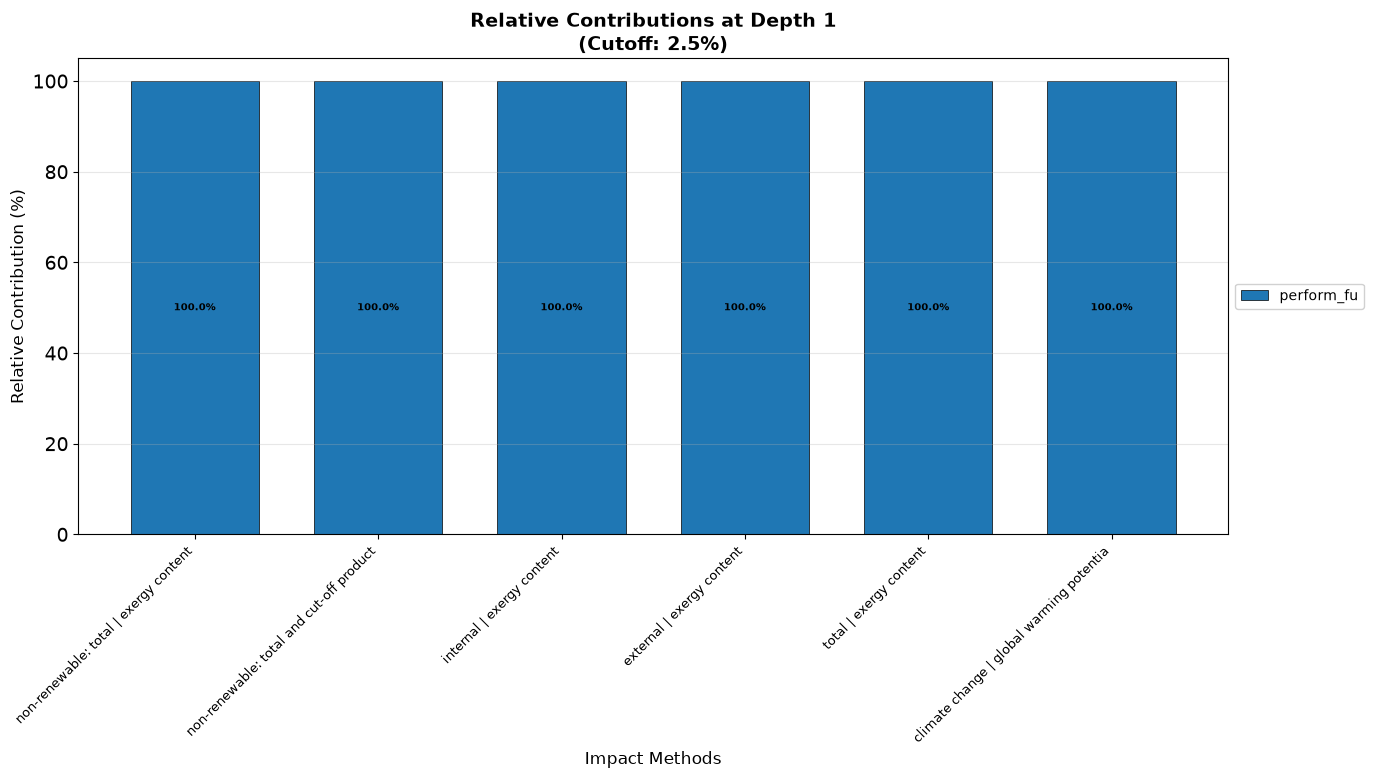


Plot saved to bw25_relative_comparison_depth_1.svg


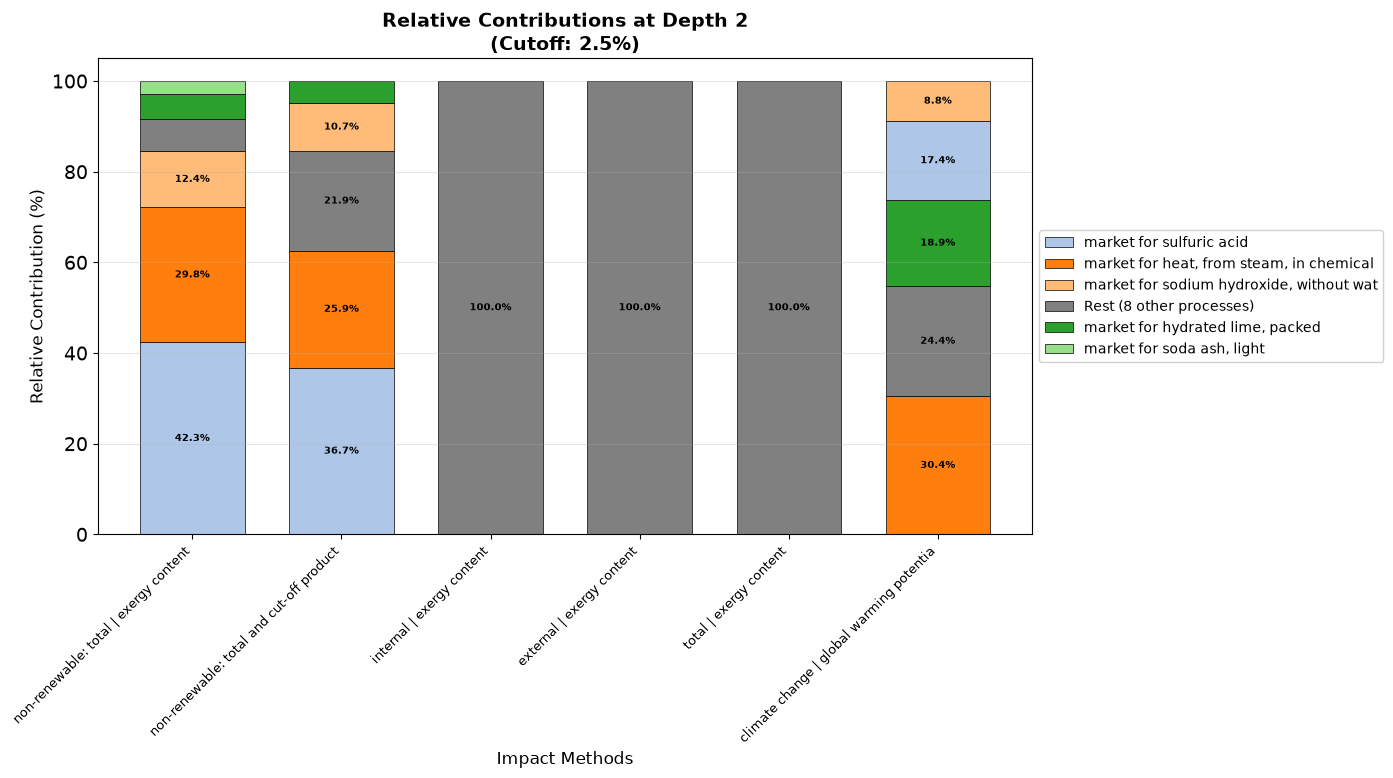


Plot saved to bw25_relative_comparison_depth_2.svg


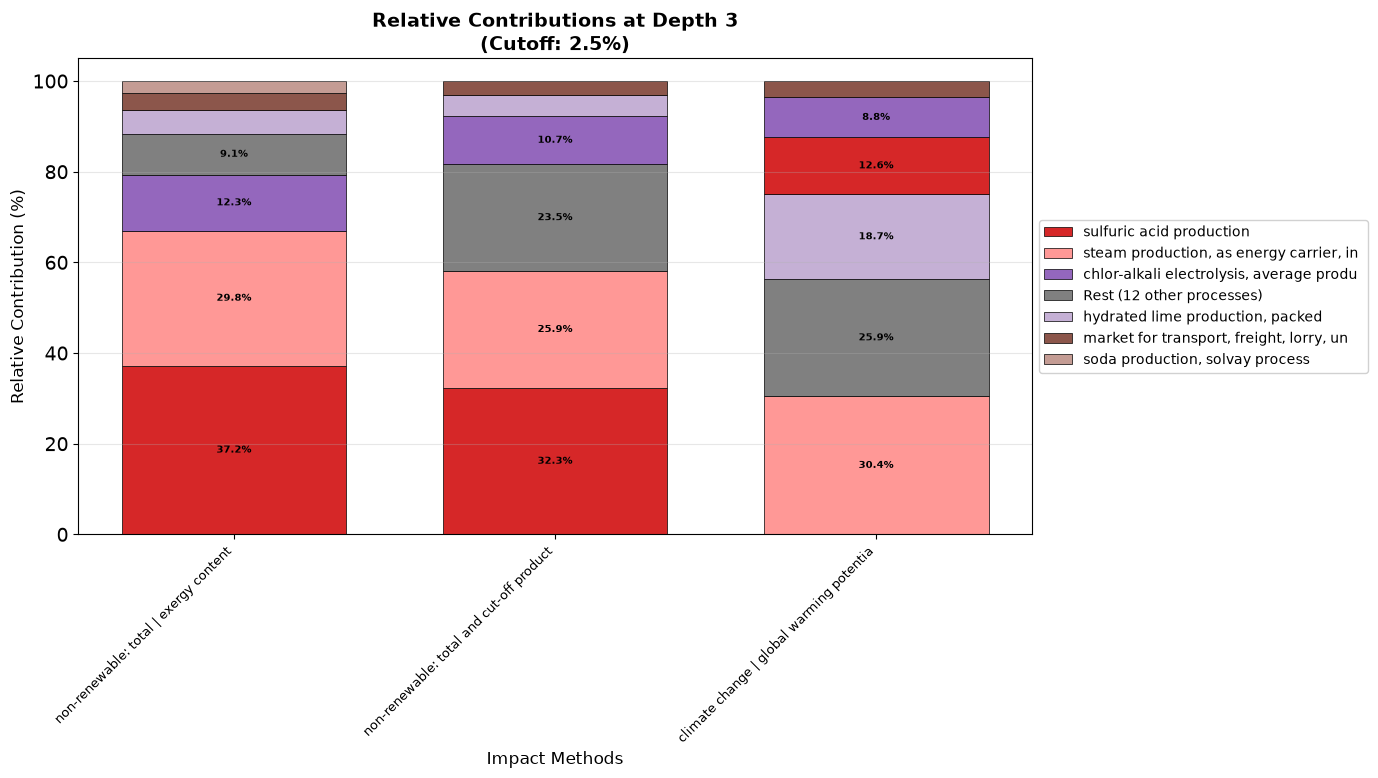


Plot saved to bw25_relative_comparison_depth_3.svg


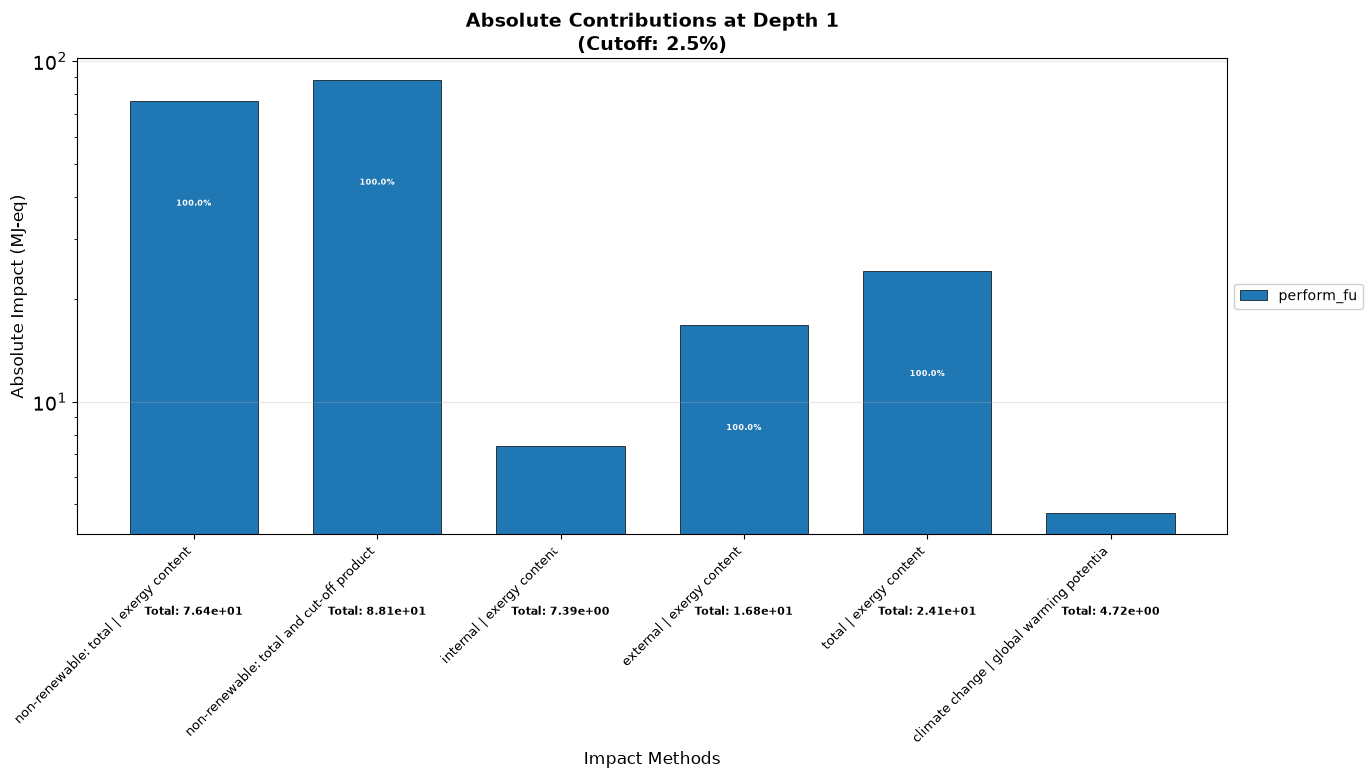


Plot saved to bw25_absolute_comparison_depth_1.svg


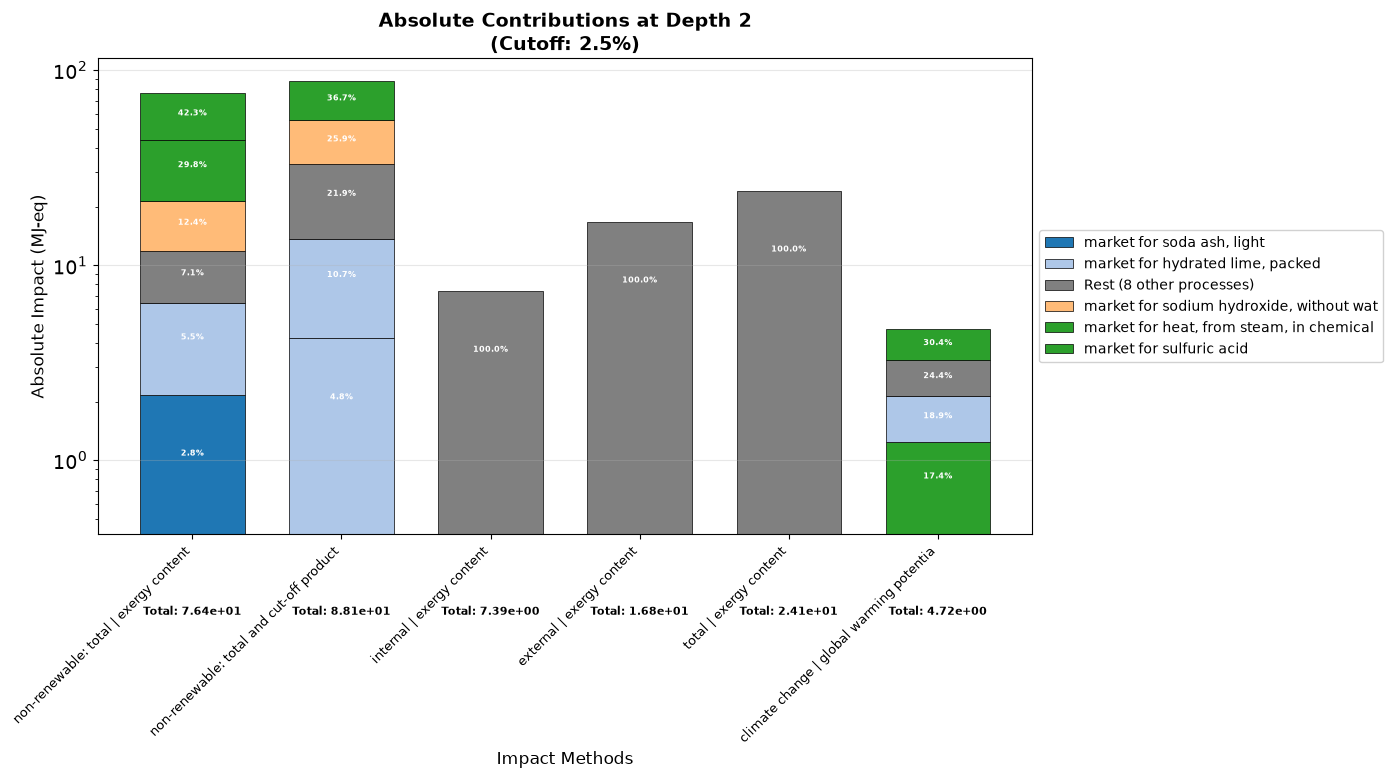


Plot saved to bw25_absolute_comparison_depth_2.svg


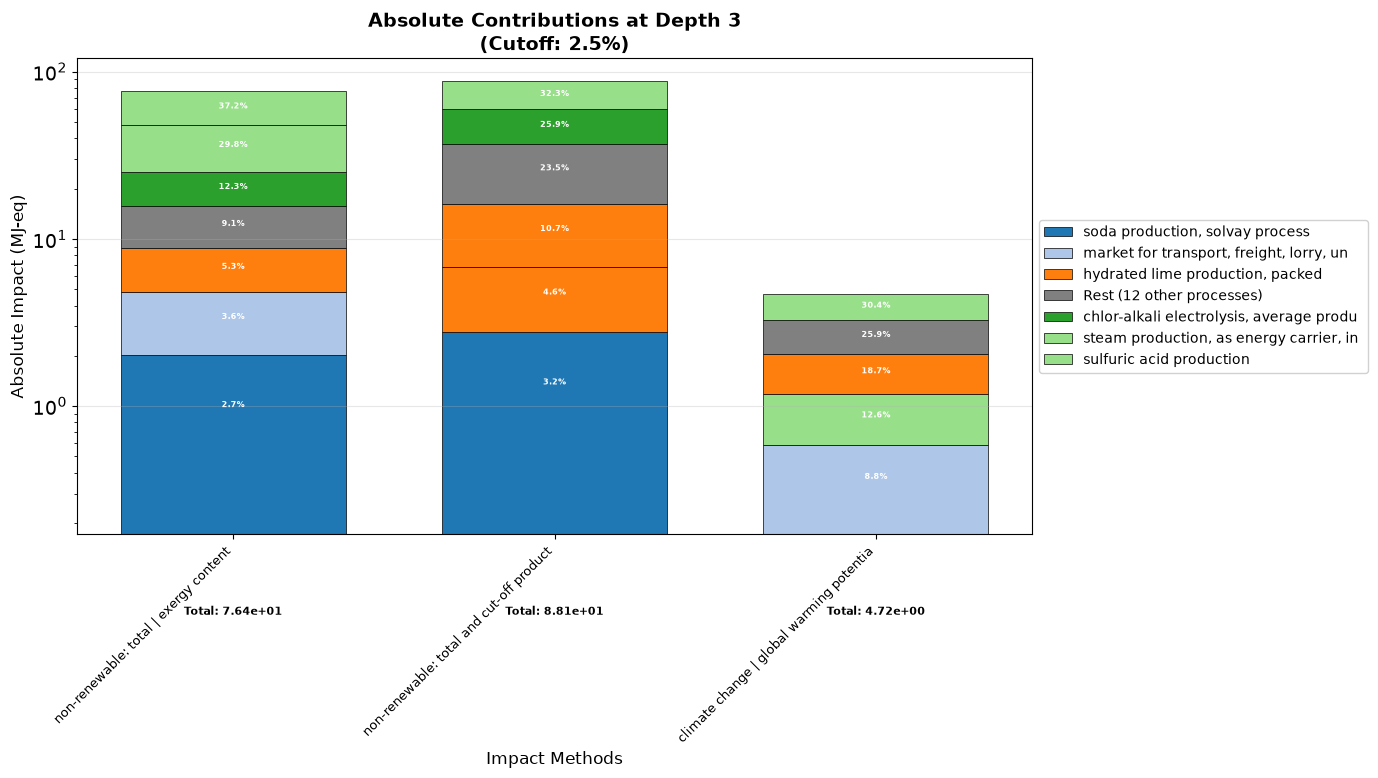


Plot saved to bw25_absolute_comparison_depth_3.svg


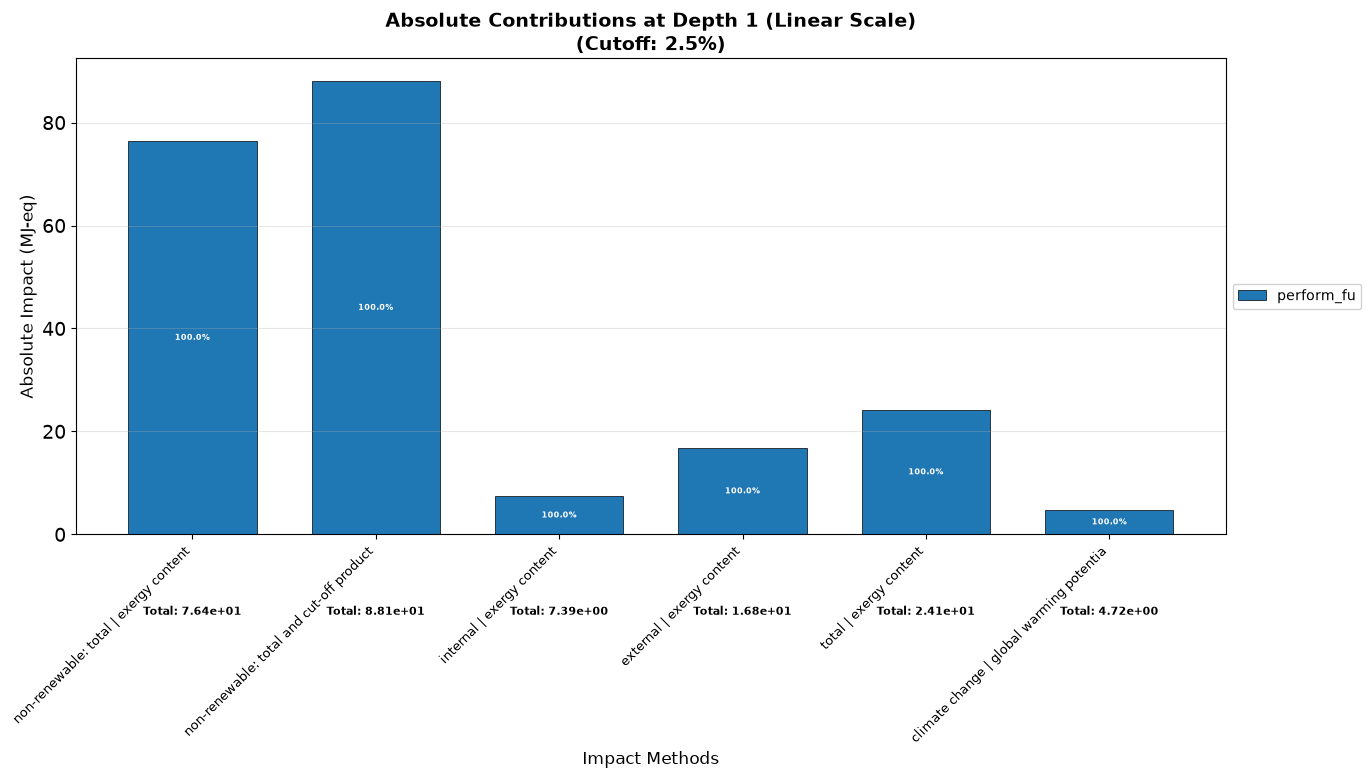


Plot saved to bw25_absolute_linear_depth_1.svg


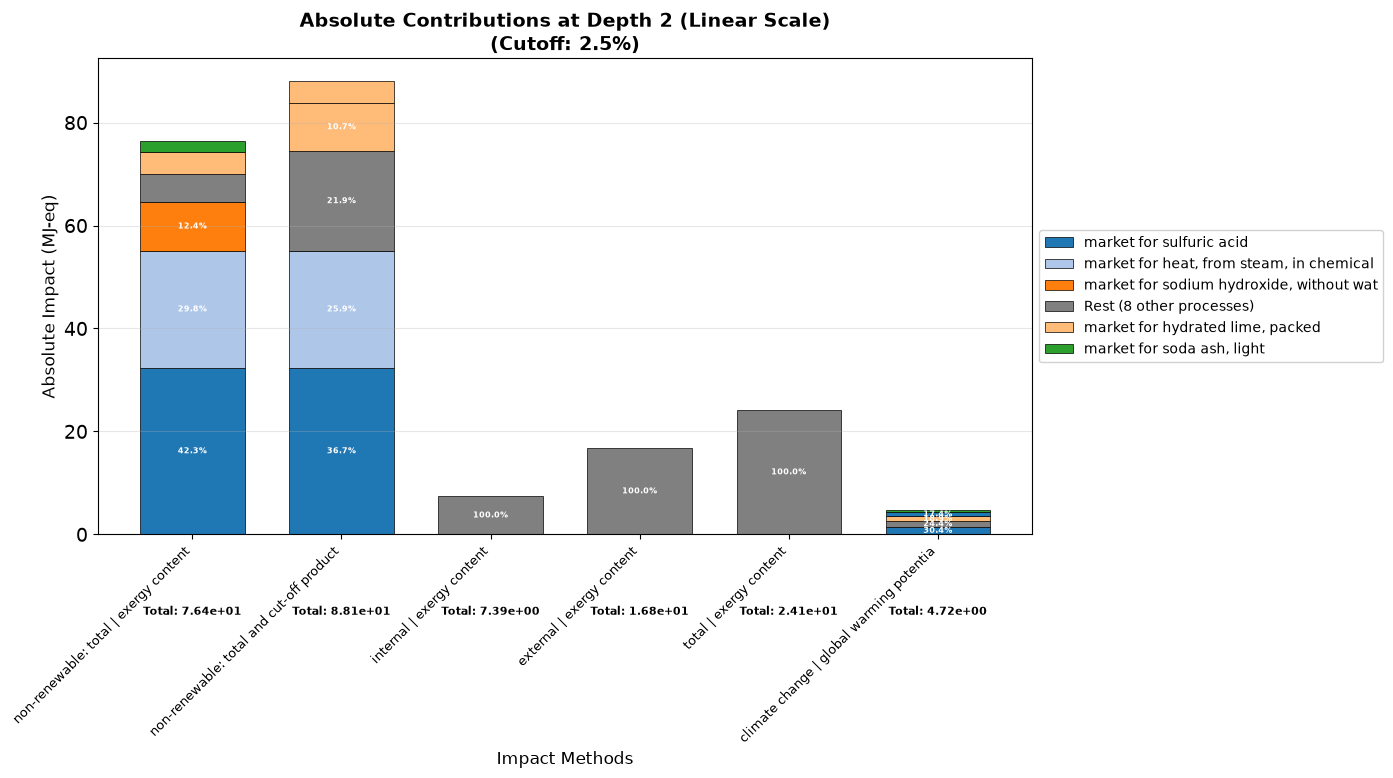


Plot saved to bw25_absolute_linear_depth_2.svg


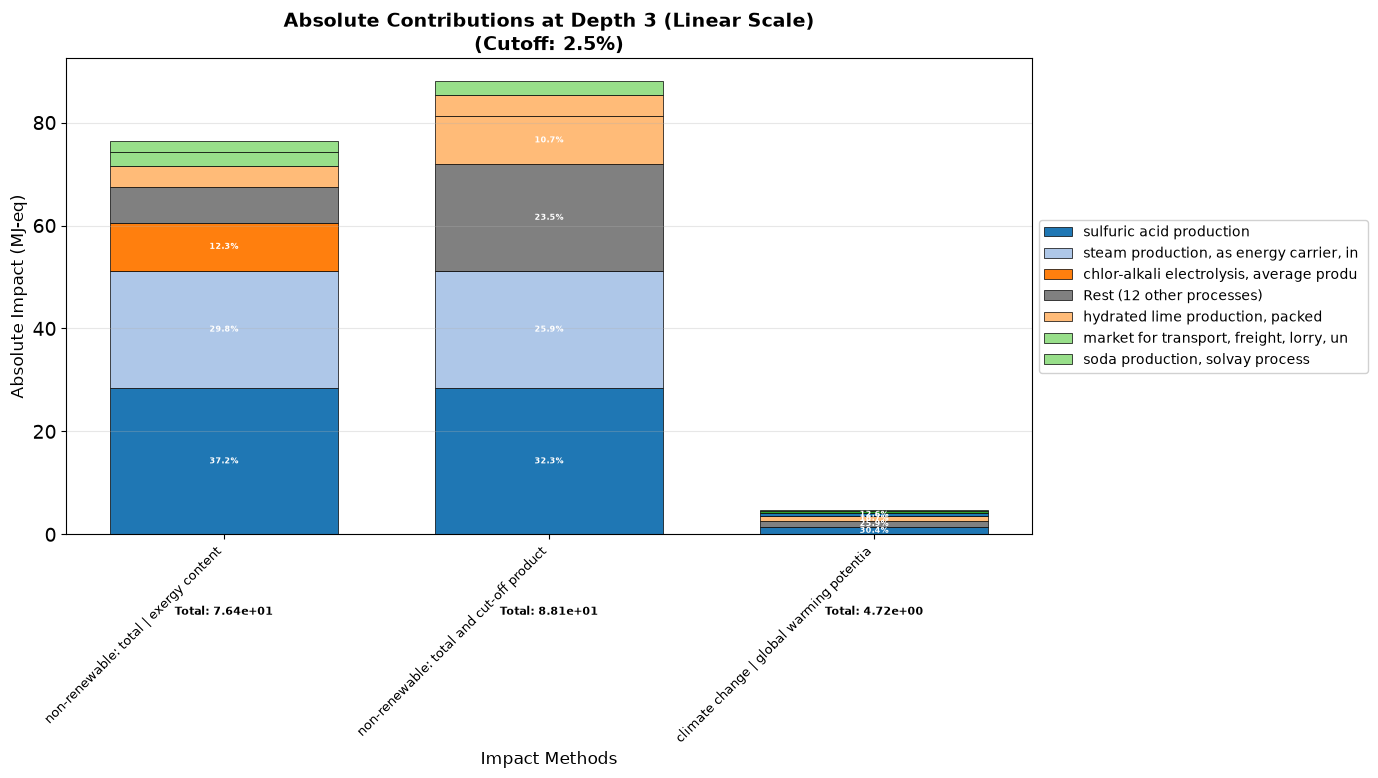


Plot saved to bw25_absolute_linear_depth_3.svg


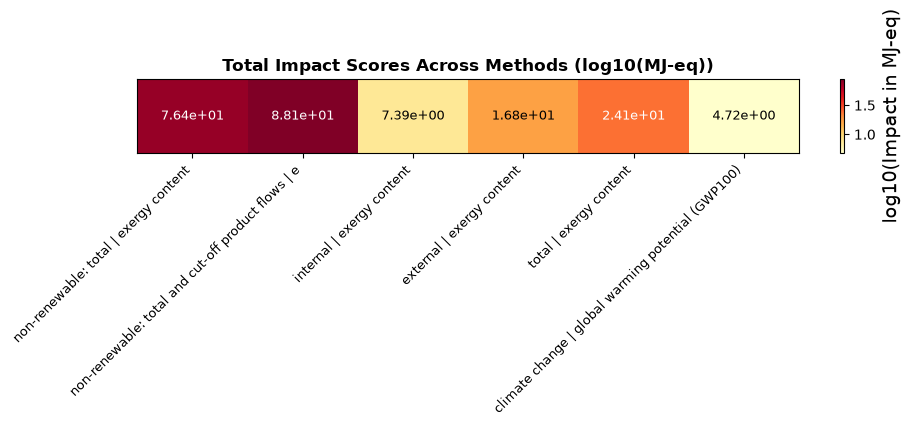


Plot saved to bw25_total_scores_heatmap.svg

####################################################################################################
# process-type transcription | FU: 1.0 perform_fu
####################################################################################################

########################################################################################################################
# Analyzing method: non-renewable: total | exergy content
# Method key: ('Custom Cumulative Exergy Demand (CCExD)', 'non-renewable: total', 'exergy content')
########################################################################################################################

Functional Unit: perform_fu (BE)
Total non-renewable: total | exergy content score: 7.640535e+01 MJ-eq

Depth 1 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: perform_fu (BE)
Total internal | exergy content score: 7.394593e+00 MJ-eq

Depth 1 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
perform_fu                                                        perform_fu                     BE          7.3946e+00   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 6 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
---------------------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: perform_fu (BE)
Total external | exergy content score: 1.675400e+01 MJ-eq

Depth 1 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
perform_fu                                                        perform_fu                     BE          1.6754e+01   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
---------------------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: perform_fu (BE)
Total total | exergy content score: 2.414859e+01 MJ-eq

Depth 1 — 1 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
perform_fu                                                        perform_fu                     BE          2.4149e+01   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 3 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
------------------------------

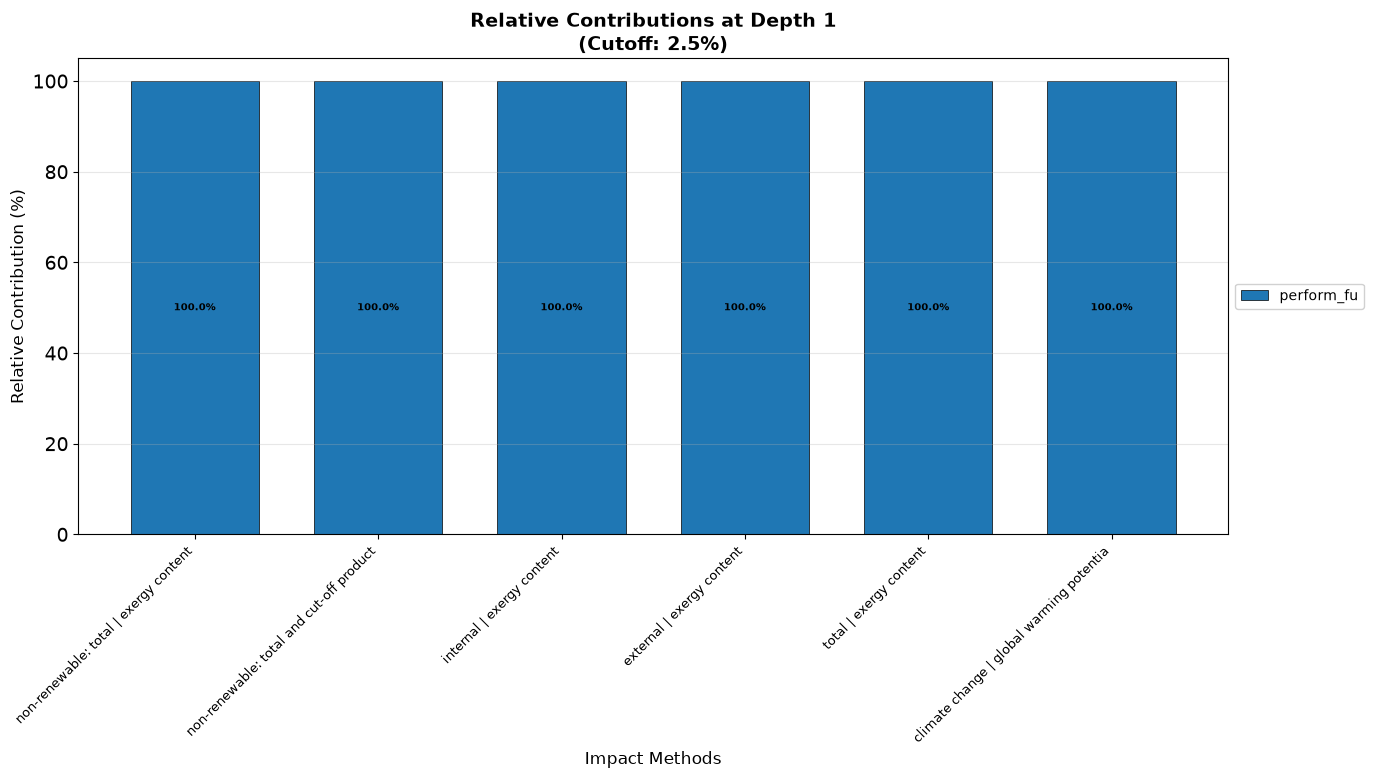


Plot saved to bw25_relative_comparison_depth_1.svg


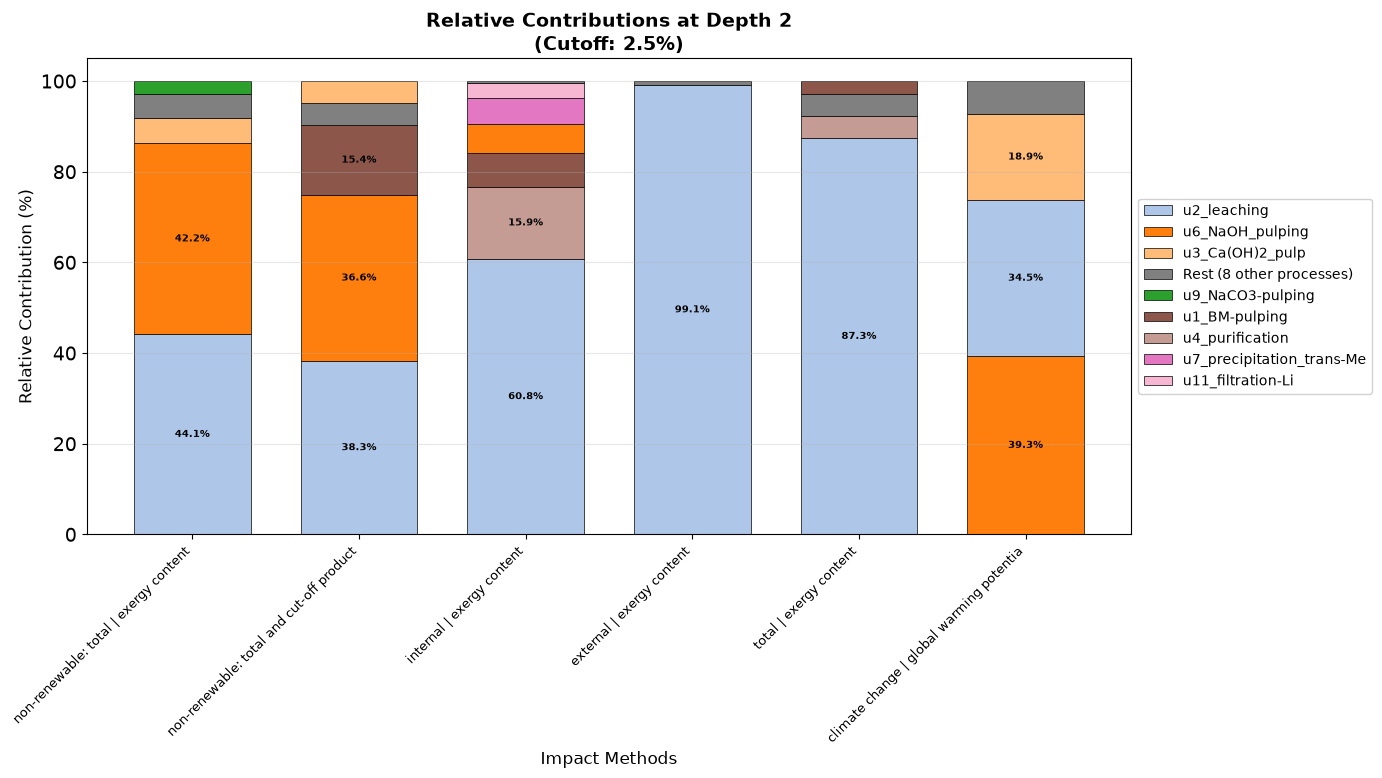


Plot saved to bw25_relative_comparison_depth_2.svg


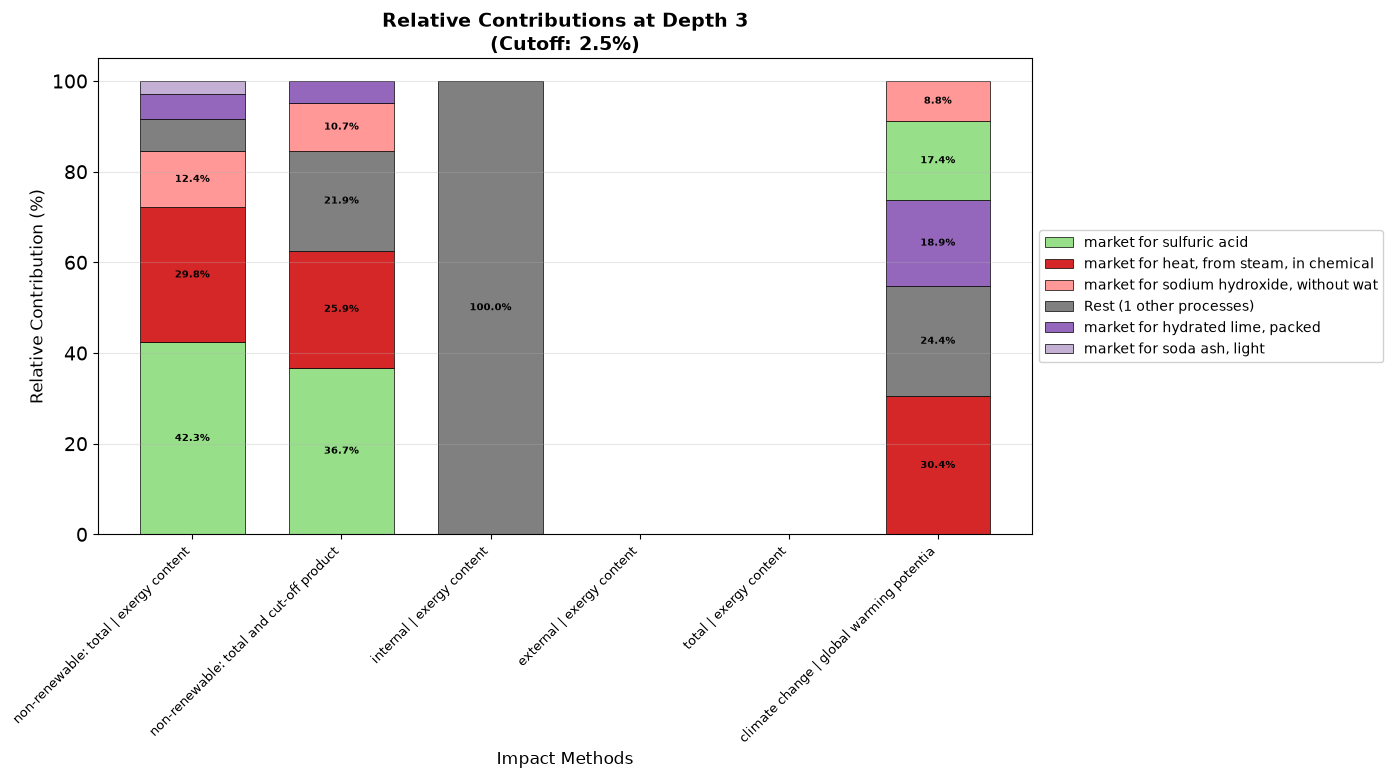


Plot saved to bw25_relative_comparison_depth_3.svg


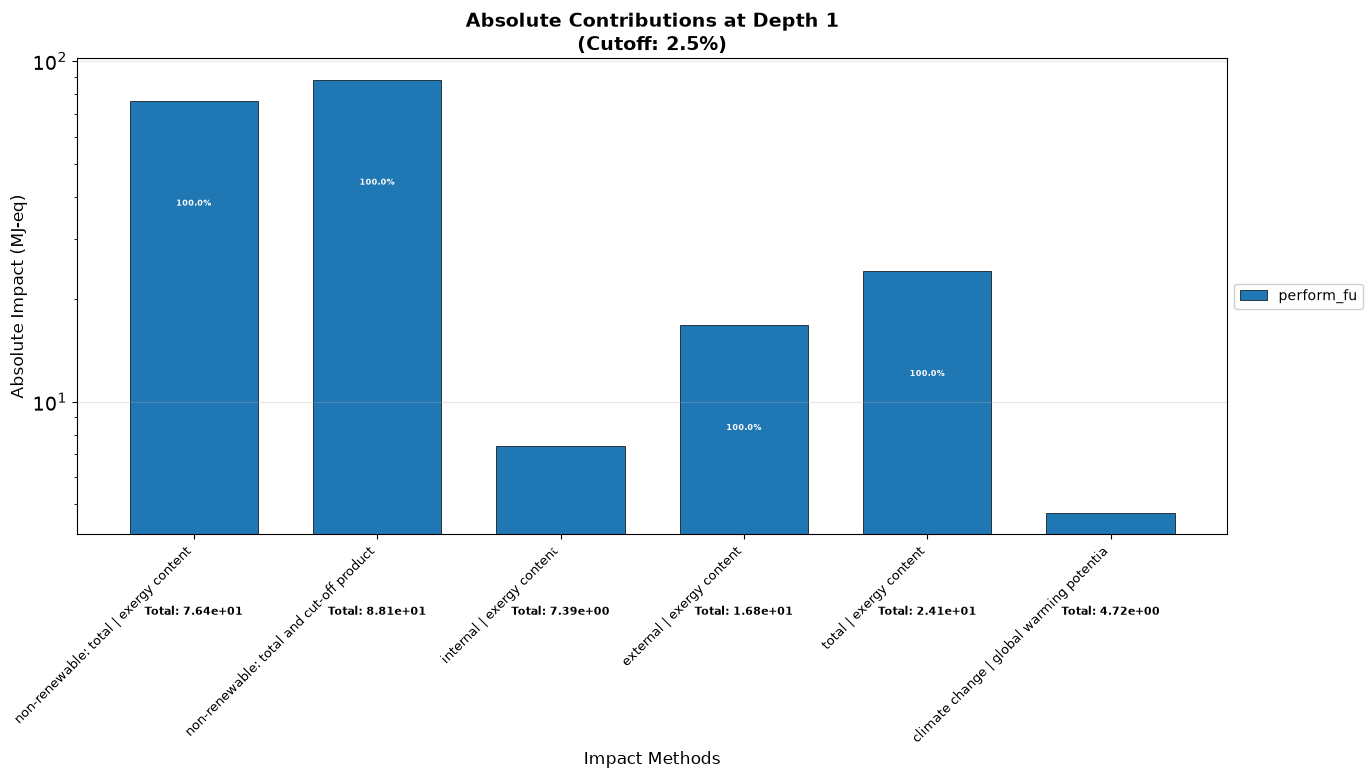


Plot saved to bw25_absolute_comparison_depth_1.svg


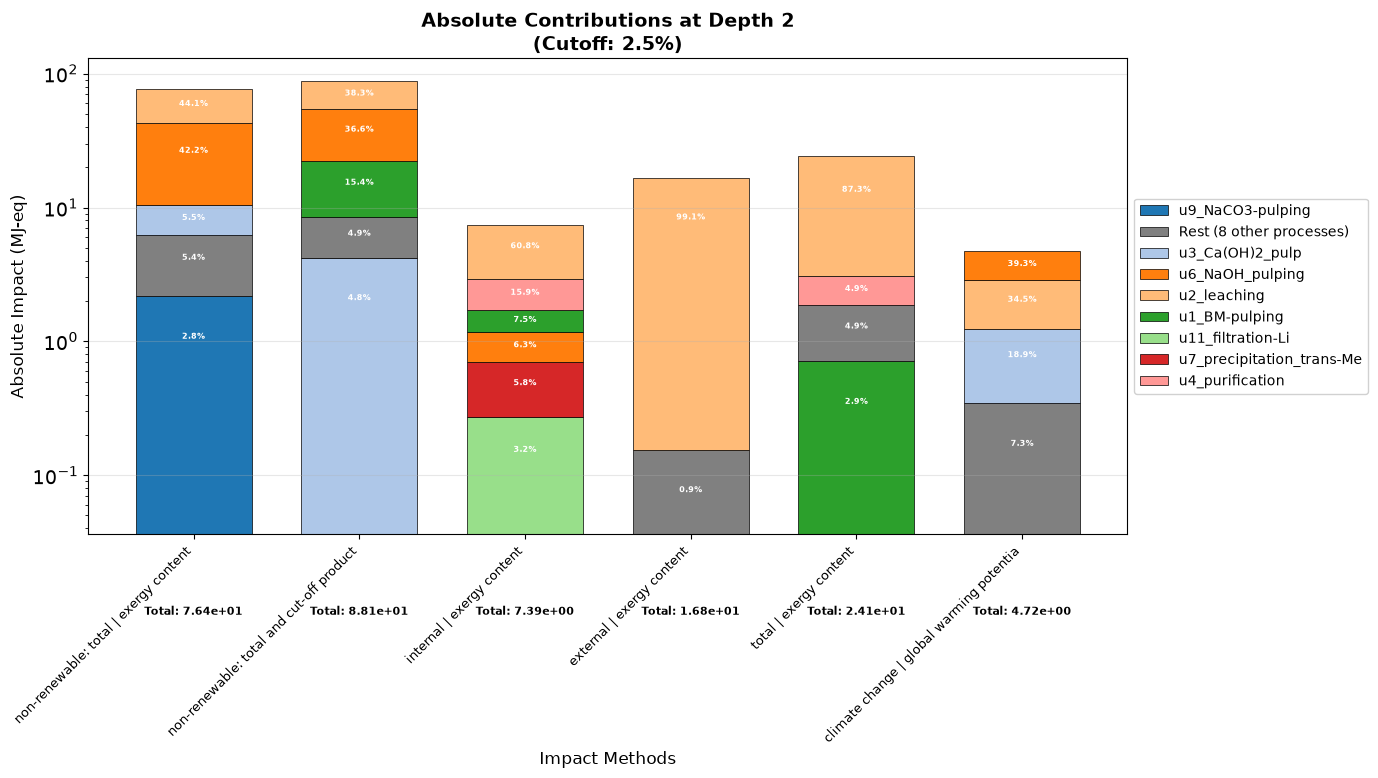


Plot saved to bw25_absolute_comparison_depth_2.svg


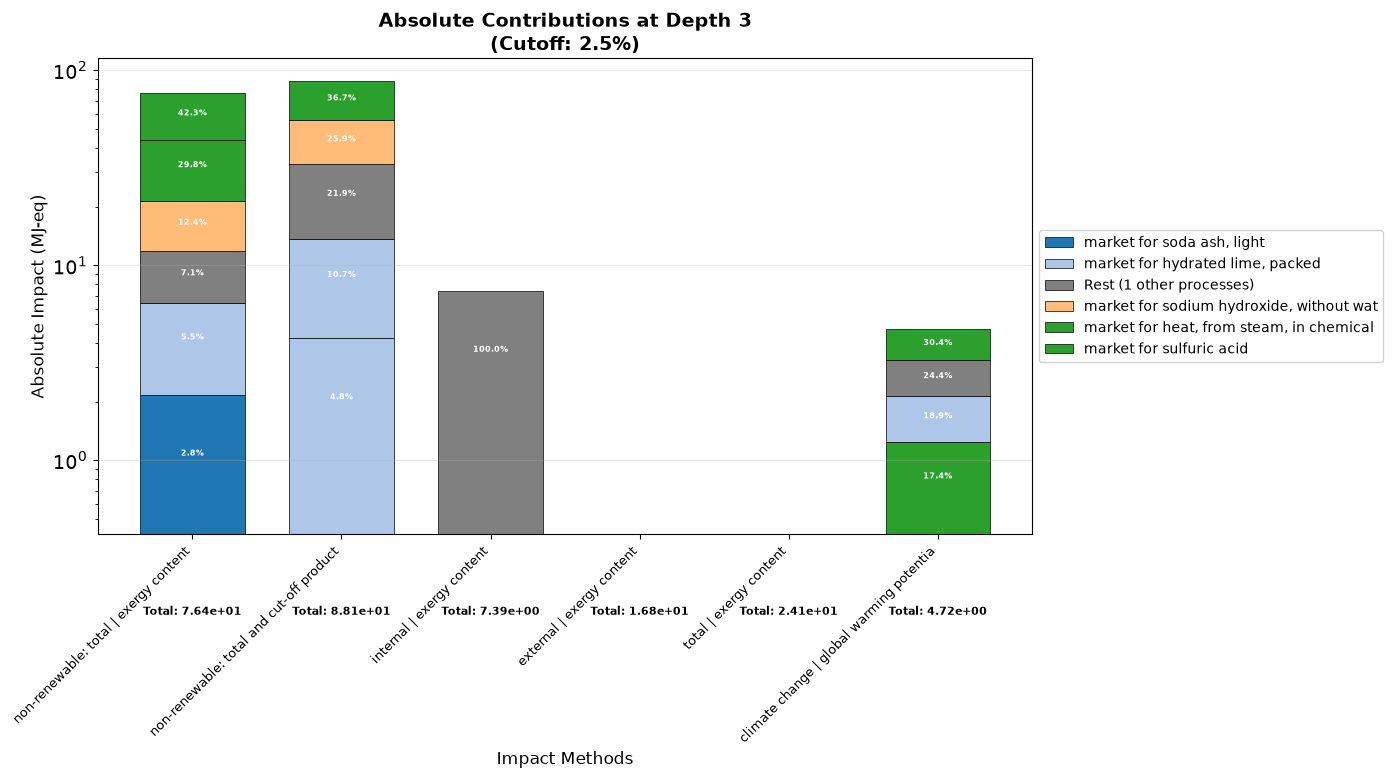


Plot saved to bw25_absolute_comparison_depth_3.svg


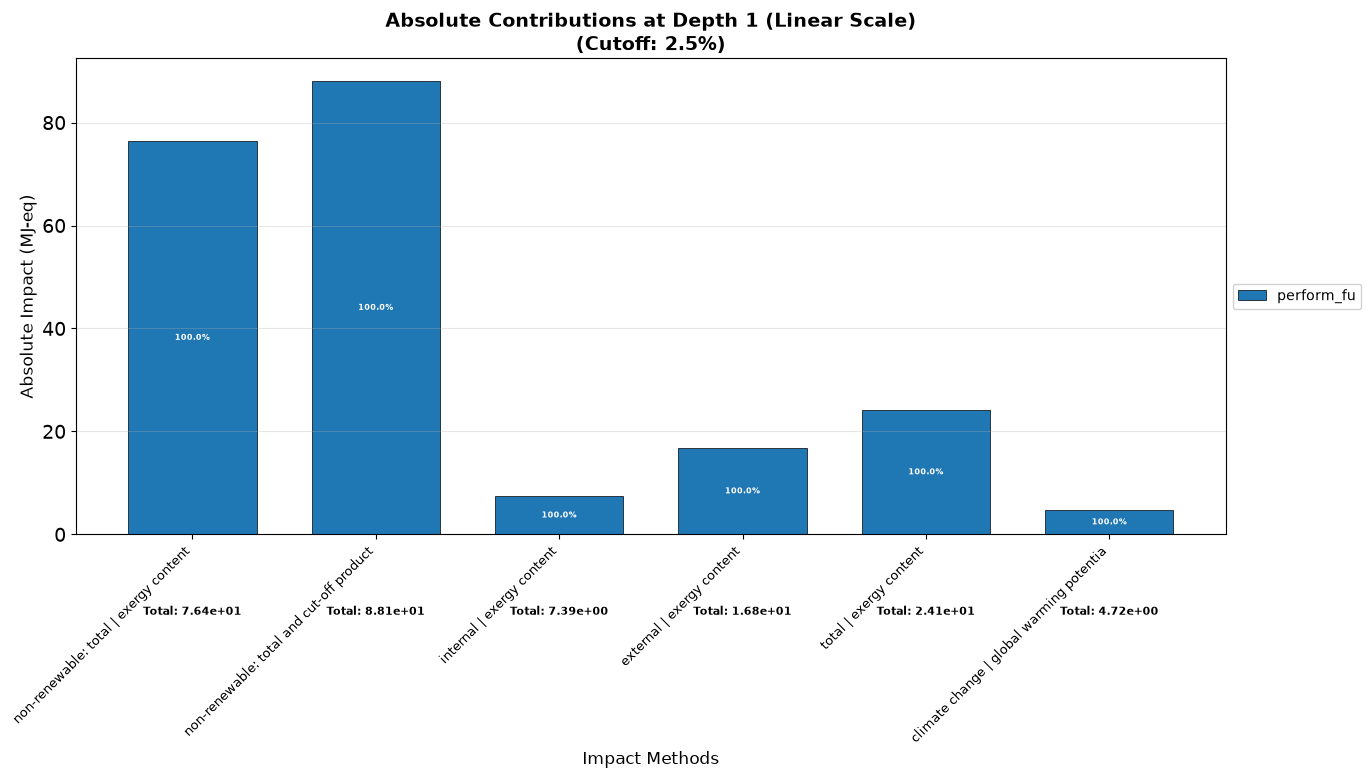


Plot saved to bw25_absolute_linear_depth_1.svg


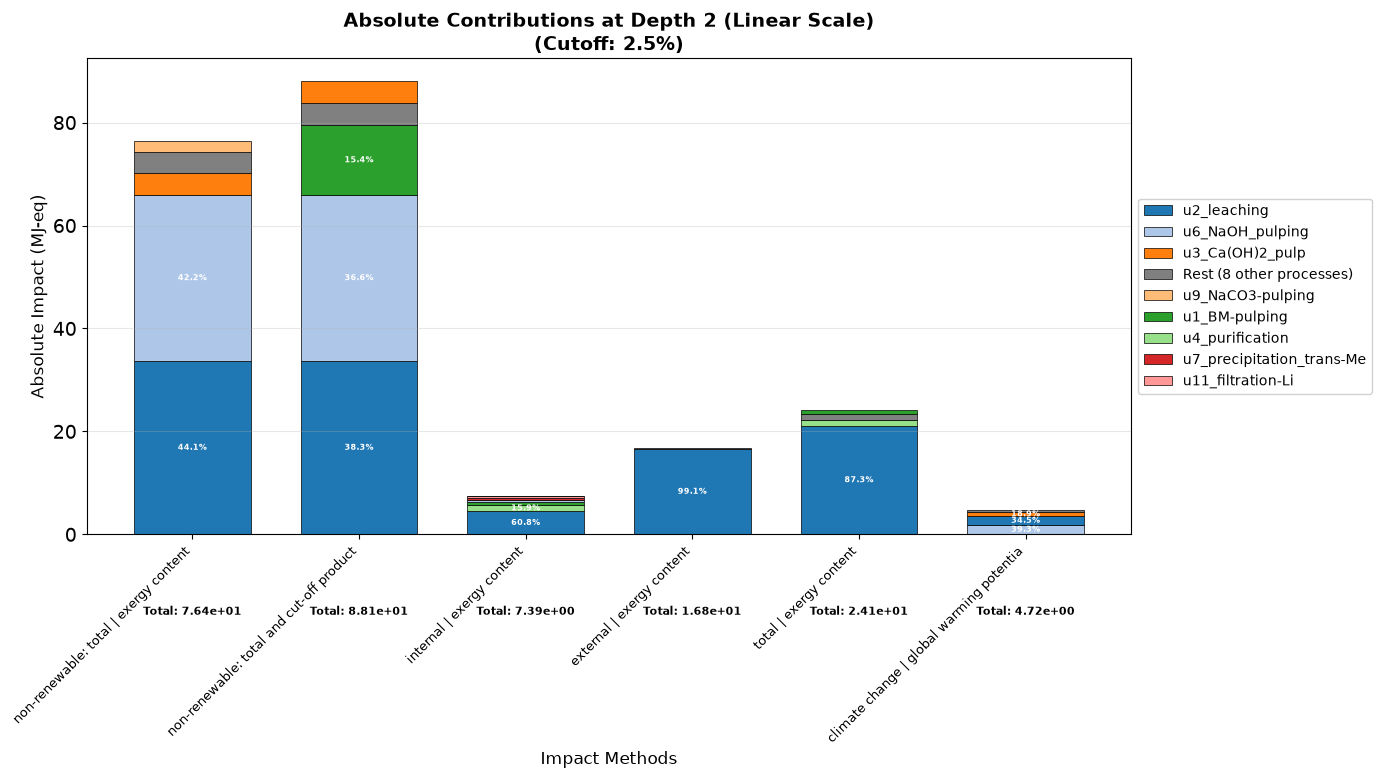


Plot saved to bw25_absolute_linear_depth_2.svg


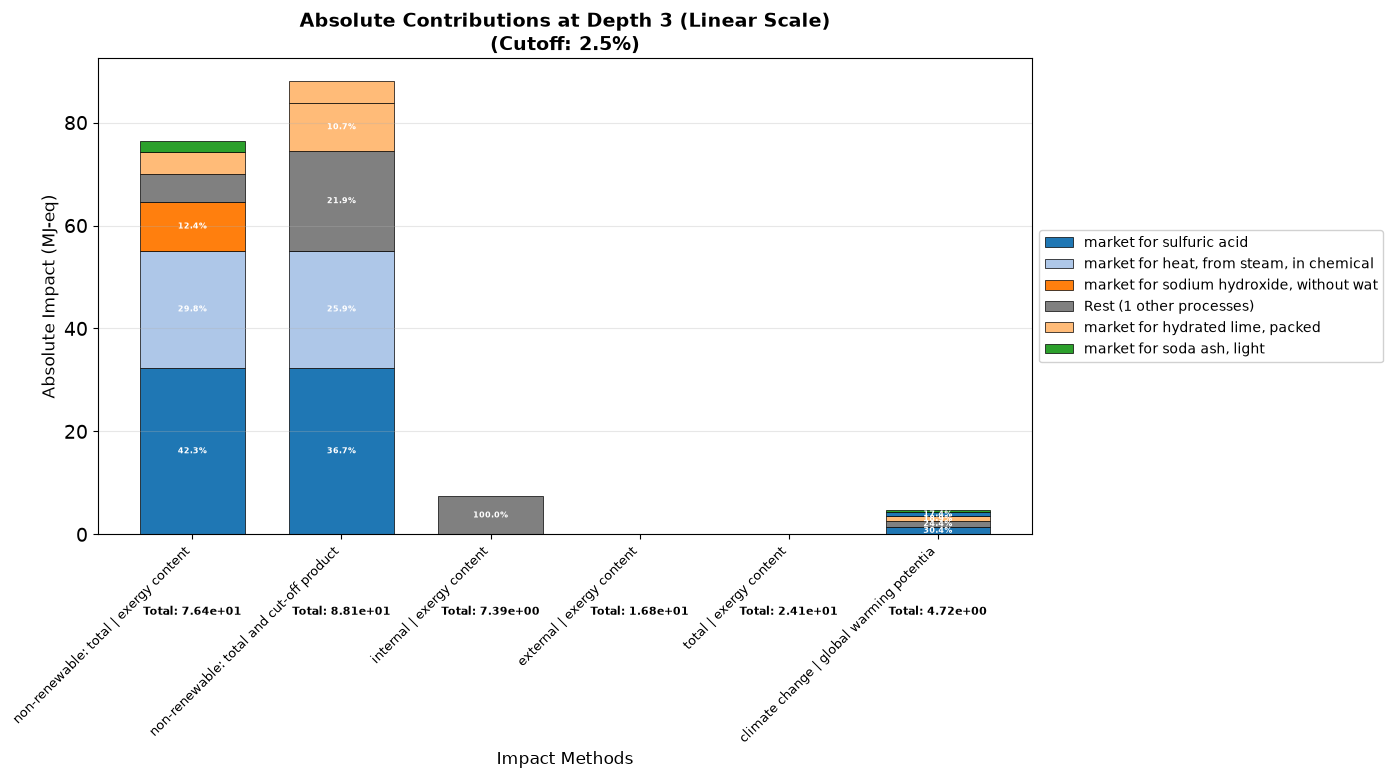


Plot saved to bw25_absolute_linear_depth_3.svg


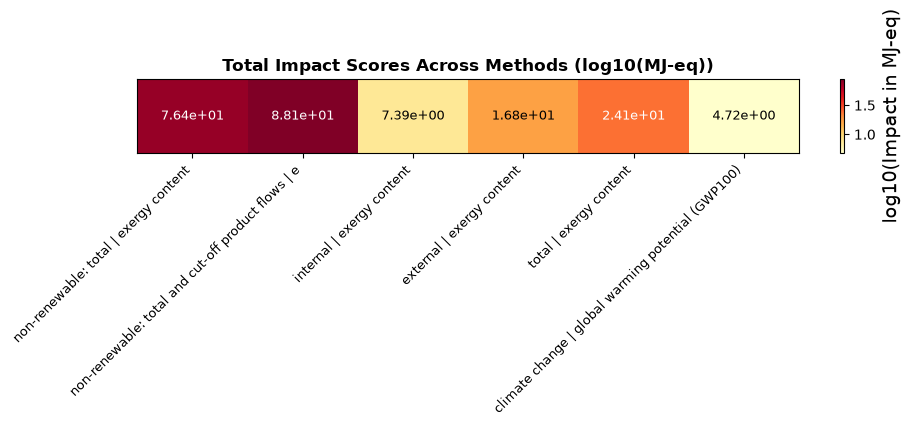


Plot saved to bw25_total_scores_heatmap.svg

####################################################################################################
# product-type transcription | FU: 1.18722 f_8-0_trans-me-hydroxide
####################################################################################################

########################################################################################################################
# Analyzing method: non-renewable: total | exergy content
# Method key: ('Custom Cumulative Exergy Demand (CCExD)', 'non-renewable: total', 'exergy content')
########################################################################################################################

Functional Unit: f_8-0_trans-me-hydroxide (BE)
Total non-renewable: total | exergy content score: 5.581231e+01 MJ-eq

Depth 1 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impa

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: f_8-0_trans-me-hydroxide (BE)
Total internal | exergy content score: 5.382549e+00 MJ-eq

Depth 1 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
f_8-0_trans-me-hydroxide                                          ?                              BE          5.3825e+00   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
-------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: f_8-0_trans-me-hydroxide (BE)
Total external | exergy content score: 1.240034e+01 MJ-eq

Depth 1 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
f_8-0_trans-me-hydroxide                                          ?                              BE          1.2400e+01   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
-------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: f_8-0_trans-me-hydroxide (BE)
Total total | exergy content score: 1.778289e+01 MJ-eq

Depth 1 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
f_8-0_trans-me-hydroxide                                          ?                              BE          1.7783e+01   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------

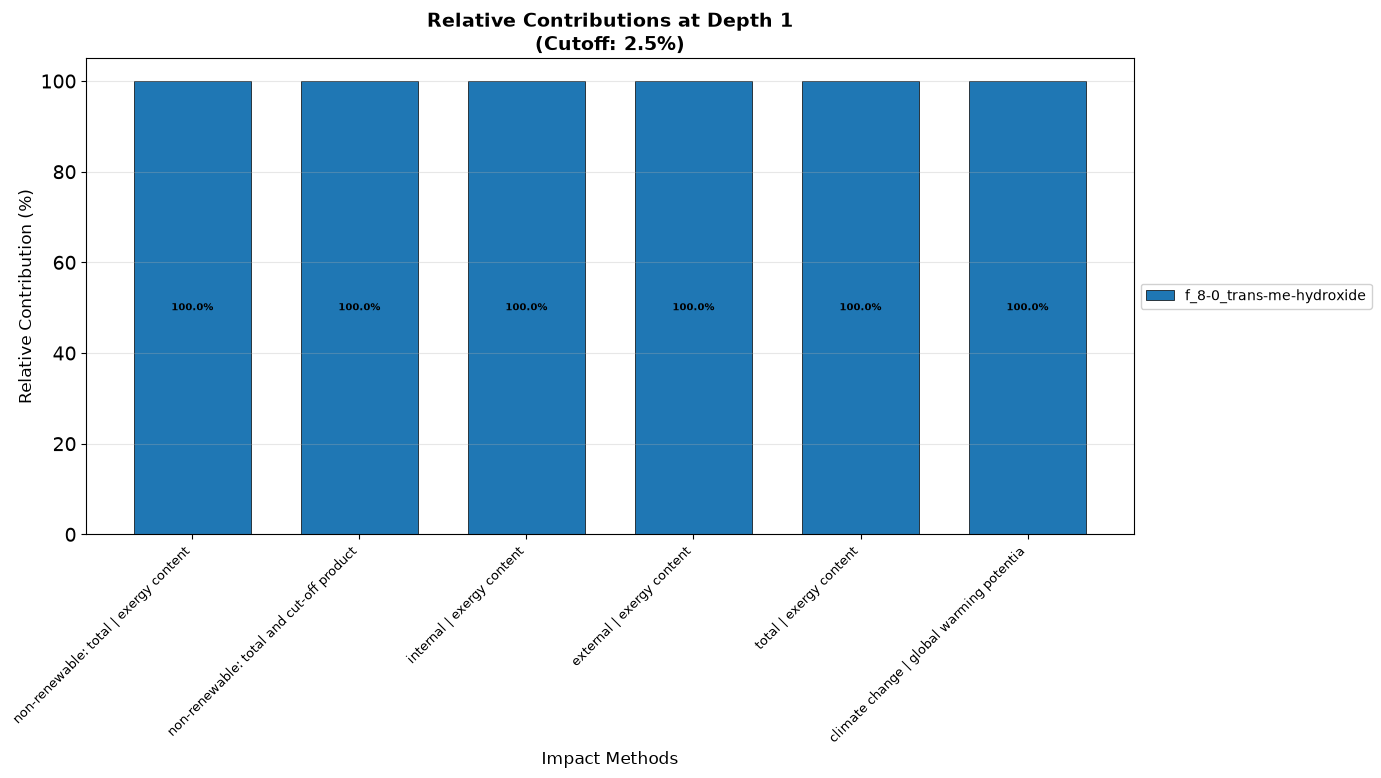


Plot saved to bw25_relative_comparison_depth_1.svg


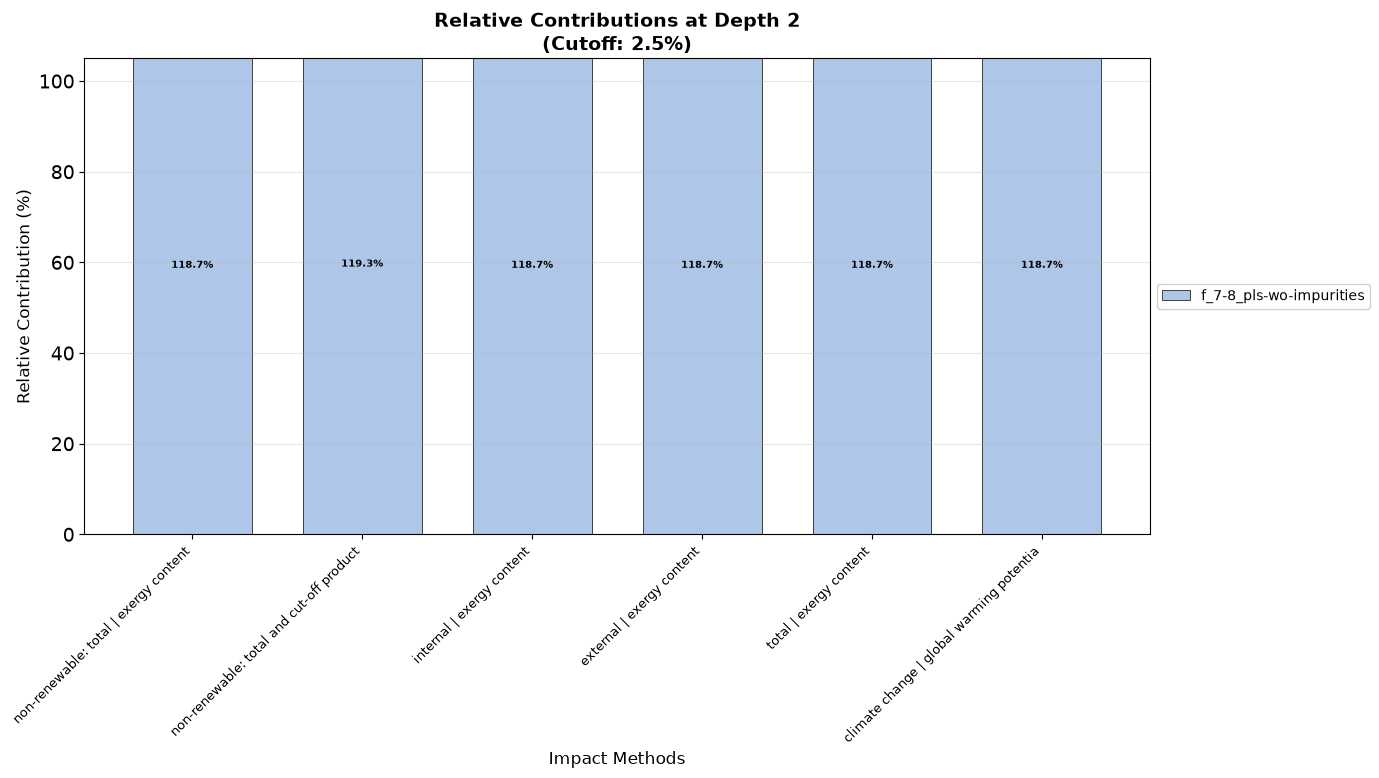


Plot saved to bw25_relative_comparison_depth_2.svg


C:\Users\lfreboeuf\AppData\Local\Temp\ipykernel_20368\2858155292.py:307: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


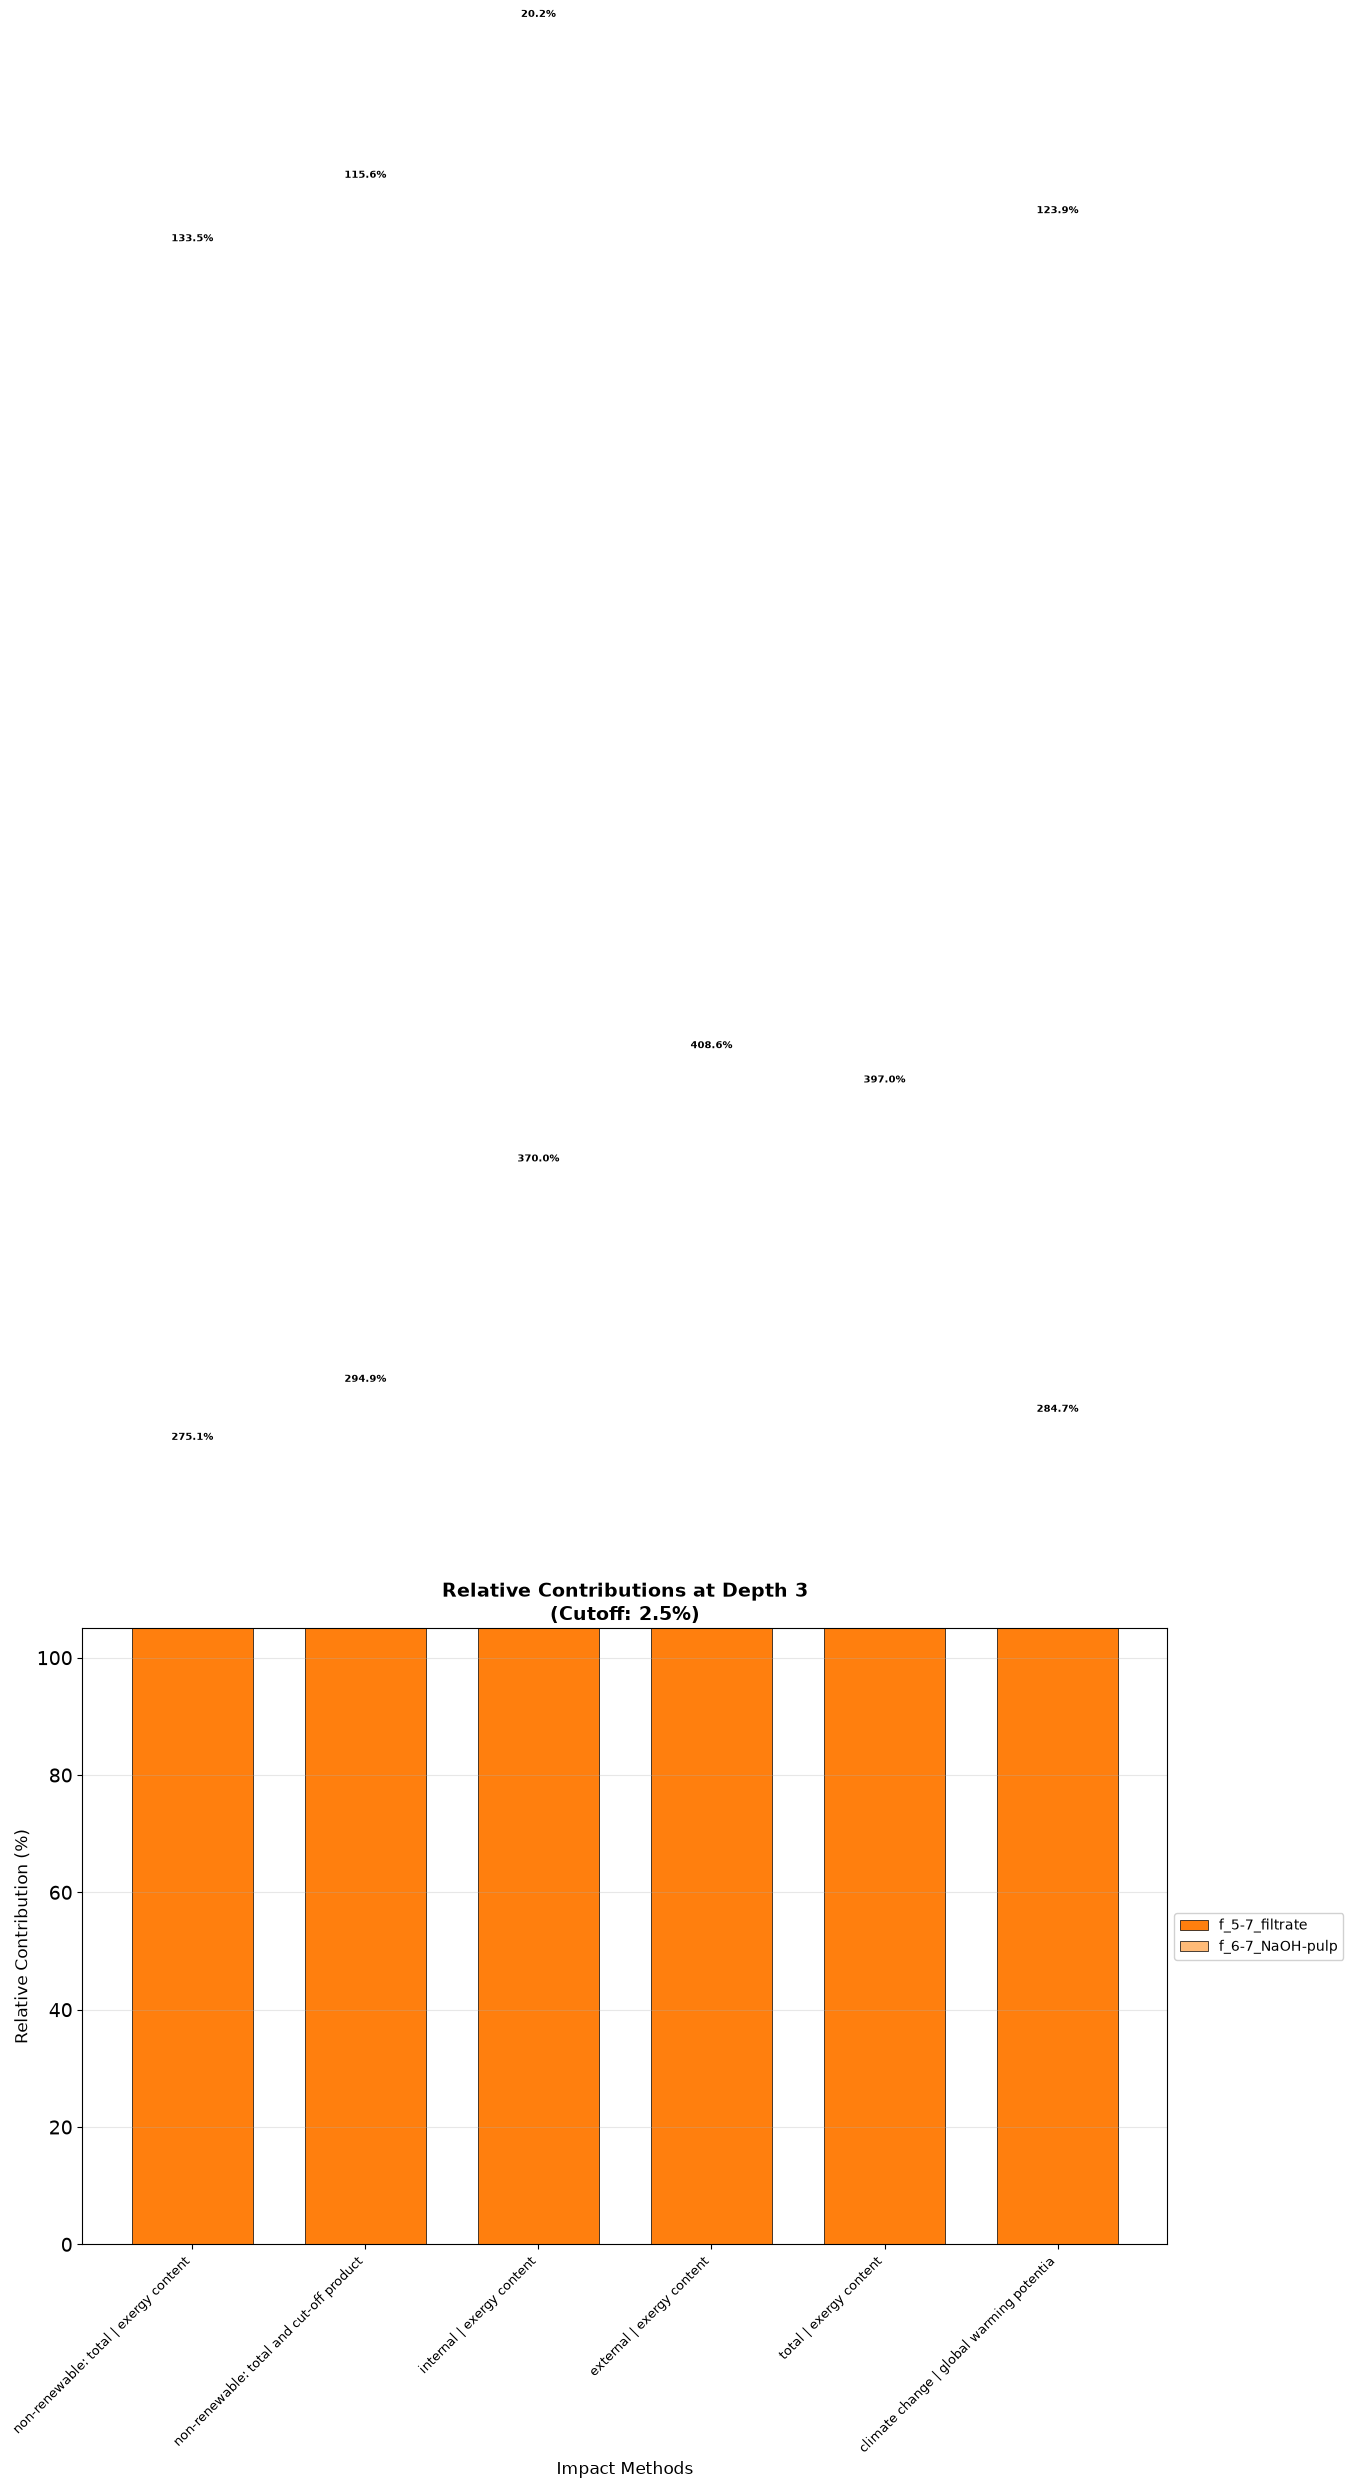


Plot saved to bw25_relative_comparison_depth_3.svg


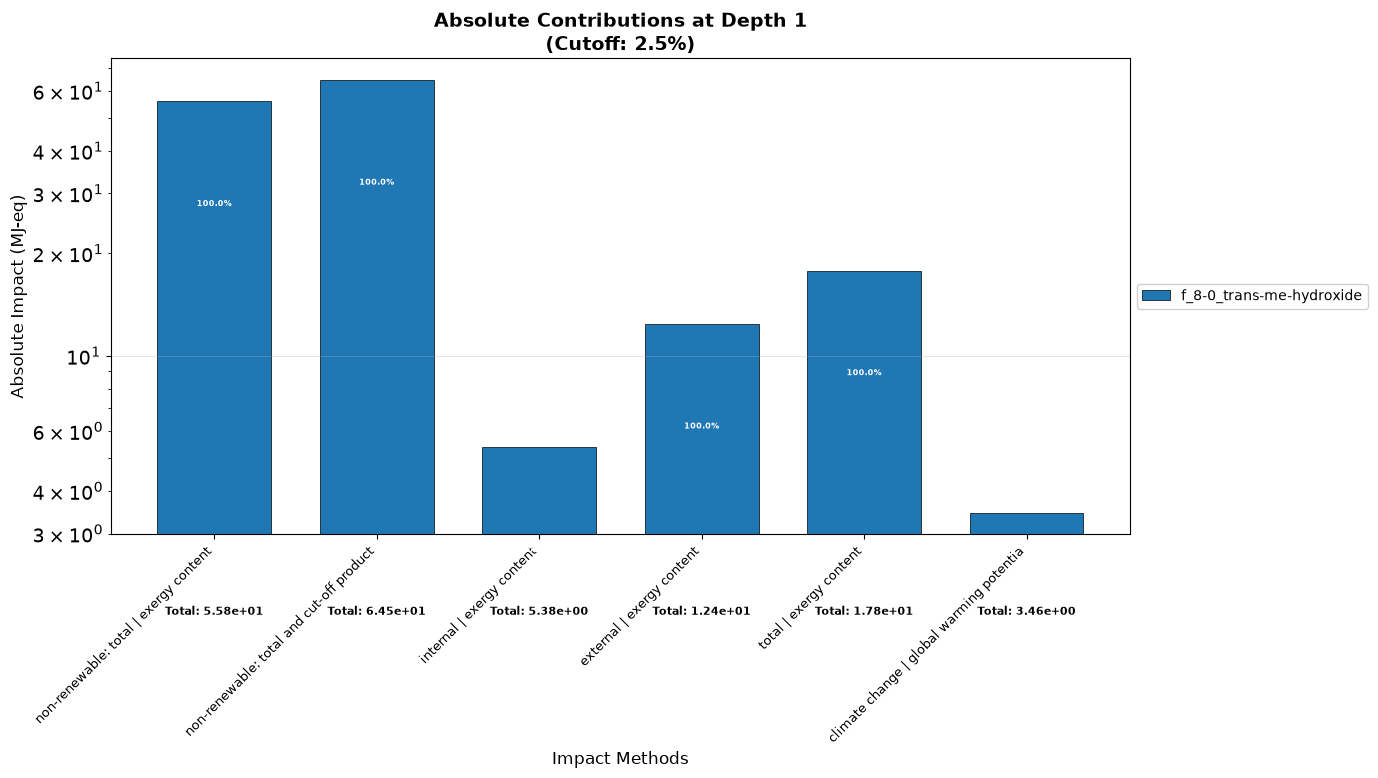


Plot saved to bw25_absolute_comparison_depth_1.svg


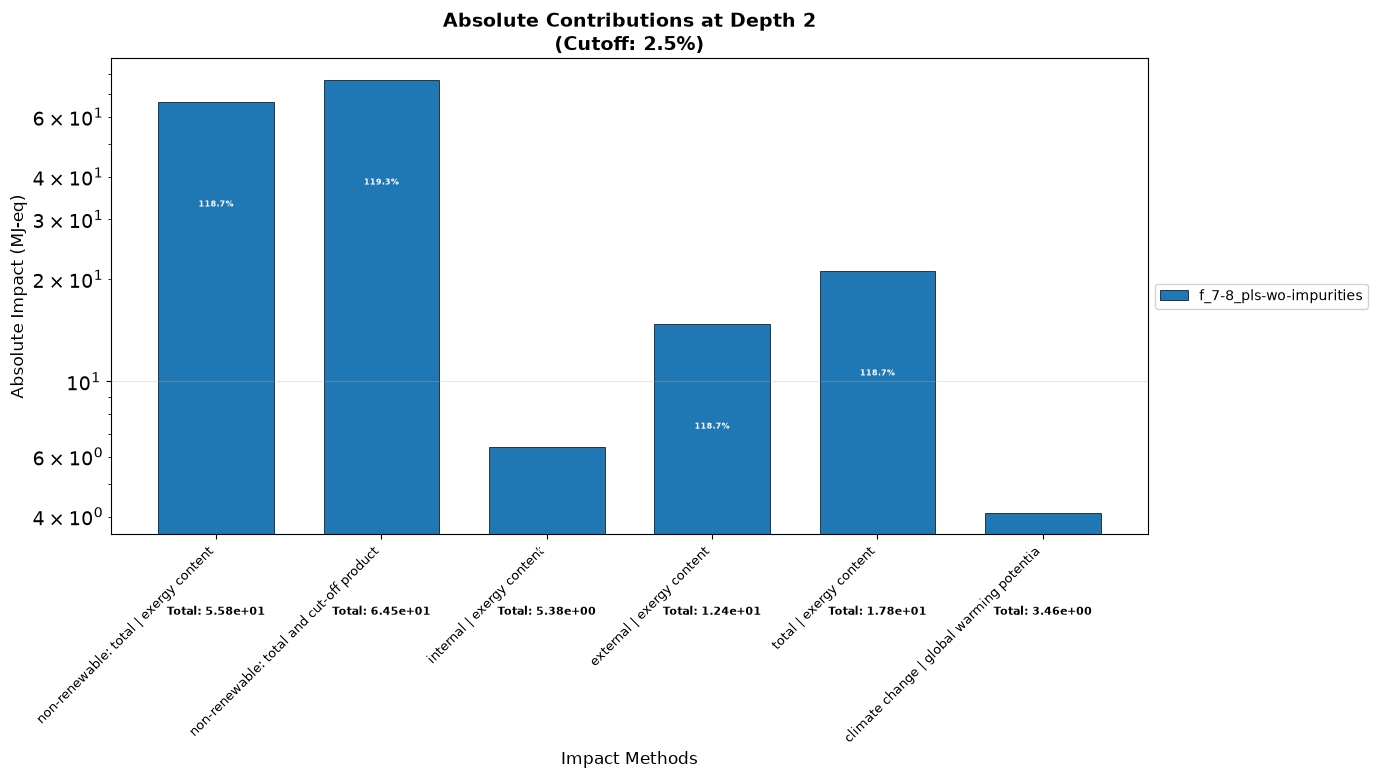


Plot saved to bw25_absolute_comparison_depth_2.svg


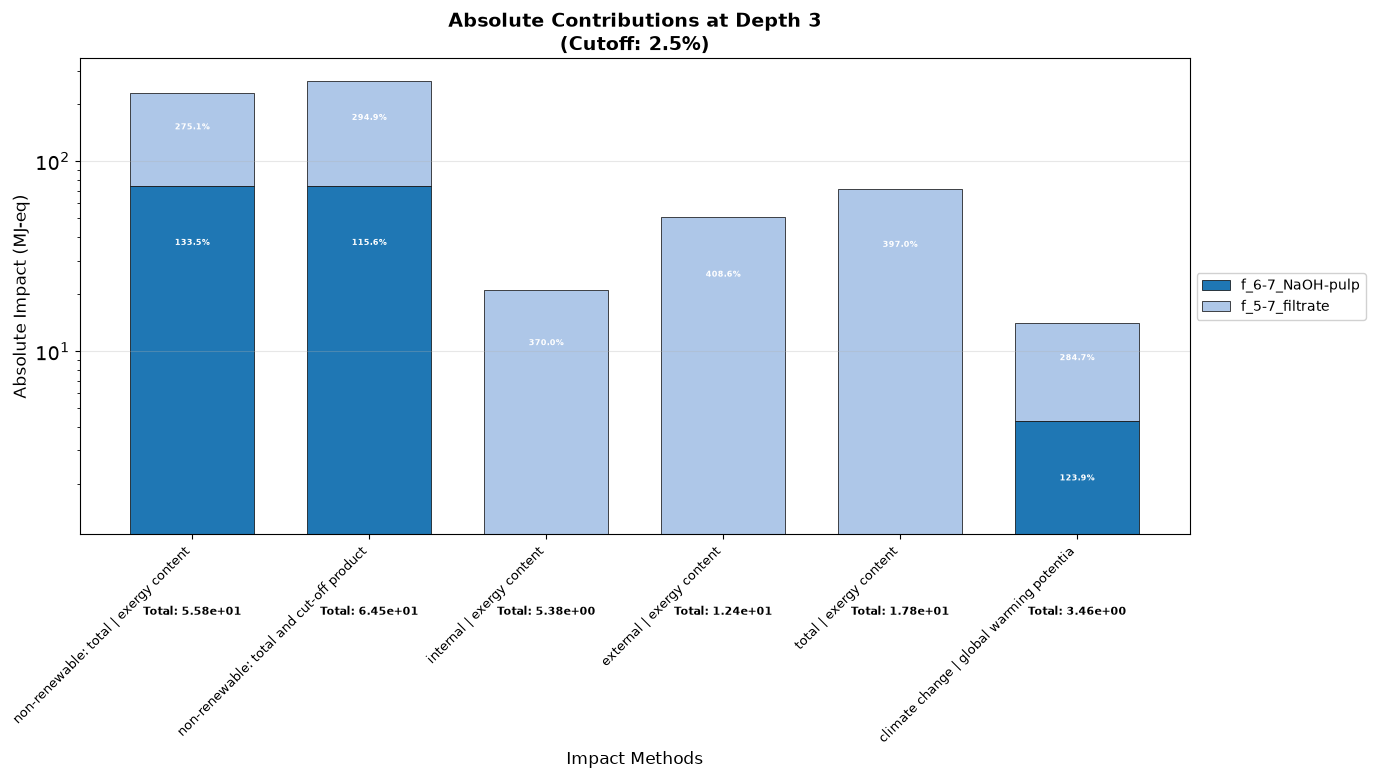


Plot saved to bw25_absolute_comparison_depth_3.svg


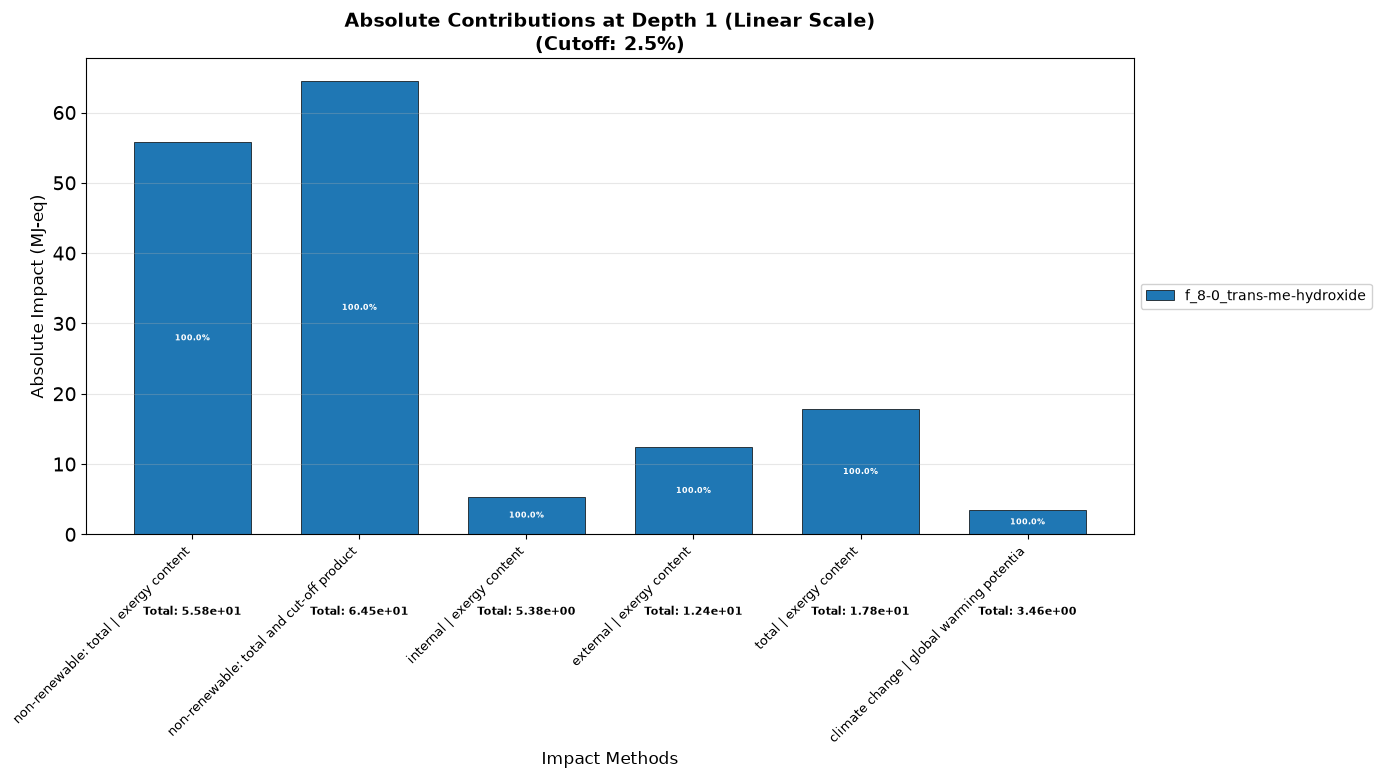


Plot saved to bw25_absolute_linear_depth_1.svg


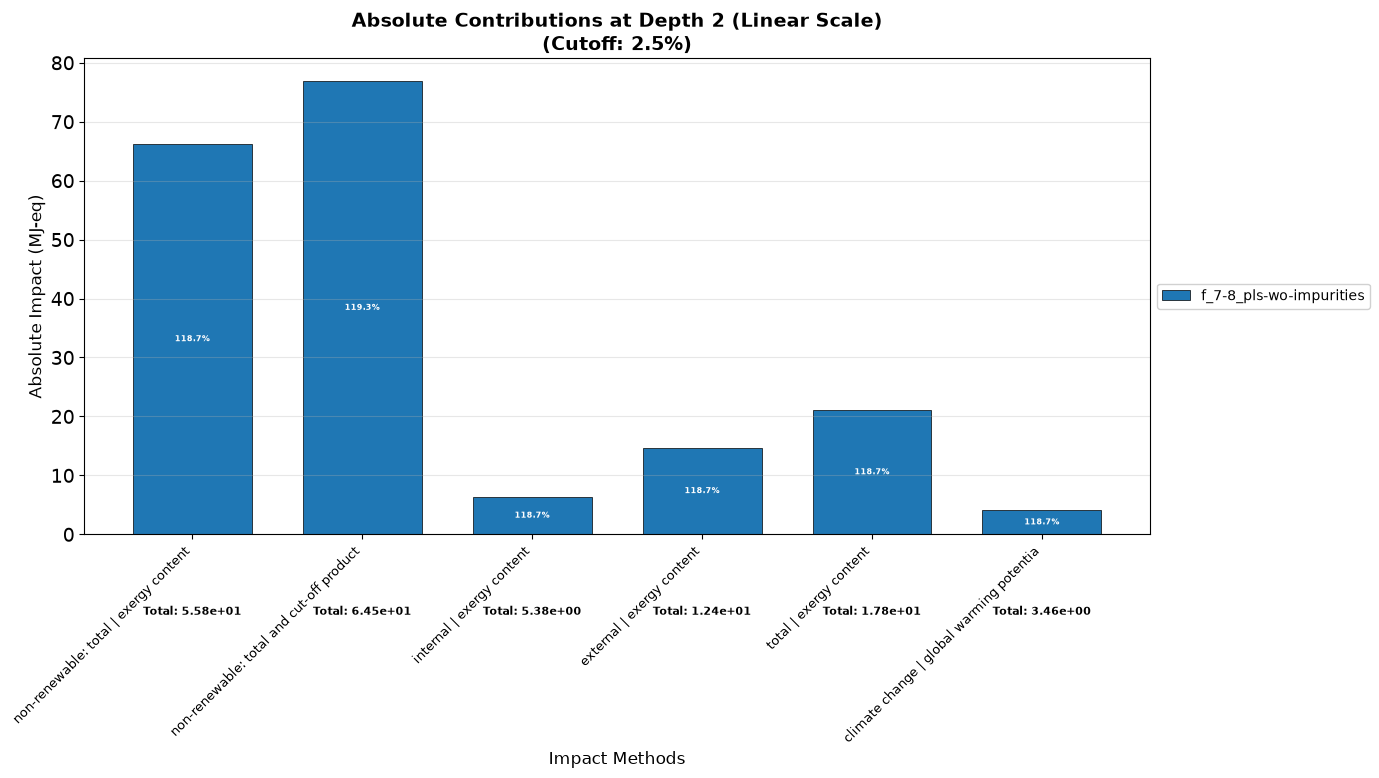


Plot saved to bw25_absolute_linear_depth_2.svg


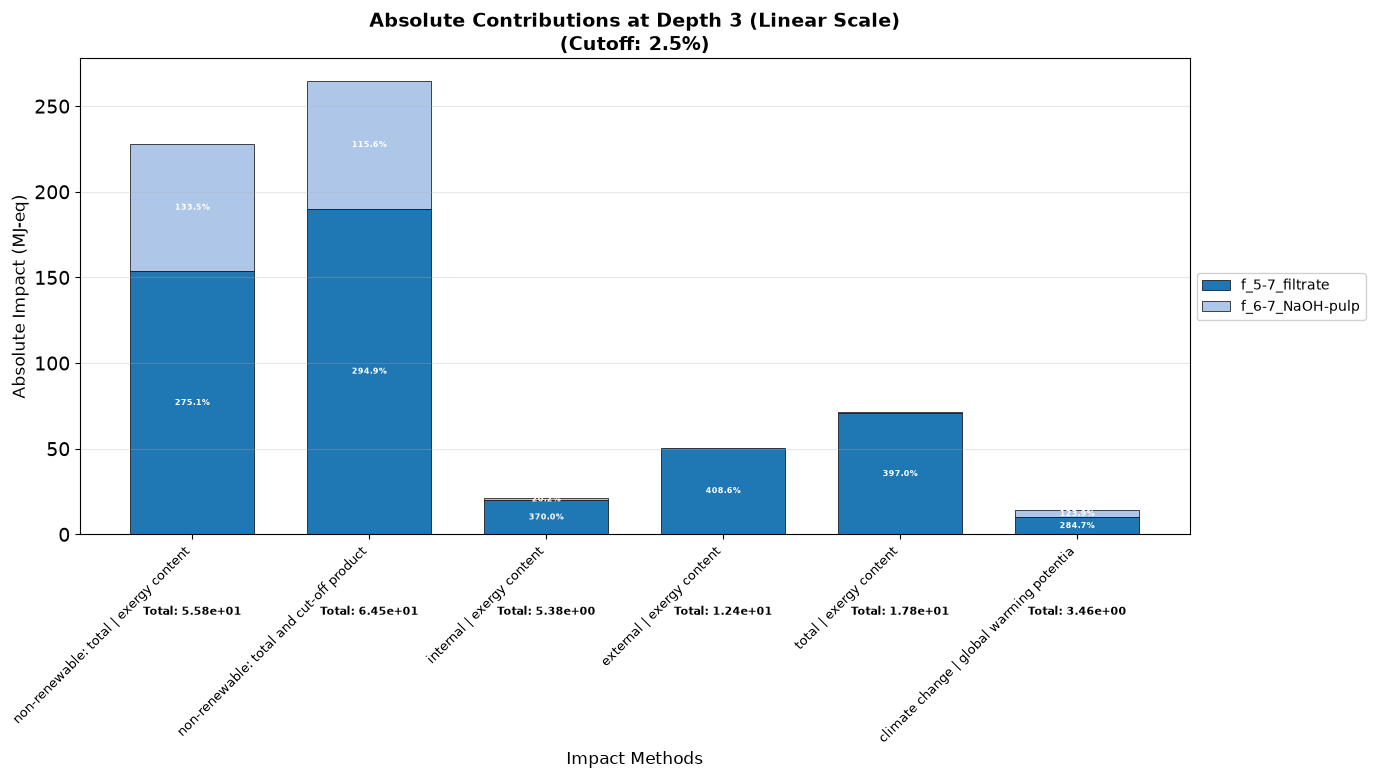


Plot saved to bw25_absolute_linear_depth_3.svg


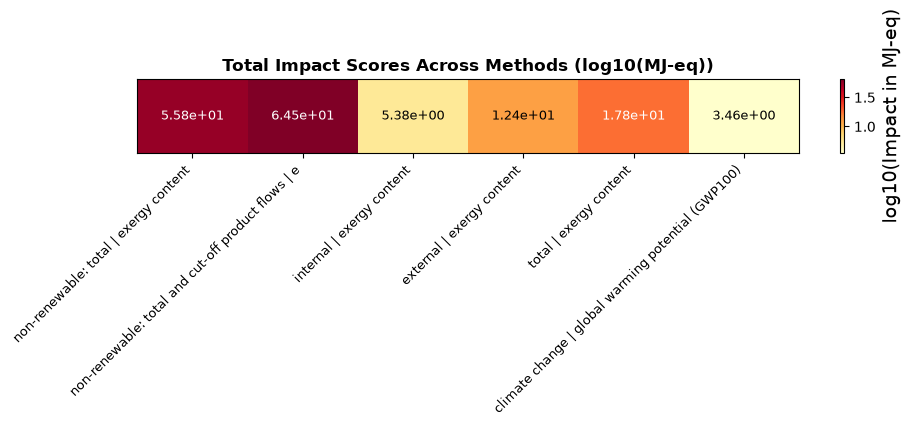


Plot saved to bw25_total_scores_heatmap.svg

####################################################################################################
# product-type transcription | FU: 0.514 f_11-0_Li2CO3
####################################################################################################

########################################################################################################################
# Analyzing method: non-renewable: total | exergy content
# Method key: ('Custom Cumulative Exergy Demand (CCExD)', 'non-renewable: total', 'exergy content')
########################################################################################################################

Functional Unit: f_11-0_Li2CO3 (BE)
Total non-renewable: total | exergy content score: 2.059304e+01 MJ-eq

Depth 1 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: f_11-0_Li2CO3 (BE)
Total internal | exergy content score: 2.012044e+00 MJ-eq

Depth 1 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
f_11-0_Li2CO3                                                     ?                              BE          2.0120e+00   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
------------------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: f_11-0_Li2CO3 (BE)
Total external | exergy content score: 4.353657e+00 MJ-eq

Depth 1 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
f_11-0_Li2CO3                                                     ?                              BE          4.3537e+00   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
------------------------

c:\Users\lfreboeuf\github\Resource_Assessment_Hydromet-Recycling-Case-Stuy\.venv\Lib\site-packages\bw2calc\lca.py:251: UserWarning: All values in characterization matrix are zero
  warnings.warn("All values in characterization matrix are zero")


Functional Unit: f_11-0_Li2CO3 (BE)
Total total | exergy content score: 6.365701e+00 MJ-eq

Depth 1 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
----------------------------------------------------------------------------------------------------------------------------------
f_11-0_Li2CO3                                                     ?                              BE          6.3657e+00   100.0%
                                                                                                                             ──────
                                                                                                        Total:   100.0%

Depth 2 — 0 suppliers + Rest (showing >=2.5% of total)
Activity                                                          Product                        Loc     Impact (MJ-eq)        %
---------------------------

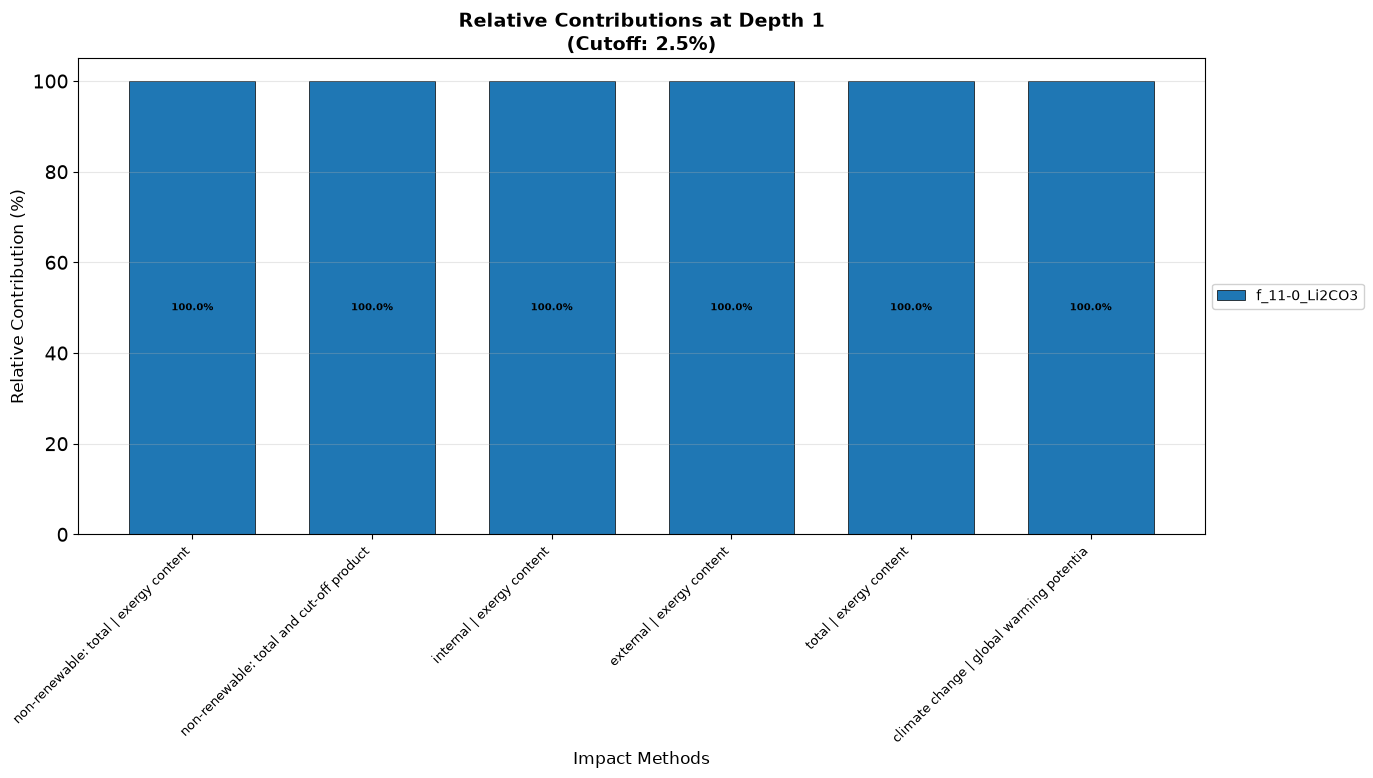


Plot saved to bw25_relative_comparison_depth_1.svg


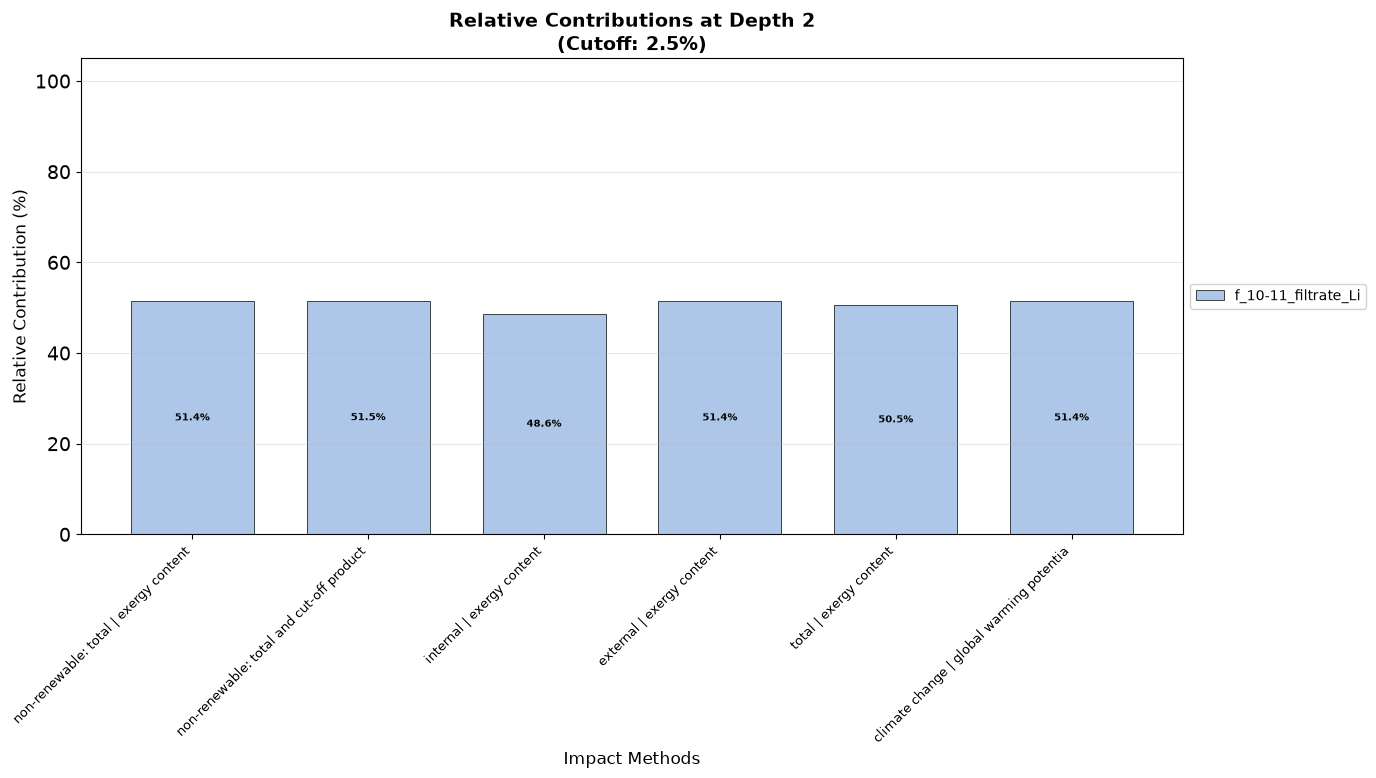


Plot saved to bw25_relative_comparison_depth_2.svg


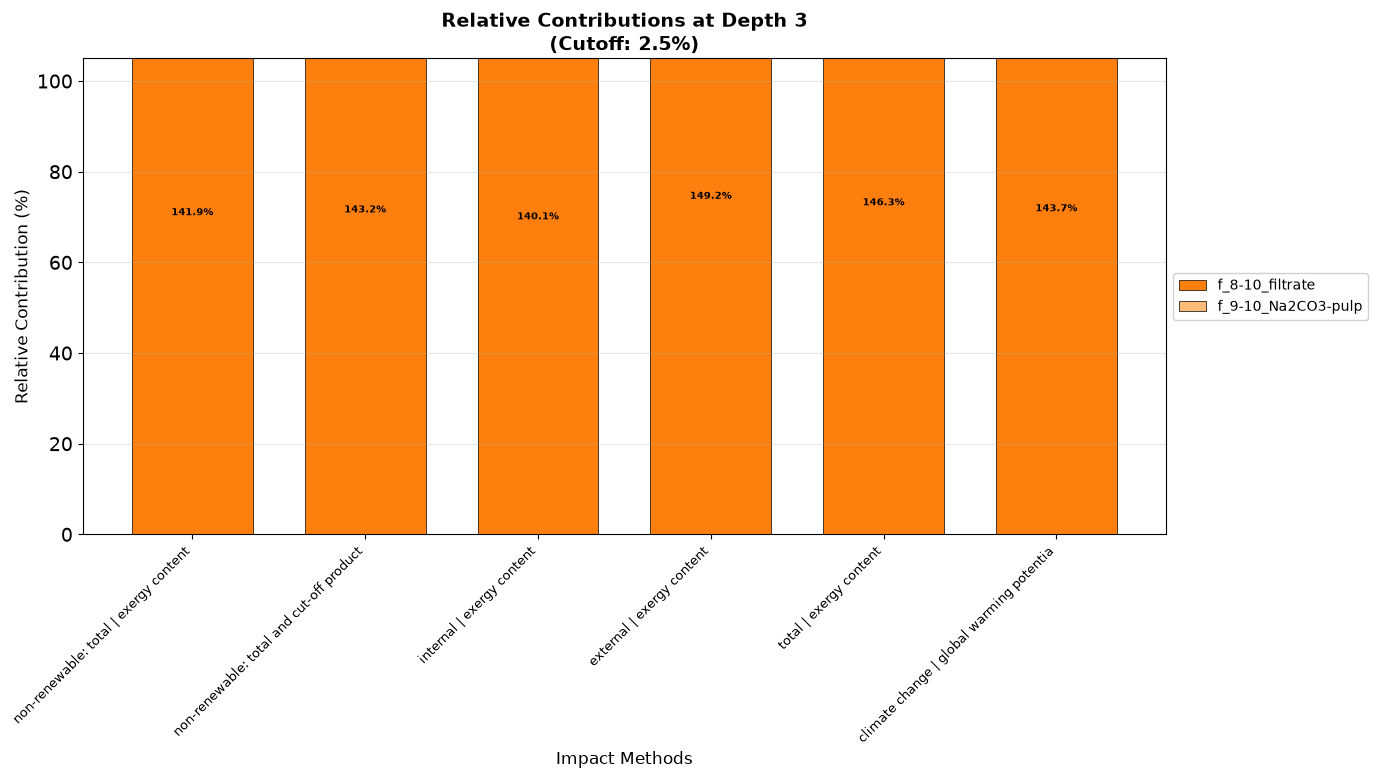


Plot saved to bw25_relative_comparison_depth_3.svg


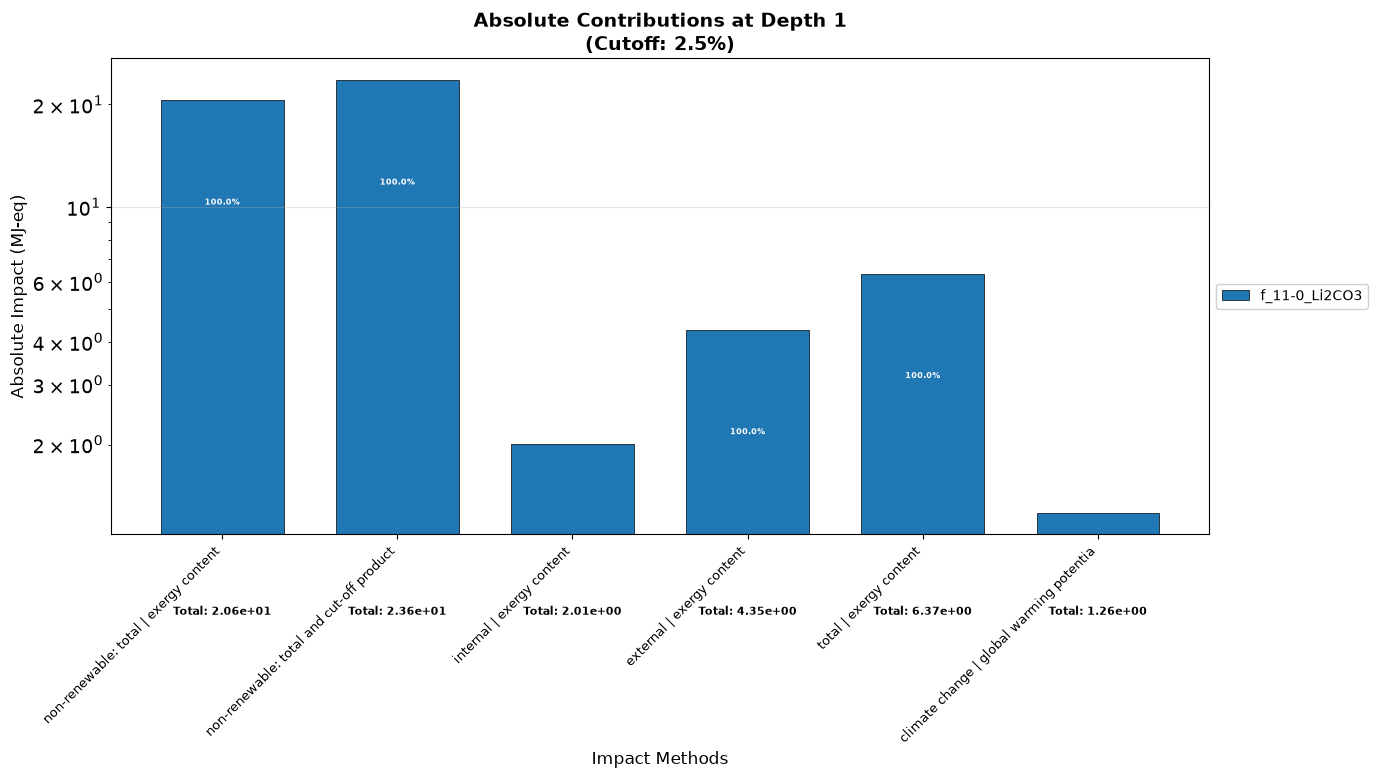


Plot saved to bw25_absolute_comparison_depth_1.svg


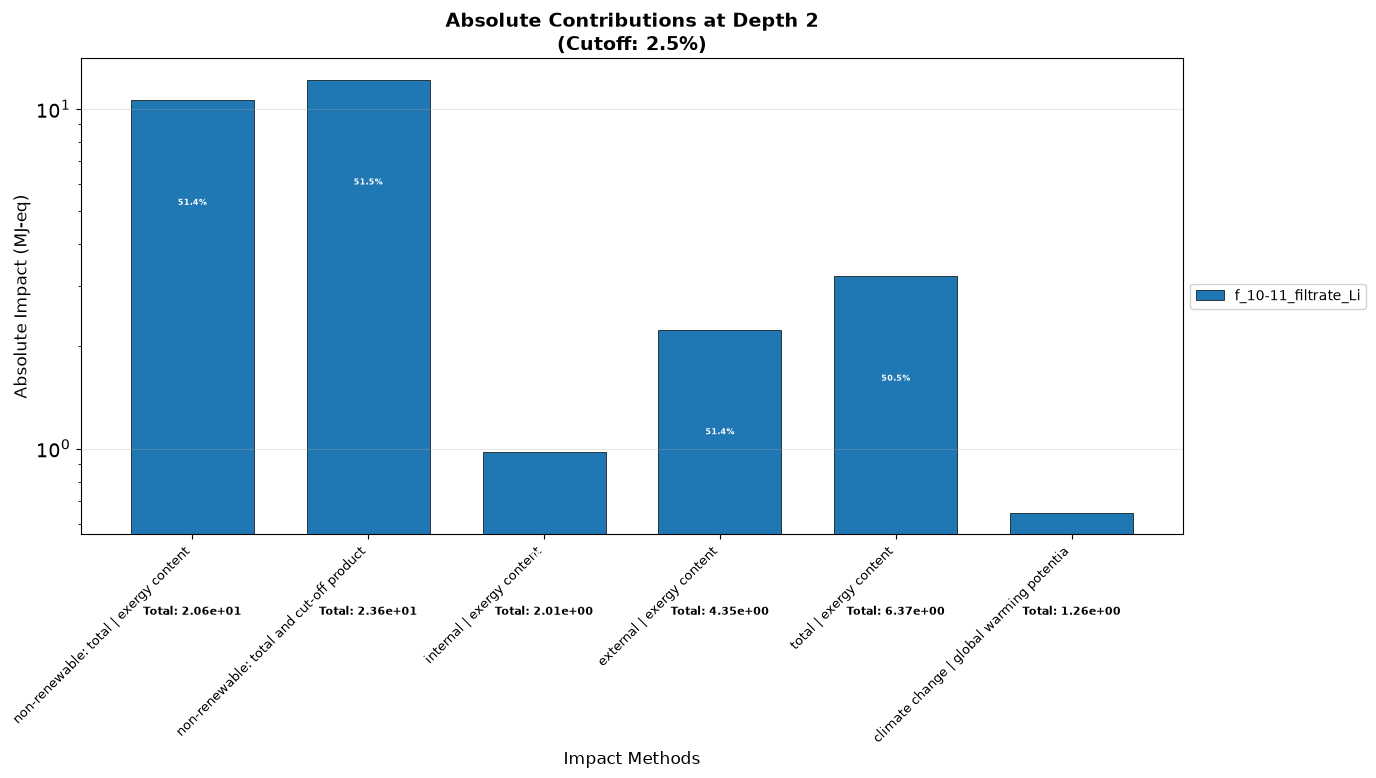


Plot saved to bw25_absolute_comparison_depth_2.svg


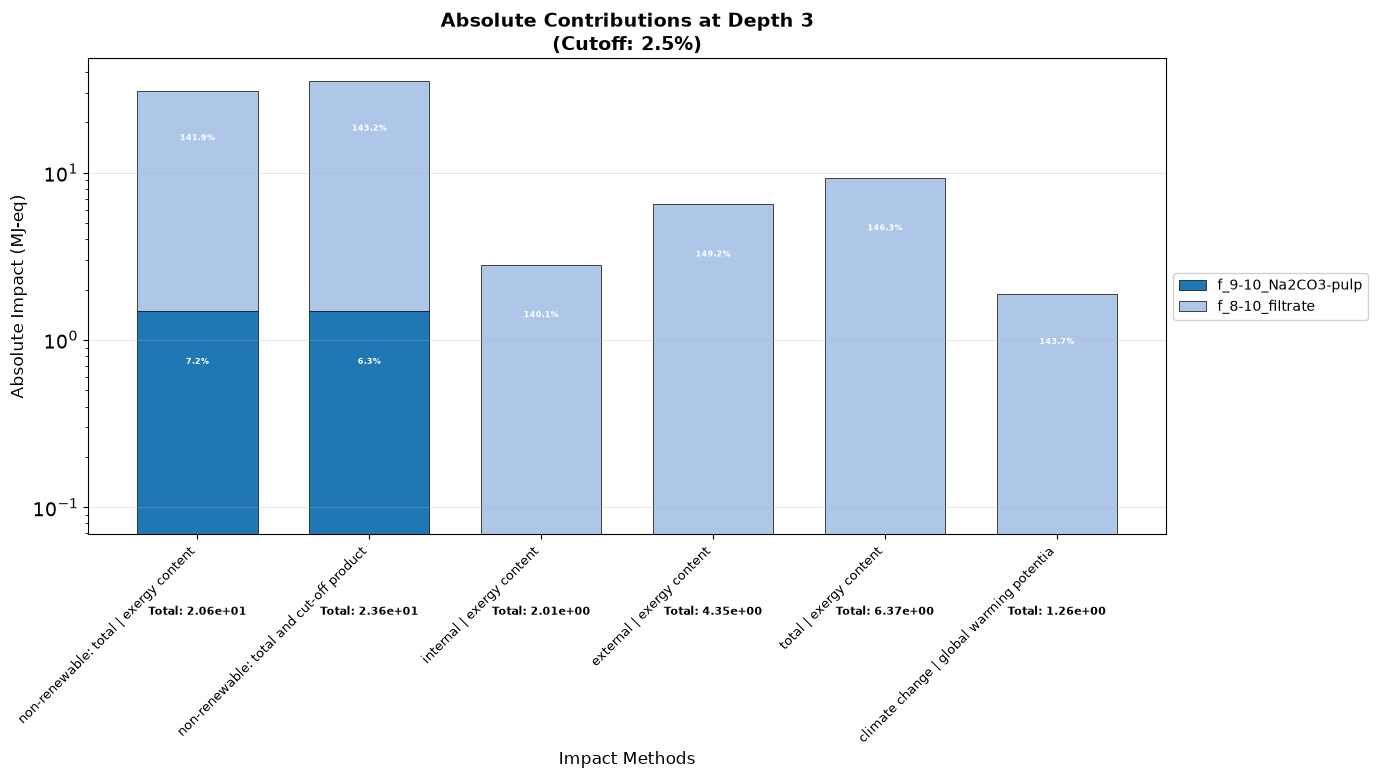


Plot saved to bw25_absolute_comparison_depth_3.svg


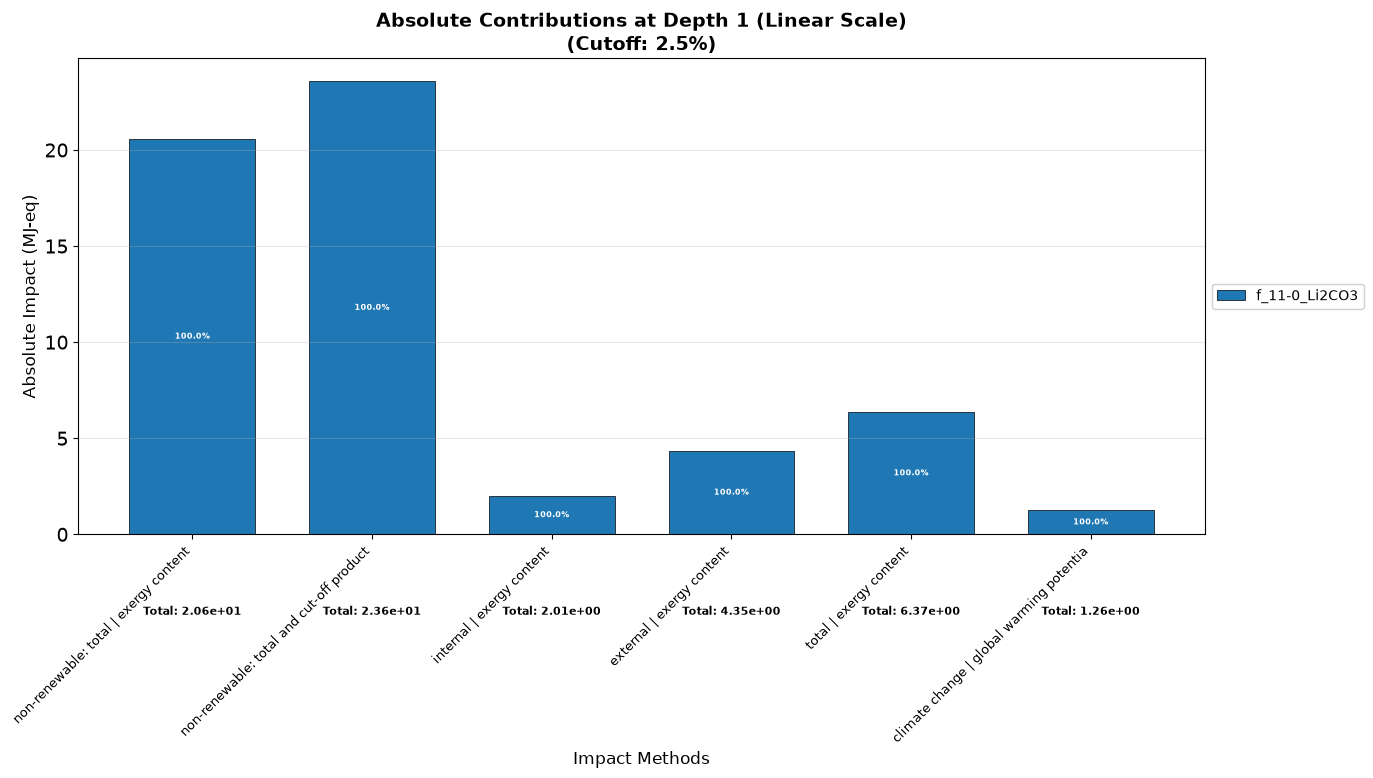


Plot saved to bw25_absolute_linear_depth_1.svg


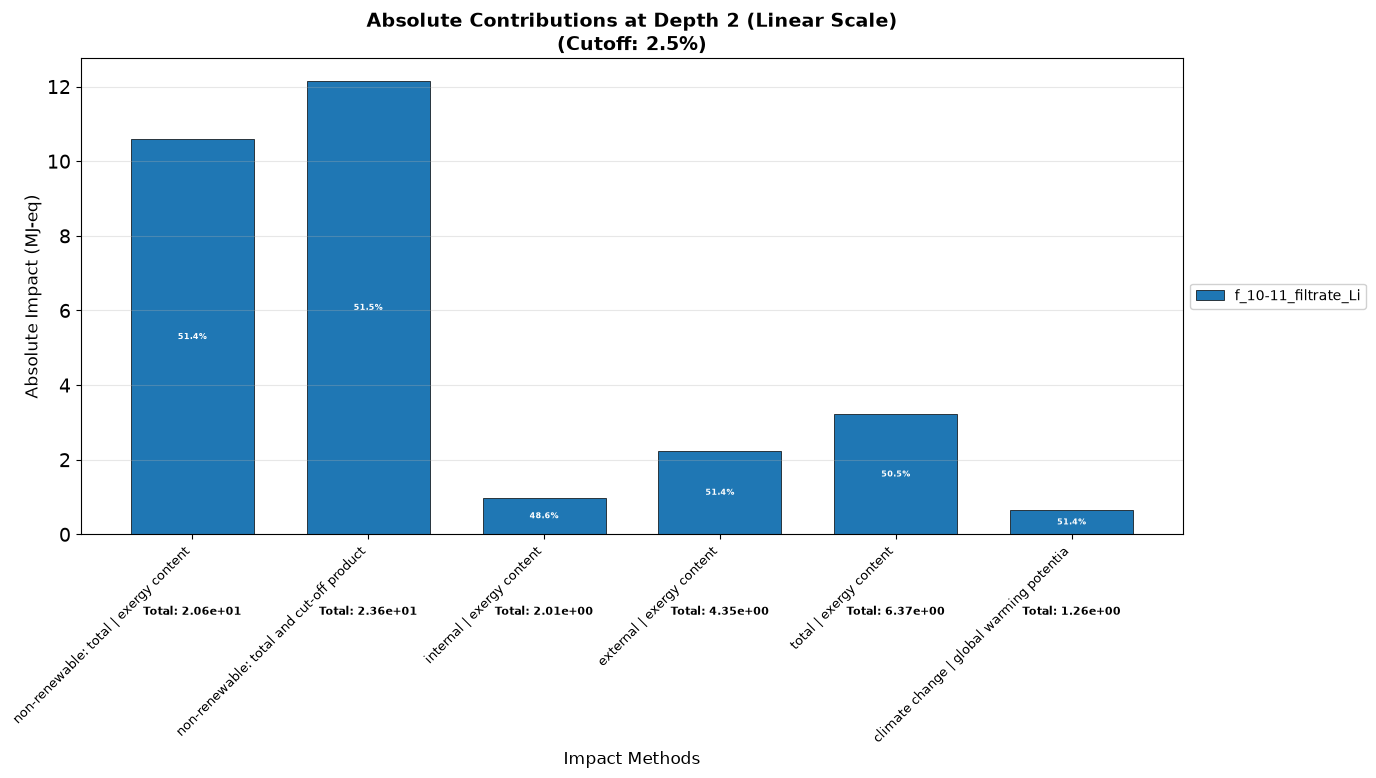


Plot saved to bw25_absolute_linear_depth_2.svg


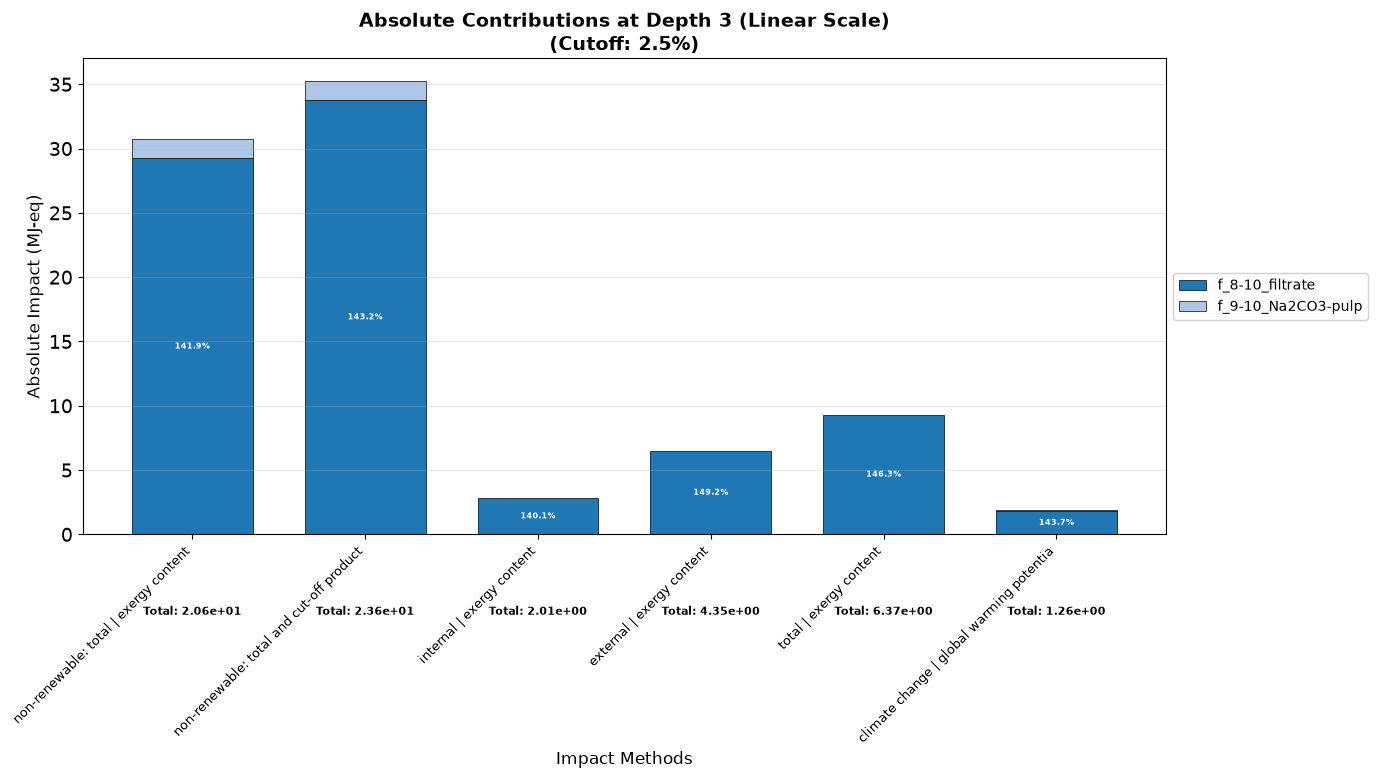


Plot saved to bw25_absolute_linear_depth_3.svg


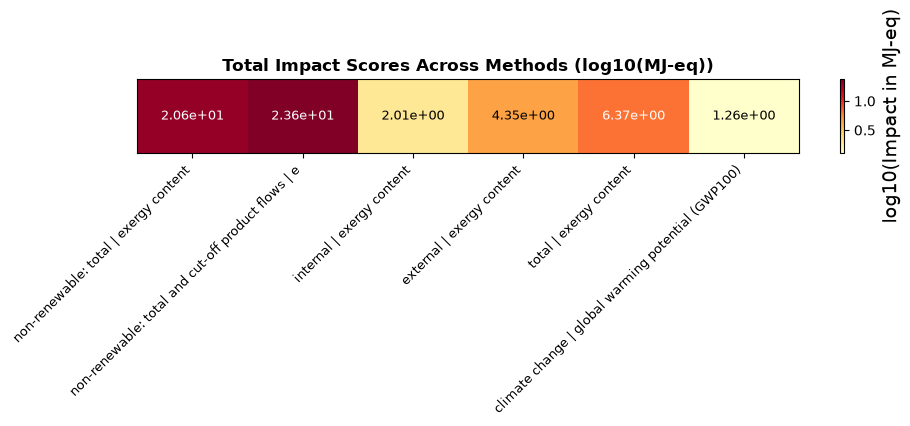


Plot saved to bw25_total_scores_heatmap.svg


In [22]:
# Contribution tree of every transcription-type FU over all methods
matplotlib.rcParams['font.size'] = 14

for (transcription, fu_name, fu_amount), demand in functional_units.items():
    fu_activity = next(iter(demand))
    print(f"\n{'#'*100}")
    print(f"# {transcription}-type transcription | FU: {fu_amount} {fu_name}")
    print(f"{'#'*100}")

    all_results, all_scores = contribution_tree_bw25(
        fu_activity=fu_activity,
        methods=methods_to_evaluate,
        max_depth=3,
        min_pct=2.50,
        fu_amount=fu_amount,
        legend_fontsize=10,  # Adjust this value to change legend text size
    )

# 🔚 end